# Reading an LLM's planned algorithm in words — demo notebook

**Artifact** `art_dbUtqBjT0tPf` (experiment 32, iteration 6) · **model studied** `Qwen/Qwen2.5-7B-Instruct` (bf16) ·
**instrument** the released natural-language autoencoder (NLA) pair `kitft/nla-qwen2.5-7b-L20-av` / `-ar`, which
reads the residual stream at layer 20.

**The question.** When the model writes code for an *algorithm-choice* task (several correct algorithms exist), does
its hidden state already say which algorithm it will implement before the first code token? And can a verbal edit of
that state change the choice? This belongs to a larger research question: how does algorithmic "creativity" show up
inside an LLM, and can it be influenced?

**What the artifact did** (one NVIDIA L4, about 2.9 h, about USD 2 of judge calls). The experiment has three stages,
all pre-registered in a sha256 hash chain:
1. **Behaviour.** There are 8 tasks: T1 grid path, T2 weighted shortest path, T03 k-th smallest, T05 two-sum, T06 find
   duplicate, T10 connected components, T04 substring search and R6 first/last position. Each task is prompted in four
   conditions:
   - a neutral *twin* prompt (N = 50);
   - a *ban* of the model's own default ("Do not use X", five templates W1–W5, N = 50, paired slot by slot with the
     twin);
   - a *forced* "Implement Y" prompt for every catalogue algorithm (N = 20 each);
   - for T2 only, a semantic *seed* paragraph.

   Frozen runtime-trace and AST labellers decide which algorithm each program implements.
2. **NLA readout.** The NLA's *verbaliser* (AV) turns a layer-20 state into an English explanation. States are read at
   the end of the prompt (positions SPEC-3, SPEC-2, SPEC-1, READ) and at generated tokens g1–g16. Two blind LLM judges
   map every explanation to a catalogue algorithm, with a third on disagreement. The NLA is compared with several
   baselines and controls:
   - the same judges reading only the visible text (*NAME*);
   - an outside-reader forecast (*PREDICT*);
   - swapped twin explanations;
   - explanations of random perturbations;
   - a forced-prompt positive control.
3. **Causal edit.** In an explanation, the default algorithm's name is swapped for another algorithm. The NLA's
   *reconstructor* (AR) maps both texts back to vectors, and their difference is patched into the layer-20 states.

**What this notebook runs.** The GPU stages cannot run in a Colab CPU session: generation with the 7B model, and the AV
and AR, which are two more 7B checkpoints. Neither can the OpenRouter judge calls. Their outputs are shipped in
`mini_demo_data.json`, and every CPU stage of `method.py` is re-run below with the artifact's own code:
- the behaviour report: defaults, bans, substitutes and paired flips (`src/behaviour.py`);
- the judge rubric and the J1/J2/J3 resolution rule (`src/judges.py`);
- the instrument gate, i.e. the fraction of variance the explanations carry (`src/nla_ar.py`);
- every pre-registered readout test, N1–N8b, with exact McNemar tests and a task-cluster bootstrap
  (`analysis/stats.py`, `analysis/readout.py`);
- the activation-space geometry in real layer-20 coordinates (PCA and classical MDS), with the edit and
  difference-in-means directions (`analysis/geometry.py`, `src/figures.py`, `src/nla_ar.py`);
- the re-derivation that uses only the Python standard library, with placebos (`audit/rederive.py`,
  `audit/rederive_headlines.py`).

The final section sets every recomputed number beside the value the artifact reported.

**Runtime.** About 25 seconds in a fresh environment, most of it the install cell; the analysis takes under
10 seconds. On Colab only `loguru` is installed.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab (method.py and the stage scripts log with it); always install, at the
# artifact's pinned version. torch / transformers / safetensors / openai serve only the GPU and API stages, which this
# demo replays from the shipped outputs, so they are not needed here.
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, pandas -- pre-installed on Colab; install locally only, at Colab's exact versions
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# --- the artifact's imports (method.py, src/cfg.py, src/behaviour.py, src/judges.py, src/nla_ar.py,
#     analysis/stats.py, analysis/readout.py, analysis/geometry.py, src/figures.py, audit/rederive.py) ---
import argparse
import hashlib
import json
import math
import random
import re
import subprocess
import sys
import time
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any, Callable, Sequence

import matplotlib.pyplot as plt
import numpy as np
from loguru import logger
from scipy import stats as ss

# --- added for the notebook: decoding the shipped vectors, result tables ---
import base64

import pandas as pd

print("numpy", np.__version__, "| pandas", pd.__version__, "| python", sys.version.split()[0])

numpy 2.0.2 | pandas 2.2.2 | python 3.12.14


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-6/experiment-32/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
META = data["metadata"]
EXAMPLES = data["datasets"][0]["examples"]
print(META["title"])
print("dataset:", data["datasets"][0]["dataset"], "| examples (prompt conditions):", len(EXAMPLES),
      "| states:", sum(len(e["states"]) for e in EXAMPLES), "| programs:", sum(len(e["programs"]) for e in EXAMPLES))
print("conditions per task:", dict(Counter(e["metadata_task"] for e in EXAMPLES)))
ex = next(e for e in EXAMPLES if e["metadata_task"] == "T05" and e["metadata_condition"] == "ban")
print("\nexample (T05, ban of", ex["metadata_mode"] + "): input =", repr(ex["input"][:300]), "...")
print("output (modal correct label of its 50 programs):", ex["output"])
print("fields:", [k for k in ex if not k.startswith("metadata_")])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Reading an LLM's planned algorithm in words -- demo data (artifact art_dbUtqBjT0tPf, iteration 6, experiment 32)
dataset: nla_readout_states | examples (prompt conditions): 55 | states: 2320 | programs: 1630
conditions per task: {'T1': 8, 'T2': 8, 'T03': 7, 'T05': 6, 'T06': 7, 'T10': 6, 'T04': 8, 'R6': 5}

example (T05, ban of hash_map): input = 'Do not use a hash map of seen values for this task.\n\nTask: write a Python function solve(nums, target) that returns a list [i, j] of two indices with i < j such that nums[i] + nums[j] == target. The argument nums is a list of integers with 2 <= len(nums) <= 2000 and every value between -10**9 and 10' ...
output (modal correct label of its 50 programs): brute_force
fields: ['input', 'output', 'prompts', 'states', 'text_judgements', 'programs', 'example_program_sample_id', 'example_program_code']


### The demo data

`mini_demo_data.json` holds **one dataset, `nla_readout_states`**, packed as **55 examples**. Each example is one
*prompt condition*, i.e. a (task, condition, mode) triple such as "T05, ban of the hash map". Each example carries:

- **`prompts`:** the five prompts W1–W5, each a condition sentence followed by the frozen task specification.
- **`states`:** the layer-20 states read from those prompts, in two groups:
  - *Prefill states* at SPEC-3, SPEC-2, SPEC-1 and READ. The twin group also holds the *twin + ε* random
    perturbations.
  - *Generated-token states* at g1, g2, g4, g8 and g16 of the sampled programs.

  Each state keeps its index row and its three judged explanations, each with J1/J2/J3, the resolved label and the AR
  cosine. At READ the state also ships the `hidden_states[21]` vector itself: 3,584 bf16 numbers, stored losslessly.
  These are the coordinates used for the geometry plots. The twin READ states of the four causal tasks also carry the
  NLA edit delta, plus the difference-in-means delta for W1.
- **`text_judgements`:** the text-only NAME and PREDICT judgements of the same prompts and generated prefixes.
- **`programs`:** the frozen-labeller verdict for every program the condition produced: label, pass, labeller source.
  One example program is shipped as code.

The 1,900 read-out states of the artifact's `nla_readout_states` dataset are all inside these 55 examples. The extra
states are the forced-prompt states of the other catalogue algorithms; they have vectors but were never verbalised, and
the geometry analysis needs them. The `metadata` carries the committed task tables (commits #1 and #2), the algorithm
catalogues and the artifact's own result files (`reported`). Everything below is compared against those files.

## Configuration

The parameters below only control resampling: bootstrap confidence intervals, permutation nulls, rarefaction and the
placebo. They do **not** change any point estimate or any exact McNemar test.

The cell is set to the artifact's **original values**, because the whole notebook then still runs in about 25 s. It
was also tested at the absolute minimum (one resample each, 22 s) and at intermediate values (23 s). Every
deterministic number matched at all three settings.

To get a faster look, lower the values. Only the bootstrap intervals, the Hill-1 diversities and the placebo share
change, and the final comparison skips them when the settings differ from the artifact's.

The artifact's design itself is fixed in commit #2, so it is not a tunable here: three explanations per state, majority
of three, and the thresholds. Its GPU settings appear in the `src/cfg.py` cell further down, for reference only. They
would matter only for re-running the 7B models: 1,024 / 1,536 new tokens, 64 steering steps, doses ×1/×2/×4 and 50
slots per twin.

In [5]:
# ===== Demo configuration (the artifact's original values in brackets) =====
N_BOOT = 2000           # task-cluster bootstrap resamples per paired test (analysis/stats.py)            [2000]
N_PERM_SWAP = 10000     # sign-flip permutations of the N1-swap null (analysis/readout.py)               [10000]
N_HILL_DRAWS = 1000     # rarefaction draws of the correct-only Hill-1 diversity (src/behaviour.py)      [1000]
N_PLACEBO_SWAPS = 2000  # within-pair swap permutations of the N6 placebo (audit/rederive_headlines.py)  [2000]
GEOMETRY_POSITIONS = ("READ",)  # prompt positions of analysis/geometry.py                      [("READ", "SPEC-1")]
# (the demo data ships the layer-20 vectors at READ only; the SPEC-1 vectors stay in cache/states_L20.npz on the
#  artifact's run volume)

## Step 0 — the pipeline (`method.py`)

`method.py` is the artifact's entry point. It does no computation itself. It chains the pre-registered stage
scripts, loading one GPU model at a time, and every stage can be resumed with `--from` / `--only`:

| stage | what it does | where | in this notebook |
|---|---|---|---|
| S0 | CPU labeller tests (51/51 references), dependency use, commit #0 | CPU | reported |
| S3 | generate every behaviour program: twin, engine checks, forced, seed, ban | GPU | replayed: program labels shipped |
| S3b | frozen runtime + AST labellers (sandboxed `python3.12 -I -S`) | CPU | replayed: labels shipped |
| S3c | behaviour report; style re-gate with two code judges | CPU + API | **report re-run**; re-gate reported |
| S4 | layer-20 state cache; judge calibration; commit #2 | GPU + API | READ vectors and commit #2 shipped |
| S5a | AV / AR gates: smoke tests, reference FVE, layer convention | GPU | reported |
| S5b | 6,180 AV explanations; AR gate, edits, deltas, commit #3 | GPU | explanations, AR cosines and deltas shipped; **gate, edit texts and DIM direction re-derived** |
| S7S8 | blind judges (OpenRouter), running beside the causal arm (GPU) | API + GPU | judge answers shipped, **resolution re-run**; causal arm reported |
| S8b | labels of the causal programs | CPU | reported |
| S9 | novelty audit, readout and causal analysis, figures, re-derivation, outputs | CPU (+ API) | **readout, geometry, figures and audits re-run** |

The cell below is the original `method.py`. Two things change, both because a notebook is not a script:
- `ROOT` is the working directory, since a notebook has no `__file__`.
- `main()` is defined but not called. It would launch the GPU stages, so the cell prints the stage plan instead.

In [6]:
__doc__ = """Reading the planned algorithm in words -- the full pipeline of this artifact (iteration 6, experiment 32).

Qwen/Qwen2.5-7B-Instruct (bf16) writes Python solutions to 8 algorithm-choice tasks. The released natural-language
autoencoder pair kitft/nla-qwen2.5-7b-L20-av / -ar verbalises its layer-20 states before any code token; blind judges
map every explanation to a catalogue algorithm. The METHOD is the NLA readout; its BASELINES / CONTROLS are the
text-only reader (same judges, the visible text), the outside-reader forecast (PREDICT), swapped twin explanations,
explanations of matched-norm random perturbations and the forced-prompt positive control. The causal arm patches the
difference of two AR reconstructions (edited vs unedited explanation) into the layer-20 states, against the unedited
round trip, an unrelated-word edit, a matched-norm random push and a matched-norm difference-in-means push.

Stages (one GPU model in memory at a time; every stage is its own script under src/ so it can be resumed):
  S0  src/tests_cpu.py, src/dep_usage.py, src/commit0.py          CPU tests, dependency use, commit #0
  S1-3 src/gen.py twin engine_check forced_seed ban             prompts, engine checks, behaviour (GPU)
       src/labels.py (follows data/samples_raw.jsonl)           frozen labellers (CPU, in parallel)
       src/behaviour.py defaults | report | regate              commit #1, per-task report, style re-gate
  S4  src/states.py                                             layer-20 state cache (GPU)
       src/judges.py calibrate ; src/commit2.py                 judge calibration gate, commit #2
  S5  src/nla_av.py gate ; S6 src/nla_ar.py gate                smoke tests, reference FVE, layer convention
  S5  src/nla_av.py production ; S6 src/nla_ar.py production    explanations, task gate, edits, deltas, commit #3
  S7  src/judges.py run                                         blind judges (OpenRouter; runs while S8 uses the GPU)
  S8  src/causal_gen.py + src/labels.py (labels_causal)         causal arm (GPU)
  S9  src/novelty.py ; analysis/readout.py ; analysis/causal.py ; src/figures.py ; audit/rederive.py ; src/outputs.py

Usage: python method.py [--from STAGE] [--only STAGE ...]
"""

ROOT = Path.cwd()   # original: Path(__file__).resolve().parent (a notebook has no __file__)
PY = sys.executable
STAGES: list[tuple[str, list[list[str]]]] = [
    ("S0", [["src/tests_cpu.py"], ["src/dep_usage.py"], ["src/commit0.py"]]),
    ("S3", [["src/gen.py", "twin", "engine_check", "forced_seed", "ban"]]),  # labels.py and behaviour.py defaults run beside it
    ("S3b", [["src/labels.py", "--raw", "data/samples_raw.jsonl", "--out", "data/labels.jsonl"]]),
    ("S3c", [["src/behaviour.py", "report"], ["src/behaviour.py", "regate"]]),
    ("S4", [["src/states.py"], ["src/judges.py", "calibrate"], ["src/commit2.py"]]),
    ("S5a", [["src/nla_av.py", "gate"], ["src/nla_ar.py", "gate"]]),
    ("S5b", [["src/nla_av.py", "production"], ["src/nla_ar.py", "production"]]),
    ("S7S8", [["src/causal_gen.py", "--deadline-min", "75"]]),  # src/judges.py run in parallel
    ("S8b", [["src/labels.py", "--raw", "data/samples_causal_raw.jsonl", "--out", "data/labels_causal.jsonl",
              "--name", "label_causal"]]),
    ("S9", [["src/novelty.py"], ["analysis/readout.py"], ["analysis/causal.py"], ["src/figures.py"],
            ["audit/rederive.py"], ["src/outputs.py"]]),
]


def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info(f"$ {' '.join(cmd)}")
    r = subprocess.run([PY] + cmd, cwd=ROOT)
    if r.returncode != 0:
        raise RuntimeError(f"{cmd} exited {r.returncode}")
    logger.info(f"  done in {time.time() - t0:.0f}s")


@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--from", dest="start", default="S0")
    ap.add_argument("--only", nargs="*", default=None)
    args = ap.parse_args()
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")
    names = [s for s, _ in STAGES]
    todo = args.only or names[names.index(args.start):]
    for name, cmds in STAGES:
        if name not in todo:
            continue
        if name == "S7S8":
            jp = subprocess.Popen([PY, "src/judges.py", "run"], cwd=ROOT)
            for c in cmds:
                run(c)
            jp.wait()
            continue
        for c in cmds:
            run(c)


# original: if __name__ == "__main__": main()
# main() would start every stage script: three 7B checkpoints on one >= 22 GB GPU for ~2 h, plus OpenRouter judges.
# Instead: main()'s stdout logging set-up (its file sink under logs/ is left out) and a dry run of the stage plan.
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
NOTE = {"src/tests_cpu.py": "reported (51/51 references)", "src/dep_usage.py": "reported",
        "src/commit0.py": "hash chain shipped (metadata.commitments)", "src/gen.py": "GPU -- program labels shipped",
        "src/labels.py": "sandboxed labellers -- labels shipped",
        "src/behaviour.py report": "RE-RUN below (behaviour report, F0)", "src/behaviour.py regate": "API -- reported",
        "src/states.py": "GPU -- READ vectors shipped", "src/judges.py calibrate": "API -- reported",
        "src/commit2.py": "commit #2 task table shipped", "src/nla_av.py gate": "GPU -- reported",
        "src/nla_ar.py gate": "GPU -- reported (layer convention)",
        "src/nla_av.py production": "GPU -- explanations shipped",
        "src/nla_ar.py production": "GPU -- cosines + deltas shipped; gate, edits, DIM RE-DERIVED below",
        "src/causal_gen.py": "GPU -- reported (F5, F9)", "src/novelty.py": "API -- reported",
        "analysis/readout.py": "RE-RUN below (N1-N8b, F2-F4, F7)",
        "analysis/causal.py": "needs the causal-arm labels -- reported",
        "src/figures.py": "RE-RUN below (F0-F4, F6-F8; F5/F9 from the reported numbers)",
        "audit/rederive.py": "RE-RUN below", "src/outputs.py": "bookkeeping (method_out.json)"}
print("Dry run of `python method.py` (main() not called):")
for name, cmds in STAGES:
    for c in cmds:
        print(f"  {name:<5} python {' '.join(c)[:66]:<67} -> {NOTE.get(' '.join(c[:2]), NOTE.get(c[0], ''))}")
    if name == "S7S8":
        print(f"  {'':<5} python {'src/judges.py run   (Popen, beside the causal arm)':<67} -> API -- answers shipped; "
              "resolution RE-RUN below")

Dry run of `python method.py` (main() not called):
  S0    python src/tests_cpu.py                                                    -> reported (51/51 references)
  S0    python src/dep_usage.py                                                    -> reported
  S0    python src/commit0.py                                                      -> hash chain shipped (metadata.commitments)
  S3    python src/gen.py twin engine_check forced_seed ban                        -> GPU -- program labels shipped
  S3b   python src/labels.py --raw data/samples_raw.jsonl --out data/labels.jsonl  -> sandboxed labellers -- labels shipped
  S3c   python src/behaviour.py report                                             -> RE-RUN below (behaviour report, F0)
  S3c   python src/behaviour.py regate                                             -> API -- reported
  S4    python src/states.py                                                       -> GPU -- READ vectors shipped
  S4    python src/judges.py calib

## Constants (`src/cfg.py`)

These are the design constants that every stage shares. The positions follow `cfg.py`'s own conventions:
- **Layer.** Block *l* is decoder block *l* (0-based), and its output is `hidden_states[l + 1]`. The NLA checkpoint was
  trained on the output of block 20, i.e. `hidden_states[21]` (`hs21`). A pre-registered check chose this over the
  README snippet's `hidden_states[20]`.
- **Positions.** They are counted from the end of a prompt of P tokens:
  - **READ** = P − 1, the newline after `<|im_start|>assistant`, i.e. the state right before the first answer token;
  - **SPEC-1, SPEC-2, SPEC-3** = P − 6, P − 7, P − 8, the last three user-content tokens. Every prompt ends with
    "…and no explanation.", so these are `.`, ` explanation` and ` no`.
- **CRN slots.** A slot is (task, template, k), and its uniform random stream is shared by every arm. The twin and the
  ban sample of a slot are therefore paired: common random numbers.

The file and path helpers of `cfg.py` are left out, along with logging, RAM limits and the JSON writers, because the
notebook works in memory. The GPU-side values are kept for reference.

In [7]:
# ------------------------------------------------------------------------------------------------ models
MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
MODEL_REVISION = "a09a35458c702b33eeacc393d103063234e8bc28"
AV_ID = "kitft/nla-qwen2.5-7b-L20-av"
AV_REVISION = "b88469162777ae6553bc14208eb0cb579336f8f4"
AR_ID = "kitft/nla-qwen2.5-7b-L20-ar"
AR_REVISION = "e2c9e57eac213d37a31612087f645ab6332c1bb6"
N_LAYERS = 28
D_MODEL = 3584
IM_END = 151645
ENDOFTEXT = 151643
EOS_IDS = (IM_END, ENDOFTEXT)
MAX_NEW_TOKENS = 1024
MAX_NEW_PATH = 1536
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n"
ENGINE_TAG = "bf16-hf"
PRECISION = "bf16"
LAYER_CONVENTIONS = {"hs20": 20, "hs21": 21}  # hidden_states index -> hooked block = index - 1
EXTRACTION_LAYER = 20

# ------------------------------------------------------------------------------------------------ tasks
PATH_TASKS = ("T1", "T2")
BENCH_TASKS = ("T03", "T05", "T06", "T10", "T04", "R6")
TASKS = ("T1", "T2", "T03", "T05", "T06", "T10", "T04", "R6")
EXP8_TASK = {"T1": "t1", "T2": "t2"}
# the earlier family's (Qwen3-8B) defaults; used only to pick the twin's neutral noun before this model's default
# is known (protocol: the twin is token-length matched to the ban of the prior default)
PRIOR_DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set",
                 "T05": "hash_map", "T10": "union_find", "R6": "binary_search"}
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) -- protocol v2 W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
PAD_FILLER = " ."
N_FORCED_PARAPHRASES = 5

# ------------------------------------------------------------------------------------------------ design
TWIN_SLOTS = list(range(10))          # k 0-9 per template -> N = 50
EXTRA_TWIN_SLOTS = list(range(10, 20))  # NO-DEFAULT tasks: the ban's 50 samples go to twin slots 10-19
FORCED_SLOTS = list(range(4))         # 5 paraphrases x 4 slots = 20 per catalogue Y
CAUSAL_SLOTS = list(range(6))         # W1-W5 x slots 0-5 = 30 per cell
GEN_POSITIONS = (1, 2, 4, 8, 16)      # generated-token read positions g1..g16 (1-based generated index)
PREFILL_POS = ("SPEC-3", "SPEC-2", "SPEC-1", "READ")
POS_OFFSET = {"READ": 1, "SPEC-1": 6, "SPEC-2": 7, "SPEC-3": 8}  # index = P - offset
DOSES = (1.0, 2.0, 4.0)
GEN_STEPS = 64                        # GEN site: READ's delta added at READ and generated positions 1-64
DEFAULT_SHARE = 0.6
YSTAR_SHARE = 0.5
YSTAR_MIN = 10
MIXED_SHARE = 0.2
ADHERENT_MIN = 0.7
FVE_PASS = 0.60
FVE_PARTIAL = 0.50
FVE_REF_TARGET = 0.752
FVE_TRAIN_DENOM = 0.7335              # Var(v_nrm) of the training mix (examples/qwen7b_layer20_step4200.txt)
JUDGE_CAP_USD = 2.2
CODE_JUDGE_CAP_USD = 0.6
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
BOOT_SEED = 20261022
# N_BOOT = 2000  -> the bootstrap size is set in the configuration cell above
DEPTH = 25
GENESIS = hashlib.sha256(b"iter6_dir6").hexdigest()


# ------------------------------------------------------------------------------------------------ utils
def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


print("tasks:", TASKS, "| prefill positions:", PREFILL_POS, "| generated positions:", GEN_POSITIONS)
print("ban templates:", {w: b for w, (b, _) in TEMPLATES.items()})

tasks: ('T1', 'T2', 'T03', 'T05', 'T06', 'T10', 'T04', 'R6') | prefill positions: ('SPEC-3', 'SPEC-2', 'SPEC-1', 'READ') | generated positions: (1, 2, 4, 8, 16)
ban templates: {'W1': 'Do not use {X} for this task.', 'W2': 'Your solution must not rely on {X}.', 'W3': 'Avoid {X} entirely.', 'W4': '{X} is not allowed here.', 'W5': 'Write a correct solution that does not use {X}.'}


## Rebuilding the artifact's tables from the demo data

The analysis scripts read their inputs from files. The cell below rebuilds the same rows, with the same field names,
from the 55 examples:

| file in the artifact | rebuilt here as | content |
|---|---|---|
| `cache/states_index.jsonl` | `IDX` | one row per state; `row` indexes `H21` (READ states only) |
| `data/explanations.jsonl` | `EXPL` | explanation #1–#3 of every read-out state (+ #4–#6 of the edit pool) |
| `data/judgements.jsonl` | `JUD` | 5,700 EXPL items + 1,320 NAME + 1,320 PREDICT items |
| `results/explanation_cosines.json` | `COS` | cos(AR(explanation), h) per explanation |
| `data/labels.jsonl` | `LABELS` | 1,630 behaviour programs (twin, ban, forced, seed) |
| `data/prompts_*.jsonl` | `PROMPTS` | every prompt's text (built as in `src/prompts.py`: segment + blank line + spec) |
| `cache/states_L20.npz` (`H21`) | `H21` | the layer-20 READ vectors of every prefill prompt and of the twin + ε states |
| `cache/deltas.npz` | `DELTAS` | NLA edit deltas (READ, causal tasks) and the W1 difference-in-means deltas |

In [8]:
C1 = META["commit1_defaults"]          # predictions/commit1_defaults.json (commit #1: this model's defaults)
C2 = META["commit2_readout"]           # predictions/commit2_readout.json (commit #2: task table, lexicon, causal plan)
CATALOGUE = META["catalogue"]          # src/prompts.py catalogue(task): ids, display names, mechanisms, aliases
SPEC = META["spec_text"]               # src/prompts.py spec_text(task): the frozen task specification
REPORTED = META["reported"]            # the artifact's results/*.json, for the comparisons
LAYER_CONVENTION = REPORTED["layer_convention"]


def decode_state(s: dict[str, Any]) -> np.ndarray | None:
    """Layer-20 vector of a shipped READ state: bf16 bit patterns (exact), or float16 for the twin + eps states."""
    if "h21_bf16_b64" in s:
        bits = np.frombuffer(base64.b64decode(s["h21_bf16_b64"]), dtype="<u2").astype(np.uint32) << 16
        return bits.view(np.float32)
    if "h21_f16_b64" in s:
        return np.frombuffer(base64.b64decode(s["h21_f16_b64"]), dtype="<f2").astype(np.float32)
    return None


IDX: list[dict[str, Any]] = []
EXPL: list[dict[str, Any]] = []
JUD: list[dict[str, Any]] = []
LABELS: list[dict[str, Any]] = []
PROMPTS: list[dict[str, Any]] = []
COS: dict[str, float] = {}
DELTAS: dict[str, np.ndarray] = {}
_vectors: list[np.ndarray] = []
for example in EXAMPLES:
    t = example["metadata_task"]
    for w, p in example["prompts"].items():
        PROMPTS.append({"task": t, "kind": example["metadata_condition"], "w": w, "mode": example["metadata_mode"], **p,
                        "user_text": p["segment"] + "\n\n" + SPEC[t]})        # = src/prompts.py record()
    for s in example["states"]:
        r = {k: v for k, v in s.items() if k not in ("explanations", "h21_bf16_b64", "h21_f16_b64", "deltas_f32_b64")}
        v = decode_state(s)
        r["row"] = None if v is None else len(_vectors)
        if v is not None:
            _vectors.append(v)
        IDX.append(r)
        for e in s["explanations"]:
            eid = f"{s['state_id']}|hs21#{e['idx']}"
            COS[eid] = e["ar_cos"]
            EXPL.append({"expl_id": eid, "state_id": s["state_id"], "idx": e["idx"], "kind": s["kind"], "task": t,
                         "condition": s["condition"], "position": s["position"], "pos_class": s["pos_class"],
                         "text": e.get("text")})
            if e.get("judged", True):
                JUD.append({"item_id": f"EXPL|{eid}", "mode": "EXPL", "task": t, "state_id": s["state_id"],
                            "expl_id": eid, "text_id": None, "J1": e["J1"], "J2": e["J2"], "J3": e["J3"],
                            "resolved": e["resolved"], "mentioned_any": e["mentioned_any"]})
        for k, b in s.get("deltas_f32_b64", {}).items():
            DELTAS[f"{k}|{t}|TWIN|{s['template']}|READ"] = np.frombuffer(base64.b64decode(b), dtype="<f4").copy()
    for j in example["text_judgements"]:
        JUD.append({"item_id": f"{j['mode']}|{j['text_id']}", "task": t, "state_id": None, "expl_id": None, **j})
    LABELS.extend(example["programs"])
H21 = np.stack(_vectors)   # hidden_states[21] (= output of block 20) at READ, float32

print("states by kind:", dict(Counter(r["kind"] for r in IDX)), "| read-out states:", sum(r["in_readout"] for r in IDX))
print("judgement items by mode:", dict(Counter(j["mode"] for j in JUD)))
print("programs by arm:", dict(Counter(r["arm"] for r in LABELS)))
print(f"H21: {H21.shape} ({H21.dtype}), mean ||h|| {np.linalg.norm(H21, axis=1).mean():.1f} | deltas: {len(DELTAS)} | "
      f"AR cosines: {len(COS)} | prompts: {len(PROMPTS)}")

states by kind: {'GEN': 1150, 'PREFILL': 1100, 'RAND': 70} | read-out states: 1900
judgement items by mode: {'EXPL': 5700, 'NAME': 1320, 'PREDICT': 1320}
programs by arm: {'BAN': 350, 'FORCED': 780, 'TWIN': 450, 'SEED': 50}
H21: (310, 3584) (float32), mean ||h|| 110.0 | deltas: 24 | AR cosines: 5760 | prompts: 275


### What a prompt, a state and an explanation look like

Here is the T05 ban prompt, template W1. It is the only task where the ban yields a substitute: the model switches from
the hash map to a brute-force double loop.

Below it are the three explanations the AV wrote for its READ state, the state just before the first answer token. A
judge label of `none_named` means the explanation names no algorithm as planned. These end-of-prompt explanations
describe the format line ("no explanation", "a Python code block follows") and invent unrelated tasks. That is the
artifact's central null result.

The third block shows a generated-token state, read after the model has already written a few tokens. Here the NLA
sometimes does name the algorithm.

In [9]:
JUD_BY_EXPL = {j["expl_id"]: j for j in JUD if j["mode"] == "EXPL"}
EXPL_BY_STATE: dict[str, list[dict[str, Any]]] = defaultdict(list)
for e in EXPL:
    EXPL_BY_STATE[e["state_id"]].append(e)
IDX_BY_ID = {r["state_id"]: r for r in IDX}


def show_state(sid: str, n_chars: int = 420, only_judged: bool = True) -> None:
    r = IDX_BY_ID[sid]
    extra = f", generated prefix {r['prefix_text']!r}" if r.get("prefix_text") is not None else ""
    print(f"--- state {sid}  (kind {r['kind']}, ||h21|| = {r['norm_h21']:.1f}{extra})")
    for e in sorted(EXPL_BY_STATE[sid], key=lambda e: e["idx"]):
        j = JUD_BY_EXPL.get(e["expl_id"])
        if j is None and only_judged:
            continue
        lab = (f"J1 {(j['J1'] or {}).get('planned')} | J2 {(j['J2'] or {}).get('planned')} | "
               f"J3 {(j['J3'] or {}).get('planned', '-')} -> resolved '{j['resolved']}', mentioned {j['mentioned_any']}"
               ) if j else "not judged (edit pool)"
        print(f"  #{e['idx']}  AR cos {COS[e['expl_id']]:.3f}; {lab}")
        if e.get("text"):
            txt = e["text"].replace("\n", " ")
            print("      " + txt[:n_chars] + (" ..." if len(txt) > n_chars else ""))


p = next(p for p in PROMPTS if p["task"] == "T05" and p["kind"] == "ban" and p["w"] == "W1")
print("T05 ban, W1 -- the user turn (Qwen2.5's chat template adds its default system message):\n")
print(p["user_text"])
print(f"\nP = {p['P']} tokens; read positions {p['pos_idx']}\n")
show_state("T05|ban|hash_map|W1|READ")
print()
show_state("T1|forced|bfs|W1|READ", n_chars=300)
print()
gen = next(r for r in IDX if r["kind"] == "GEN" and r["task"] == "T06" and r["position"] == "g4"
           and any(e.get("text") for e in EXPL_BY_STATE[r["state_id"]]))
show_state(gen["state_id"], n_chars=1200)
print("the realised program of that sample:", next(l for l in LABELS if l["sample_id"] == gen["sample_id"])["label"])
ex05 = next(e for e in EXAMPLES if e["metadata_task"] == "T05" and e["metadata_condition"] == "ban")
prog = next(l for l in ex05["programs"] if l["sample_id"] == ex05["example_program_sample_id"])
print(f"\nan example T05-ban program ({prog['sample_id']}; frozen label '{prog['label']}', passed {prog['passed']}):\n")
print("\n".join((ex05["example_program_code"] or "").splitlines()[:16]))

T05 ban, W1 -- the user turn (Qwen2.5's chat template adds its default system message):

Do not use a hash map of seen values for this task.

Task: write a Python function solve(nums, target) that returns a list [i, j] of two indices with i < j such that nums[i] + nums[j] == target. The argument nums is a list of integers with 2 <= len(nums) <= 2000 and every value between -10**9 and 10**9 inclusive; target is an integer. Each input has exactly one pair of indices whose values add up to target, so the answer is unique. The two indices must be different positions, although the values at them may be equal.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

P = 192 tokens; read positions {'READ': 191, 'SPEC-1': 186, 'SPEC-2': 185, 'SPEC-3': 184}

--- state T05|ban|hash_map|W1|READ  (kind PREFILL, ||h21|| = 107.5)
  #1  AR cos 0.865; J1 none_named | J2 none_named | J3 - -> res

## Behaviour (`src/behaviour.py`)

These are the S3 bookkeeping rules, applied to the frozen labels. The functions are unchanged; only three things
differ:
- `load_labels()` reads the rebuilt `LABELS` instead of `data/labels.jsonl`;
- `stage_defaults()` returns its table instead of hash-chaining it into `commitments.log` (commit #1);
- the catalogue comes from the demo data instead of `src/prompts.py`.

The rules:
- **Default (commit #1).** The modal *correct* twin label, if its share is at least 0.6. T03 has none.
- **Substitute Y\*.** Under the ban, the most common correct non-default label, if it is at least half of the correct
  ban programs and at least 10 of them.
- **MIXED condition.** At least 20% of the correct programs use a non-modal algorithm.
- **Forced adherence.** The share of "Implement Y" programs that are correct *and* implement Y.
- **Paired flips.** Twin label → ban label on the same CRN slot.
- **Hill-1 diversity.** The exponential Shannon diversity of the correct labels, rarefied to depth 25. It uses
  `N_HILL_DRAWS` draws; the original used 1,000.

In [10]:
def load_labels(arms: tuple[str, ...] | None = None) -> list[dict[str, Any]]:
    rows = {r["sample_id"]: r for r in LABELS}   # original: read_jsonl(LABELS) -- data/labels.jsonl
    out = list(rows.values())
    if arms:
        out = [r for r in out if r["arm"] in arms]
    return out


def correct(r: dict[str, Any]) -> bool:
    return bool(r.get("passed")) and bool(r.get("valid"))


def hill1_rarefied(labels: list[str], depth: int = DEPTH, n_draw: int = N_HILL_DRAWS, seed: int = 0) -> float | None:
    # original default: n_draw=1000
    if not labels:
        return None
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    d = min(depth, len(arr))
    vals = []
    for _ in range(n_draw):
        sub = rng.choice(arr, size=d, replace=False)
        c = np.array(list(Counter(sub.tolist()).values()), dtype=float)
        p = c / c.sum()
        vals.append(math.exp(-(p * np.log(p)).sum()))
    return float(np.mean(vals))


def composition(rows: list[dict[str, Any]]) -> dict[str, Any]:
    cor = [r["label"] for r in rows if correct(r)]
    att = [r["label"] for r in rows]
    return {"n": len(rows), "n_correct": len(cor), "pass_rate": len(cor) / len(rows) if rows else None,
            "correct": dict(Counter(cor).most_common()), "attempted": dict(Counter(att).most_common()),
            "n_other": sum(l == "other" for l in att), "n_invalid": sum(l == "invalid" for l in att),
            "hill1_d25": hill1_rarefied(cor, seed=len(cor)), "hill1_flag_lt25": len(cor) < DEPTH}


def stage_defaults() -> dict[str, Any]:
    rows = load_labels(("TWIN",))
    out: dict[str, Any] = {"rule": f"DEFAULT := modal correct twin label if share >= {DEFAULT_SHARE}", "tasks": {}}
    for t in TASKS:
        rs = [r for r in rows if r["task"] == t and int(r["slot"]) < 10]
        comp = composition(rs)
        cor = Counter(r["label"] for r in rs if correct(r))
        D, share = None, None
        if cor:
            m, c = cor.most_common(1)[0]
            share = c / sum(cor.values())
            D = m if (share >= DEFAULT_SHARE and m not in ("other", "invalid")) else None
        minority = 1 - share if share is not None else None
        out["tasks"][t] = {"default": D, "modal_share": share, "n_twin": len(rs), "composition": comp,
                           "mixed": bool(minority is not None and minority >= MIXED_SHARE)}
    # original: rec = commit("commit1_defaults", out) -- hash-chains the table into commitments.log (commit #1)
    logger.info(f"commit1: {json.dumps({t: (v['default'], round(v['modal_share'] or 0, 2)) for t, v in out['tasks'].items()})}")
    return out   # original: return rec


def per_task_report() -> dict[str, Any]:
    c1 = C1   # original: read_json(PRED_DIR / "commit1_defaults.json")
    rows = load_labels()
    rep: dict[str, Any] = {"tasks": {}}
    for t in TASKS:
        D = c1["tasks"][t]["default"]
        tw = [r for r in rows if r["task"] == t and r["arm"] == "TWIN" and int(r["slot"]) < 10]
        tw_extra = [r for r in rows if r["task"] == t and r["arm"] == "TWIN" and int(r["slot"]) >= 10]
        bn = [r for r in rows if r["task"] == t and r["arm"] == "BAN"]
        fo = [r for r in rows if r["task"] == t and r["arm"] == "FORCED"]
        sd = [r for r in rows if r["task"] == t and r["arm"] == "SEED"]
        cat = [c["mode"] for c in CATALOGUE[t]]   # original: PR.catalogue(t) (src/prompts.py)
        R: dict[str, Any] = {"default": D, "twin": composition(tw), "twin_extra_slots": composition(tw_extra) if tw_extra else None}
        if bn:
            R["ban"] = composition(bn)
            R["ban_noW4"] = composition([r for r in bn if r["template"] != "W4"])
            R["ban_W4"] = composition([r for r in bn if r["template"] == "W4"])
            R["ban_by_template"] = {w: composition([r for r in bn if r["template"] == w]) for w in TEMPLATE_IDS}
            cb = [r for r in bn if correct(r)]
            # catalogue-only ban avoidance: share of correct ban programs whose label is a catalogue mode other than D
            R["ban_avoidance_catalogue"] = (sum(r["label"] in cat and r["label"] != D for r in cb) / len(cb)) if cb else None
            R["ban_default_rate_attempted"] = sum(r["label"] == D for r in bn) / len(bn)
            nd = Counter(r["label"] for r in cb if r["label"] != D and r["label"] not in ("other", "invalid"))
            ystar = None
            if nd:
                m, c = nd.most_common(1)[0]
                if c / len(cb) >= YSTAR_SHARE and c >= YSTAR_MIN:
                    ystar = m
            R["Ystar"] = ystar
            R["Ystar_count"] = nd.most_common(1)[0][1] if nd else 0
            R["Ystar_share_of_correct_ban"] = (nd.most_common(1)[0][1] / len(cb)) if (nd and cb) else None
            R["ban_failure"] = ystar is None
            labs = Counter(r["label"] for r in cb)
            R["ban_mixed"] = bool(cb and (1 - labs.most_common(1)[0][1] / len(cb)) >= MIXED_SHARE)
            # paired twin/ban flips on the same CRN slots
            tmap = {(r["template"], int(r["slot"])): r for r in tw}
            R["paired_flip"] = Counter(f"{tmap[(r['template'], int(r['slot']))]['label']}->{r['label']}"
                                       for r in bn if (r["template"], int(r["slot"])) in tmap).most_common(12)
        adh = {}
        for m in cat:
            fr = [r for r in fo if r.get("mode") == m]
            adh[m] = {"n": len(fr), "adherence": (sum(correct(r) and r["label"] == m for r in fr) / len(fr)) if fr else None,
                      "pass_rate": (sum(correct(r) for r in fr) / len(fr)) if fr else None,
                      "labels": dict(Counter(r["label"] for r in fr).most_common())}
        R["forced"] = adh
        if sd:
            R["seed"] = composition(sd)
        rep["tasks"][t] = R
    return rep


DEF1 = stage_defaults()
REP = per_task_report()   # original stage_report() adds batch_invariance() + engine_check.json, then writes behaviour.json
for t, R in REP["tasks"].items():
    logger.info(f"{t}: default={R['default']} twin={R['twin']['correct']} pass={R['twin']['pass_rate']:.2f}; "
                f"Y*={R.get('Ystar')} ban={R.get('ban', {}).get('correct')}")

rows = []
for t, R in REP["tasks"].items():
    b = R.get("ban") or {}
    rows.append({"task": t, "default (commit #1)": DEF1["tasks"][t]["default"],
                 "modal share": round(DEF1["tasks"][t]["modal_share"], 2), "twin pass": R["twin"]["pass_rate"],
                 "ban: attempts using default": R.get("ban_default_rate_attempted"),
                 "W4 ban: attempts using default": (R["ban_W4"]["attempted"].get(R["default"], 0) / R["ban_W4"]["n"]) if b else None,
                 "Y* under ban": R.get("Ystar"), "top paired flips": ", ".join(f"{k} {v}" for k, v in (R.get("paired_flip") or [])[:3])})
pd.DataFrame(rows).set_index("task")

13:00:41|INFO   |commit1: {"T1": ["bfs", 1.0], "T2": ["dijkstra", 0.88], "T03": [null, 0.4], "T05": ["hash_map", 0.98], "T06": ["hash_set", 0.71], "T10": ["dfs", 0.62], "T04": ["naive", 1.0], "R6": ["binary_search", 1.0]}


13:00:41|INFO   |T1: default=bfs twin={'bfs': 13} pass=0.26; Y*=None ban={'bfs': 4, 'dfs': 3}


13:00:41|INFO   |T2: default=dijkstra twin={'dijkstra': 38, 'bf_spfa': 5} pass=0.86; Y*=None ban={'dijkstra': 19, 'bf_spfa': 9}


13:00:41|INFO   |T03: default=None twin={'quickselect': 19, 'size_k_heap': 16, 'heapify_pop': 5, 'full_sort': 4, 'other': 2, 'counting_sort': 1} pass=0.94; Y*=None ban=None


13:00:41|INFO   |T05: default=hash_map twin={'hash_map': 49, 'sort_two_pointers': 1} pass=1.00; Y*=brute_force ban={'brute_force': 32, 'hash_map': 14}


13:00:41|INFO   |T06: default=hash_set twin={'hash_set': 35, 'floyd': 14} pass=0.98; Y*=None ban={'hash_set': 23, 'floyd': 7, 'value_binary_search': 4}


13:00:41|INFO   |T10: default=dfs twin={'dfs': 29, 'union_find': 18} pass=0.94; Y*=None ban={'dfs': 43, 'bfs': 3, 'union_find': 2}


13:00:41|INFO   |T04: default=naive twin={'naive': 50} pass=1.00; Y*=None ban={'naive': 47, 'kmp': 1}


13:00:41|INFO   |R6: default=binary_search twin={'binary_search': 38} pass=0.76; Y*=None ban={'binary_search': 41, 'bisect_module': 1}


,default (commit #1),modal share,twin pass,ban: attempts using default,W4 ban: attempts using default,Y* under ban,top paired flips
task,,,,,,,
T1,bfs,1.00,0.26,0.68,1.0,None,"bfs->bfs 34, bfs->dfs 15, bfs->other 1"
T2,dijkstra,0.88,0.86,0.50,1.0,None,"dijkstra->dijkstra 23, dijkstra->bf_spfa 19, b..."
T03,None,0.40,0.94,NaN,NaN,None,
T05,hash_map,0.98,1.00,0.28,1.0,brute_force,"hash_map->brute_force 32, hash_map->hash_map 1..."
T06,hash_set,0.71,0.98,0.46,1.0,None,"hash_set->other 16, hash_set->hash_set 14, flo..."
T10,dfs,0.62,0.94,0.86,1.0,None,"dfs->dfs 26, union_find->dfs 15, union_find->b..."
T04,naive,1.00,1.00,0.94,1.0,None,"naive->naive 47, naive->invalid 1, naive->z_al..."
R6,binary_search,1.00,0.76,0.96,1.0,None,"binary_search->binary_search 48, binary_search..."


### F0 — what the model implements under each condition (`src/figures.py`)

These are the attempted-algorithm shares per task and condition, N = 50 each, with each condition's pass rate on
top. The figure is the artifact's `f0_behaviour`. Two things changed:
- `save()` shows the figure inline instead of writing `figures/*.pdf` and `figures/*.png`;
- the input is the behaviour report recomputed above, instead of `results/behaviour.json`.

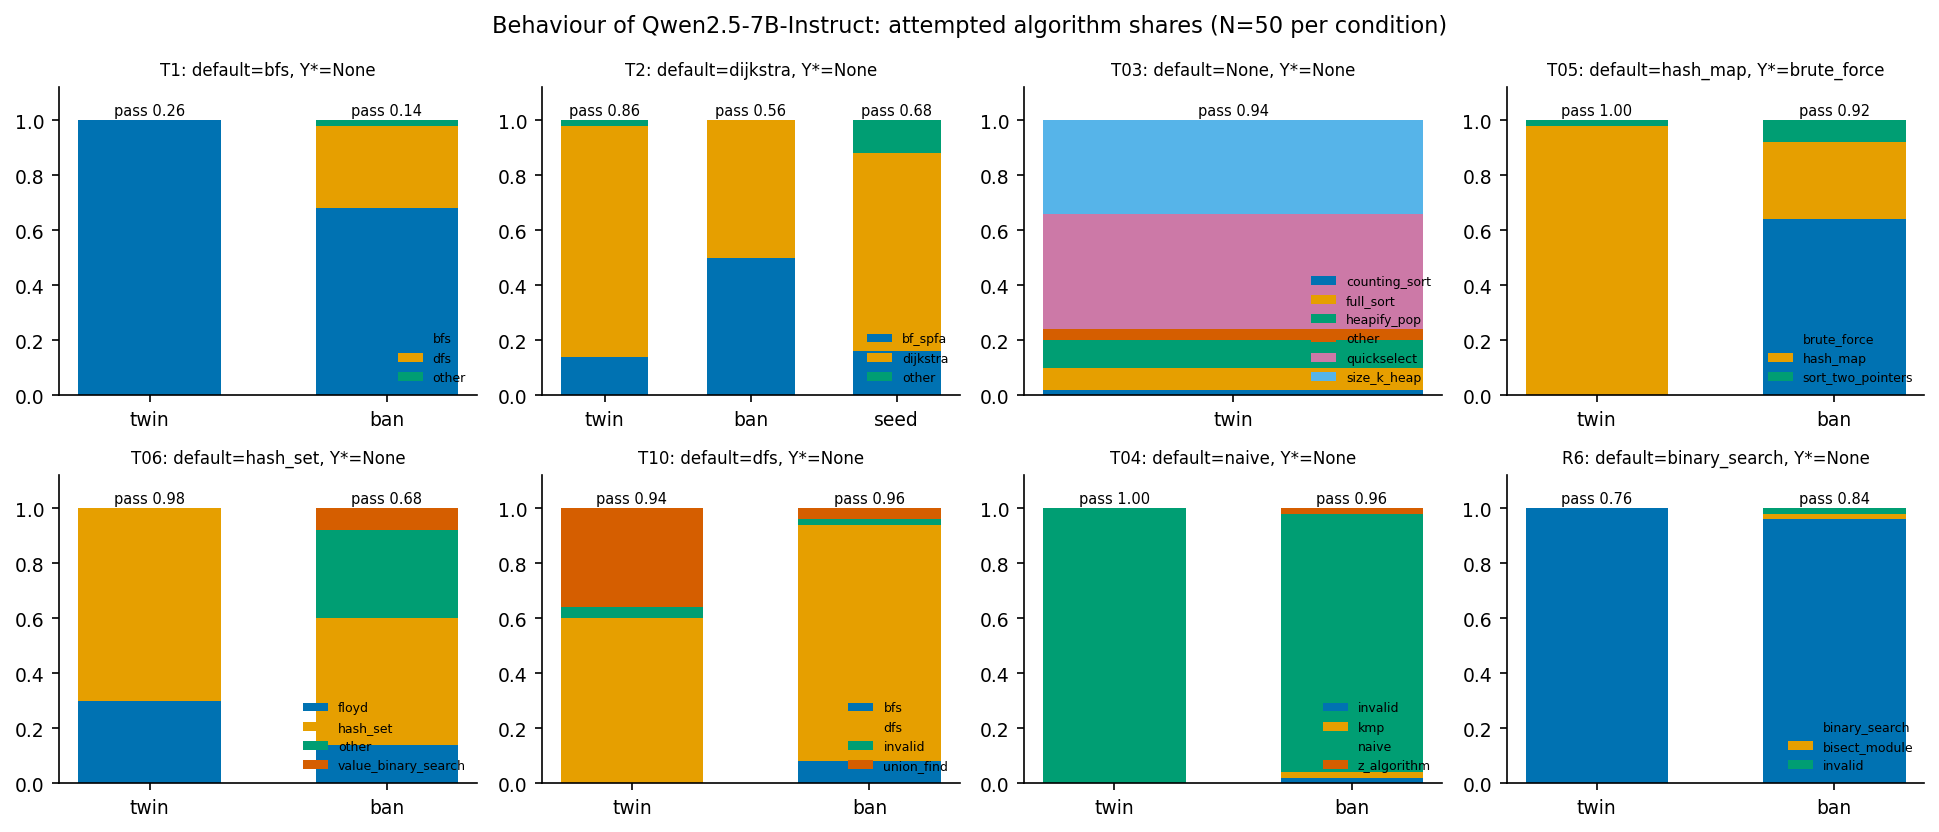

In [11]:
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
                     "ps.fonttype": 42, "figure.dpi": 150})
PAL = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#999999", "#000000"]


def save(fig: Any, name: str) -> None:
    # original: fig.tight_layout(); fig.savefig(FIG_DIR / f"{name}.pdf"); fig.savefig(FIG_DIR / f"{name}.png", dpi=170);
    #           plt.close(fig)   -- in the notebook the figure is shown inline instead
    fig.tight_layout()
    plt.show()


def f0_behaviour() -> None:
    b = REP   # original: read_json(RESULTS_DIR / "behaviour.json") -- here the report recomputed above
    fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
    for ax, t in zip(axes.flat, TASKS):
        R = b["tasks"][t]
        conds = [("twin", R["twin"])] + ([("ban", R["ban"])] if R.get("ban") else []) + \
                ([("seed", R["seed"])] if R.get("seed") else [])
        labs = sorted({l for _, c in conds for l in c["attempted"]})
        x = np.arange(len(conds))
        bottom = np.zeros(len(conds))
        for i, l in enumerate(labs):
            vals = np.array([c["attempted"].get(l, 0) / c["n"] for _, c in conds])
            ax.bar(x, vals, bottom=bottom, color=PAL[i % len(PAL)], label=l, width=0.6)
            bottom += vals
        for j, (_, c) in enumerate(conds):
            ax.text(j, 1.02, f"pass {c['pass_rate']:.2f}", ha="center", fontsize=7)
        ax.set_xticks(x, [c for c, _ in conds])
        ax.set_ylim(0, 1.12)
        ax.set_title(f"{t}: default={R['default']}, Y*={R.get('Ystar')}", fontsize=8)
        ax.legend(fontsize=6, frameon=False, loc="lower right")
    fig.suptitle("Behaviour of Qwen2.5-7B-Instruct: attempted algorithm shares (N=50 per condition)")
    save(fig, "F0_behaviour")


f0_behaviour()

**Reading the behaviour.** "Do not use X" mostly fails on this model.
- **T05** is the only task where the ban yields a substitute: the brute-force double loop, in 32 of the 46 correct ban
  programs.
- **T10:** banning DFS *raises* DFS from 29 to 43 correct programs. On paired CRN slots, 15 union-find twins flip to
  DFS under the ban.
- **W4:** the template "X is not allowed here" never works. All 70 W4 programs attempt the banned default.

## Blind judges (`src/judges.py`)

Every text is mapped to a catalogue algorithm by blind LLM judges at temperature 0. A text is either an AV explanation
(**EXPL**), the visible prompt or generated prefix (**NAME**), or the same text with the question "which algorithm will
the assistant implement?" (**PREDICT**). The judges see the task title, the catalogue (ids, display names, aliases and
a one-line mechanism) and the text. They never see the condition, the position or the realised label.
- **J1** is `gemini-2.5-flash-lite` and **J2** is `mistral-small-3.2`. J2 replaced `gpt-4.1-nano`, which scored 0.80 on
  the calibration set (below the 0.9 bar).
- **J3** (`deepseek-chat-v3.1`) answers only when J1 and J2 disagree.
- **Resolution.** If J1 and J2 agree, their answer stands. Otherwise the majority of all answers wins, or the item is
  `unresolved`.

The API calls (`Runner`) are not run here. The cell rebuilds the rubric functions unchanged and checks them against
the two prompt examples frozen in commit #2. It then re-applies the original resolution step to the stored J1/J2/J3
answers of all 8,340 items.

In [12]:
JUDGES = {"J1": "google/gemini-2.5-flash-lite", "J2": "openai/gpt-4.1-nano", "J3": "deepseek/deepseek-chat-v3.1"}
SWAPS = {"J1": ["meta-llama/llama-4-scout"], "J2": ["mistralai/mistral-small-3.2-24b-instruct"],
         "J3": ["qwen/qwen3-235b-a22b-2507"]}
TITLES = {"T1": "find any valid path between two cells of a grid with walls",
          "T2": "length of the shortest path in a directed graph with integer edge weights 0-100",
          "T03": "return the k-th smallest value of a list of integers",
          "T05": "return the two indices whose values add up to a target (two-sum)",
          "T06": "return the repeated value in a list of n+1 integers in 1..n",
          "T10": "count the connected components of an undirected graph",
          "T04": "first index of a substring needle in a string haystack",
          "R6": "first and last index of a target in a sorted list"}
RUBRIC_VERSION = "v2"


def catalogue_block(task: str) -> str:
    lines = []
    for c in CATALOGUE[task]:   # original: import prompts as PR; PR.catalogue(task)
        al = ", ".join(c["aliases"][:6])
        lines.append(f"- {c['mode']}: {c['display_name']} (also called: {al}). Mechanism: {c['mechanism']}")
    return "\n".join(lines)


def prompt_expl(task: str, text: str) -> str:
    return (f"You read a short text and report which algorithm, if any, the text says is being used or will be used "
            f"to solve a programming task.\n\nProgramming task: {TITLES[task]}.\n\nCatalogue of algorithms for this "
            f"task (use these ids):\n{catalogue_block(task)}\n\nDefinitions:\n"
            "- planned: the id of the catalogue algorithm that the text says is being, or will be, used or implemented. "
            "An algorithm that the text names only as forbidden, avoided, banned or not allowed is NOT planned (it goes "
            "to negated). If the text says that a specific method which is NOT in the catalogue is being or will be used "
            "(for example a genetic algorithm, a neural network, random guessing or any other named technique), answer "
            "\"other\" -- never \"none_named\" in that case. Answer \"none_named\" only when the text names no method "
            "at all as being or going to be used.\n"
            "- mentioned: every catalogue id the text names in any way (by name, alias or unmistakable description).\n"
            "- negated: the catalogue ids the text names only as forbidden, avoided or excluded.\n\n"
            f"Text:\n\"\"\"\n{text}\n\"\"\"\n\n"
            "Answer with one JSON object only, no other words: "
            "{\"planned\": \"<id or none_named or other>\", \"mentioned\": [\"<id>\", ...], \"negated\": [\"<id>\", ...]}")


def prompt_predict(task: str, text: str) -> str:
    return (f"An AI assistant received the request below (if a beginning of its answer is shown, the assistant has "
            f"already written that much). Predict which algorithm from the catalogue the assistant's final Python "
            f"solution will implement.\n\nProgramming task: {TITLES[task]}.\n\nCatalogue of algorithms (use these ids):\n"
            f"{catalogue_block(task)}\n\nRequest and answer so far:\n\"\"\"\n{text}\n\"\"\"\n\n"
            "Answer with one JSON object only, no other words: {\"predicted\": \"<id or other>\"}")


def parse_json(s: str, mode: str, ids: set[str]) -> dict[str, Any] | None:
    m = re.search(r"\{.*\}", s or "", re.S)
    if not m:
        return None
    try:
        d = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None
    if mode == "PREDICT":
        p = str(d.get("predicted", "")).strip()
        return {"predicted": p if p in ids | {"other"} else "other"}
    p = str(d.get("planned", "")).strip()
    norm = lambda xs: [x for x in (xs or []) if isinstance(x, str) and x in ids]
    return {"planned": p if p in ids | {"none_named", "other"} else ("none_named" if not p else "other"),
            "mentioned": norm(d.get("mentioned")), "negated": norm(d.get("negated"))}


JUDGES.update(C2["judges"])   # judges.py run: JUDGES.update(cal["final"]) -- the calibration swapped J2
print("judges after calibration:", JUDGES, "| rubric", C2["rubric_version"])
ex_e, ex_p = C2["judge_prompt_expl_example"], C2["judge_prompt_predict_example"]
task_of = next(t for t, s in TITLES.items() if f"Programming task: {s}." in ex_e)
print(f"rubric rebuilt == commit #2 example ({task_of}): EXPL {prompt_expl(task_of, '<TEXT>') == ex_e}, "
      f"PREDICT {prompt_predict(task_of, '<TEXT>') == ex_p}")
print("parse_json on a raw answer:", parse_json('Sure: {"planned": "brute_force", "mentioned": ["brute_force", "hash_map", '
                                                '"magic"], "negated": ["hash_map"]}', "EXPL",
                                                {c["mode"] for c in CATALOGUE["T05"]}))

# --- the resolution step of judges._run(), unchanged, applied to the stored J1 / J2 / J3 answers ---
items = JUD
res = {it["item_id"]: {j: it[j] for j in ("J1", "J2", "J3")} for it in items}
rows = []
for it in items:
    d = res.get(it["item_id"], {})
    k = "predicted" if it["mode"] == "PREDICT" else "planned"
    vals = [d[j][k] for j in ("J1", "J2", "J3") if d.get(j)]
    a = d.get("J1", {}) or {}
    b = d.get("J2", {}) or {}
    if a and b and a.get(k) == b.get(k):
        resolved = a[k]
    elif vals:
        top, c = Counter(vals).most_common(1)[0]
        resolved = top if c >= 2 else "unresolved"
    else:
        resolved = None
    mentioned = sorted(set((a.get("mentioned") or [])) | set((b.get("mentioned") or []))) if it["mode"] != "PREDICT" else None
    rows.append({"item_id": it["item_id"], "mode": it["mode"], "resolved": resolved, "mentioned_any": mentioned,
                 "disagree": bool(not (a and b and a.get(k) == b.get(k)))})
# ---
N_RESOLVED_MATCH = sum(r["resolved"] == it["resolved"] and r["mentioned_any"] == it["mentioned_any"] for r, it in zip(rows, items))
print(f"\nresolved labels re-derived from J1/J2/J3: {N_RESOLVED_MATCH}/{len(items)} identical to data/judgements.jsonl")
for mode in ("EXPL", "NAME", "PREDICT"):
    rr = [r for r in rows if r["mode"] == mode]
    print(f"  {mode:<8} n={len(rr):5d}  J1/J2 disagreements {sum(r['disagree'] for r in rr):4d}  "
          f"unresolved {sum(r['resolved'] == 'unresolved' for r in rr) / len(rr):.3f}  "
          f"'none_named' {sum(r['resolved'] == 'none_named' for r in rr) / len(rr):.2f}")

judges after calibration: {'J1': 'google/gemini-2.5-flash-lite', 'J2': 'mistralai/mistral-small-3.2-24b-instruct', 'J3': 'deepseek/deepseek-chat-v3.1'} | rubric v2
rubric rebuilt == commit #2 example (T2): EXPL True, PREDICT True
parse_json on a raw answer: {'planned': 'brute_force', 'mentioned': ['brute_force', 'hash_map'], 'negated': ['hash_map']}

resolved labels re-derived from J1/J2/J3: 8340/8340 identical to data/judgements.jsonl
  EXPL     n= 5700  J1/J2 disagreements  325  unresolved 0.006  'none_named' 0.83
  NAME     n= 1320  J1/J2 disagreements  437  unresolved 0.016  'none_named' 0.61
  PREDICT  n= 1320  J1/J2 disagreements  302  unresolved 0.039  'none_named' 0.00


## The instrument gate (`src/nla_ar.py`)

How much of a layer-20 state does an explanation carry? The AR turns each explanation back into a vector *p*, and the
gate scores it against the true state *g*:

FVE_ref = 1 − mean‖p̂ − ĝ‖² / mean‖ĝ_ref − μ_ref‖²

Every vector is first normalised to length √d. The denominator is the spread of a broad reference set: Ultra-FineWeb
text, LeetCode chat and general chat. The verdict is **PASS** at ≥ 0.60 and **PARTIAL** at ≥ 0.50; the released
checkpoint scores 0.752 on its own data.

Once both vectors are normalised to √d, the per-vector error is exactly 2(1 − cos(p, g)). So FVE_ref needs only the
shipped AR cosines and the reference denominator. `fve_parts_from_cos` below is that stand-in for the original
`fve_parts(P, G, Gref)`, whose AR vectors are not shipped. The loop over position classes is unchanged. The layer
convention (`hs21` with FVE 0.695 against `hs20` with 0.580) is reported, because it needs the reference-set vectors.

In [13]:
def verdict(f: float) -> str:
    return "PASS" if f >= FVE_PASS else ("PARTIAL" if f >= FVE_PARTIAL else "FAIL")


def fve_parts_from_cos(c: Sequence[float], den_ref: float) -> dict[str, float]:
    # demo stand-in for nla_ar.fve_parts(P, G, Gref): with p and g normalised to sqrt(d), the per-vector MSE_nrm is
    # exactly 2 (1 - cos(p, g)), so FVE_ref only needs the AR cosines and the reference-set denominator
    c = np.asarray(c, dtype=np.float64)
    mse = 2 * (1 - c)
    return {"n": int(len(c)), "mse_nrm": float(mse.mean()), "fve_ref": float(1 - mse.mean() / den_ref),
            "fve_train_denom": float(1 - mse.mean() / FVE_TRAIN_DENOM), "denominator_ref": den_ref,
            "cos_mean": float(c.mean()), "cos_median": float(np.median(c))}


den_ref = META["gate_reference"]["denominator_ref"]   # mean ||g_ref,n - mu_ref||^2 over the reference set (hs21)
# --- nla_ar.stage_production(), readout gate block (P, G -> cosines) ---
ro = [e for e in EXPL if e["kind"] in ("PREFILL", "GEN") and e["idx"] <= 3]
GATE: dict[str, Any] = {"convention": LAYER_CONVENTION["chosen"], "classes": {}}
for cls in ("ALL", "READ", "SPEC", "g1", "g2", "g4", "g8", "g16"):
    es = ro if cls == "ALL" else [e for e in ro if e["pos_class"] == cls]
    if not es:
        continue
    f = fve_parts_from_cos([COS[e["expl_id"]] for e in es], den_ref)
    GATE["classes"][cls] = f | {"verdict": verdict(f["fve_ref"])}
GATE["per_task"] = {}
for t in TASKS:
    es = [e for e in ro if e["task"] == t]
    if es:
        GATE["per_task"][t] = fve_parts_from_cos([COS[e["expl_id"]] for e in es], den_ref)
GATE["verdict"] = GATE["classes"]["ALL"]["verdict"]
# ---
rg = REPORTED["gate"]
pd.DataFrame([{"class": c, "n": v["n"], "FVE_ref (recomputed)": round(v["fve_ref"], 4),
               "FVE_ref (reported)": round(rg["classes"][c]["fve_ref"], 4), "mean cos": round(v["cos_mean"], 3),
               "verdict": v["verdict"]} for c, v in GATE["classes"].items()]).set_index("class")

,n,FVE_ref (recomputed),FVE_ref (reported),mean cos,verdict
class,,,,,
ALL,5490,0.5118,0.5118,0.826,PARTIAL
READ,510,0.6464,0.6464,0.874,PASS
SPEC,1530,0.5032,0.5032,0.823,PARTIAL
g1,690,0.4825,0.4825,0.816,FAIL
g2,690,0.2791,0.2791,0.743,FAIL
g4,690,0.6384,0.6384,0.871,PASS
g8,690,0.5721,0.5721,0.848,PARTIAL
g16,690,0.5066,0.5066,0.824,PARTIAL


### F1 — the gate beside the reference set (`src/figures.py`)

This is the artifact's `f1_gate`. The task bars (orange) use the gate recomputed above; the reference bars (blue)
and the layer convention come from the reported `results/layer_convention.json`.

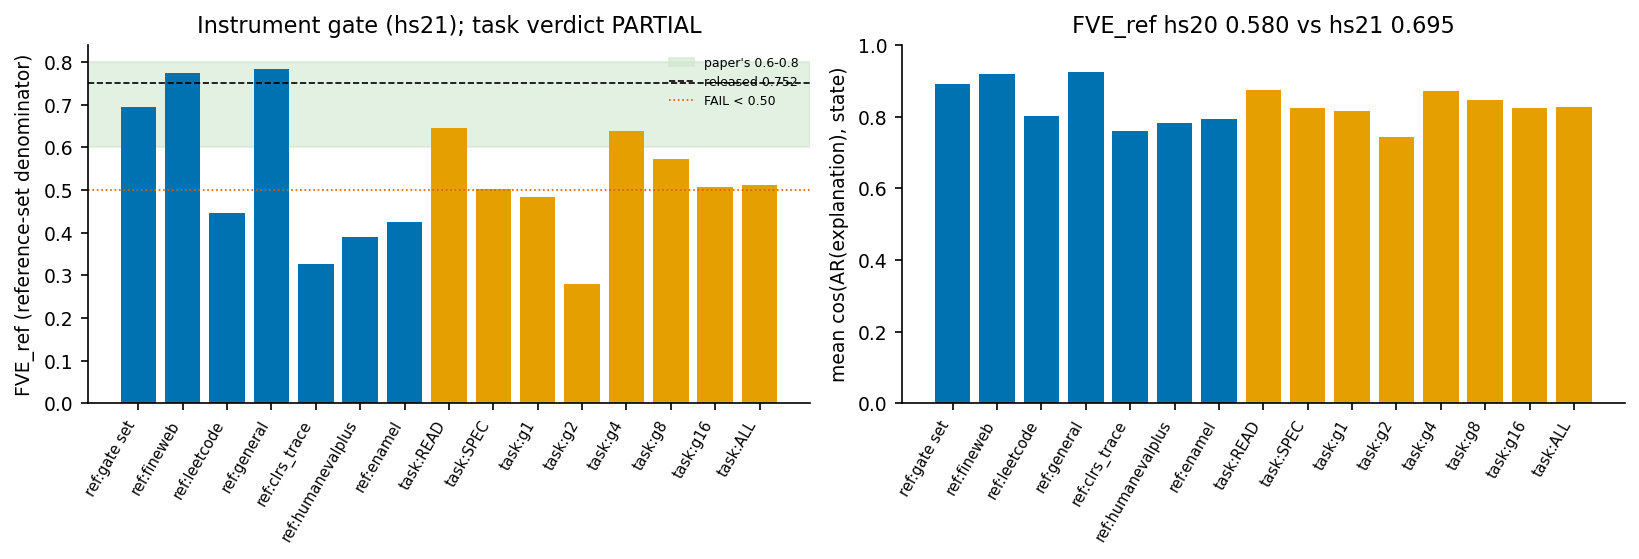

In [14]:
def f1_gate() -> None:
    g = GATE                  # original: read_json(RESULTS_DIR / "gate.json") -- here the gate recomputed above
    lc = LAYER_CONVENTION     # results/layer_convention.json (reported: needs the reference-set vectors)
    cls = [c for c in ("READ", "SPEC", "g1", "g2", "g4", "g8", "g16", "ALL") if c in g["classes"]]
    conv = lc["chosen"]
    refc = lc["conventions"][conv]
    names = ["ref:gate set"] + [f"ref:{k}" for k in ("fineweb", "leetcode", "general", "clrs_trace", "humanevalplus", "enamel")
                                if k in refc] + [f"task:{c}" for c in cls]
    fve = [refc["gate_set"]["fve_ref"]] + [refc[k]["fve_ref"] for k in ("fineweb", "leetcode", "general", "clrs_trace",
                                                                       "humanevalplus", "enamel") if k in refc] + \
          [g["classes"][c]["fve_ref"] for c in cls]
    cos = [refc["gate_set"]["cos_mean"]] + [refc[k]["cos_mean"] for k in ("fineweb", "leetcode", "general", "clrs_trace",
                                                                         "humanevalplus", "enamel") if k in refc] + \
          [g["classes"][c]["cos_mean"] for c in cls]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    x = np.arange(len(names))
    ax[0].axhspan(0.6, 0.8, color="#cfe8cf", alpha=0.6, label="paper's 0.6-0.8")
    ax[0].axhline(0.752, color="k", ls="--", lw=0.8, label="released 0.752")
    ax[0].axhline(0.5, color="#D55E00", ls=":", lw=0.8, label="FAIL < 0.50")
    ax[0].bar(x, fve, color=[PAL[0]] * (len(names) - len(cls)) + [PAL[1]] * len(cls))
    ax[0].set_xticks(x, names, rotation=60, ha="right", fontsize=7)
    ax[0].set_ylabel("FVE_ref (reference-set denominator)")
    ax[0].set_title(f"Instrument gate ({conv}); task verdict {g['verdict']}")
    ax[0].legend(fontsize=6, frameon=False)
    ax[1].bar(x, cos, color=[PAL[0]] * (len(names) - len(cls)) + [PAL[1]] * len(cls))
    ax[1].set_xticks(x, names, rotation=60, ha="right", fontsize=7)
    ax[1].set_ylabel("mean cos(AR(explanation), state)")
    ax[1].set_ylim(0, 1)
    ax[1].set_title(f"FVE_ref hs20 {lc['fve_ref_hs20']:.3f} vs hs21 {lc['fve_ref_hs21']:.3f}")
    save(fig, "F1_gate")


f1_gate()

The blue reference bars show the pipeline reproducing the checkpoint on its own kind of text: FineWeb and chat reach
0.78–0.79. Code text is out of distribution for this NLA (LeetCode 0.45, HumanEval+ 0.39). On the task states the gate
is **PARTIAL** (0.512). READ and g4 pass, while g2 fails badly.

## Readout statistics (`analysis/stats.py`)

These are the shared statistics, unchanged. The code was hashed into commit #2 before any explanation existed. The only
edit: `cluster_bootstrap` draws `N_BOOT` resamples by default (originally 2,000).
- **`mcnemar_exact`:** paired binary outcomes x (the NLA) and y (the comparator). It counts b = x only and c = y only,
  and gives a two-sided exact binomial p of b in b + c.
- **`wilson` / `rate`:** Wilson 95% interval of a rate.
- **`holm`:** Holm correction.
- **`cluster_bootstrap`:** resamples whole tasks, giving a CI that respects task clustering.
- **`spearman`, `kappa`:** rank correlation and Cohen's κ.

In [15]:
def mcnemar_exact(x: Sequence[int], y: Sequence[int]) -> dict[str, Any]:
    """Paired binary outcomes. b = x=1,y=0; c = x=0,y=1; two-sided exact binomial p on b of b+c (p = 1 if b+c = 0)."""
    x = np.asarray(x, dtype=int)
    y = np.asarray(y, dtype=int)
    b = int(((x == 1) & (y == 0)).sum())
    c = int(((x == 0) & (y == 1)).sum())
    p = float(ss.binomtest(b, b + c, 0.5).pvalue) if b + c > 0 else 1.0
    return {"n": int(len(x)), "b": b, "c": c, "p": p, "mean_x": float(x.mean()) if len(x) else None,
            "mean_y": float(y.mean()) if len(y) else None, "effect": float(x.mean() - y.mean()) if len(x) else None}


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float | None, float | None]:
    if n == 0:
        return (None, None)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def rate(xs: Sequence[int]) -> dict[str, Any]:
    k, n = int(sum(xs)), len(xs)
    lo, hi = wilson(k, n)
    return {"k": k, "n": n, "rate": (k / n) if n else None, "wilson95": [lo, hi]}


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        adj = min(1.0, (m - i) * p)
        run = max(run, adj)
        out[k] = run
    return out


def cluster_bootstrap(units: list[dict[str, Any]], stat: Callable[[list[dict[str, Any]]], float | None],
                      cluster_key: str = "task", n_boot: int = N_BOOT, seed: int = 20261022) -> dict[str, Any]:
    # original default: n_boot=2000
    clusters: dict[Any, list[dict[str, Any]]] = {}
    for u in units:
        clusters.setdefault(u[cluster_key], []).append(u)
    keys = sorted(clusters)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(len(keys), size=len(keys), replace=True)
        sample = [u for i in pick for u in clusters[keys[i]]]
        v = stat(sample)
        if v is not None:
            vals.append(v)
    if not vals:
        return {"ci95": [None, None], "n_clusters": len(keys)}
    return {"ci95": [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))], "n_clusters": len(keys),
            "n_boot": len(vals)}


def spearman(a: Sequence[float], b: Sequence[float]) -> dict[str, Any]:
    if len(a) < 3:
        return {"rho": None, "p": None, "n": len(a)}
    r = ss.spearmanr(a, b)
    rho = float(r.statistic) if np.isfinite(r.statistic) else None
    return {"rho": rho, "p": float(r.pvalue) if np.isfinite(r.pvalue) else None, "n": len(a)}


def kappa(a: Sequence[str], b: Sequence[str]) -> float | None:
    if not a:
        return None
    labs = sorted(set(a) | set(b))
    n = len(a)
    po = sum(x == y for x, y in zip(a, b)) / n
    pe = sum((sum(x == l for x in a) / n) * (sum(y == l for y in b) / n) for l in labs)
    return float((po - pe) / (1 - pe)) if pe < 1 else 1.0

## Readout analysis (`analysis/readout.py`)

This file was frozen in commit #2, before any AV call on a task state. Its building blocks are unchanged, and the
`Data` class now takes the rebuilt tables instead of reading files:
- **`d.x(state, target)`:** the NLA vote. It is 1 if at least two of explanations #1–#3 are judged to *plan* the
  target.
- **`d.name(text_id, target, mode)`:** the text-only reader. It is 1 if the judges, reading only the visible prompt or
  generated prefix, call the target planned (`NAME`) or predicted (`PREDICT`).
- **`test_block`:** pairs x with y on the same unit and runs `mcnemar_exact`, the task-cluster bootstrap and the
  pre-registered pass rule. The rule is effect ≥ 0.30 and p < 0.05.

The original `main()` is one long function. Its body is split over the next cells, one per test, and runs at the top
level (`d`, `out` and the helpers become notebook globals). The final `readout.json` write is replaced by keeping
`READOUT = out` in memory.

In [16]:
NAMED_EXCL = {"none_named", "other", "unresolved", None}
POS4 = ("SPEC-3", "SPEC-2", "SPEC-1", "READ")
PRIMARY_W = ("W1", "W2", "W3", "W5")


class Data:
    def __init__(self) -> None:   # original: (self, root: Path = ROOT), reading the files named below
        self.c1 = C1                                          # predictions/commit1_defaults.json
        self.c2 = C2                                          # predictions/commit2_readout.json
        self.idx = {r["state_id"]: r for r in IDX}            # cache/states_index.jsonl
        self.jud = JUD                                        # data/judgements.jsonl
        self.labels = {r["sample_id"]: r for r in LABELS}     # data/labels.jsonl
        self.expl: dict[str, list[dict[str, Any]]] = defaultdict(list)
        self.text: dict[str, dict[str, Any]] = {}
        for r in self.jud:
            if r["mode"] == "EXPL":
                self.expl[r["state_id"]].append(r)
            else:
                self.text[f"{r['mode']}|{r['text_id']}"] = r
        for v in self.expl.values():
            v.sort(key=lambda r: int(r["expl_id"].split("#")[-1]))
        self.tasks = self.c2["tasks"]

    def votes(self, sid: str, target: str, field: str = "planned", max_idx: int = 3,
              drop_unresolved: bool = False) -> tuple[int, int]:
        rs = [r for r in self.expl.get(sid, []) if int(r["expl_id"].split("#")[-1]) <= max_idx]
        if drop_unresolved:
            rs = [r for r in rs if r["resolved"] not in ("unresolved", None)]
        if field == "mentioned":
            hits = sum(target in (r.get("mentioned_any") or []) for r in rs)
        else:
            hits = sum(r["resolved"] == target for r in rs)
        return hits, len(rs)

    def x(self, sid: str, target: str, field: str = "planned", drop_unresolved: bool = False) -> int | None:
        h, n = self.votes(sid, target, field, drop_unresolved=drop_unresolved)
        if n == 0:
            return None
        return int(h >= 2) if n >= 2 else int(h >= 1)

    def planned_majority(self, sid: str) -> str | None:
        rs = [r["resolved"] for r in self.expl.get(sid, []) if int(r["expl_id"].split("#")[-1]) <= 3]
        if not rs:
            return None
        top, c = Counter(rs).most_common(1)[0]
        return top if c >= 2 else "no_majority"

    def name(self, text_id: str, target: str, mode: str = "NAME") -> int | None:
        r = self.text.get(f"{mode}|{text_id}")
        if r is None or r["resolved"] is None:
            return None
        return int(r["resolved"] == target)

    def name_label(self, text_id: str, mode: str = "NAME") -> str | None:
        r = self.text.get(f"{mode}|{text_id}")
        return None if r is None else r["resolved"]


def paired(units: list[dict[str, Any]]) -> list[dict[str, Any]]:
    return [u for u in units if u["x"] is not None and u["y"] is not None]


def test_block(units: list[dict[str, Any]], thr: float | None = 0.30) -> dict[str, Any]:
    u = paired(units)
    m = mcnemar_exact([v["x"] for v in u], [v["y"] for v in u])
    stat = lambda s: (float(np.mean([v["x"] for v in s]) - np.mean([v["y"] for v in s]))) if s else None
    m["cluster_bootstrap"] = cluster_bootstrap(u, stat) if u else None
    m["x_rate"] = rate([v["x"] for v in u])
    m["y_rate"] = rate([v["y"] for v in u])
    if thr is not None:
        m["pass"] = bool(m["effect"] is not None and m["effect"] >= thr and m["p"] < 0.05)
    return m


def by(units: list[dict[str, Any]], key: str) -> dict[str, Any]:
    g: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for u in paired(units):
        g[u[key]].append(u)
    return {k: {"n": len(v), "x": float(np.mean([a["x"] for a in v])), "y": float(np.mean([a["y"] for a in v]))}
            for k, v in sorted(g.items())}


d = Data()
out: dict[str, Any] = {"eligible": [t for t, v in d.tasks.items() if v.get("eligible")]}
print("committed task table (commit #2):")
pd.DataFrame({t: {k: v.get(k) for k in ("default", "Ystar", "eligible", "regate_pass", "ban_failure", "twin_mixed",
                                         "ban_mixed", "forced_readout_modes")} for t, v in d.tasks.items()}).T

committed task table (commit #2):


,default,Ystar,eligible,regate_pass,ban_failure,twin_mixed,ban_mixed,forced_readout_modes
T1,bfs,None,False,True,True,False,True,"[bfs, dfs]"
T2,dijkstra,None,False,True,True,False,True,"[dijkstra, bf_spfa]"
T03,None,None,False,False,False,True,None,"[quickselect, size_k_heap, counting_sort]"
T05,hash_map,brute_force,True,True,False,False,True,"[hash_map, brute_force, sort_two_pointers]"
T06,hash_set,None,False,True,True,True,True,"[hash_set, floyd]"
T10,dfs,None,False,True,True,True,False,"[dfs, union_find]"
T04,naive,None,False,True,True,False,False,"[naive, kmp]"
R6,binary_search,None,False,True,True,False,False,"[binary_search, bisect_module]"


### N1 — the primary test: does a ban state name the substitute?

On a task with a substitute Y\*, the NLA should say that Y\* is planned once the default is banned. The **units** are
the ban states of the eligible tasks, at the four end-of-prompt positions, under templates W1/W2/W3/W5. W4 is reported
apart, because W4 bans never work. For each unit, **x** is whether the NLA names Y\* as planned, and **y** is whether
the text-only NAME reader does.

Only T05 has a substitute. Fallback F4 is therefore active: N1 has just 16 units and is under-powered. The cell also
runs the sensitivity variants: W4 alone, "mentioned" instead of "planned", unresolved items dropped, and single
explanations as units.

In [17]:
# ---------------------------------------------------------------- N1 primary
def n1_units(templates=PRIMARY_W, field="planned", drop=False, y_mode="NAME"):
    us = []
    for t in out["eligible"]:
        D, Y = d.tasks[t]["default"], d.tasks[t]["Ystar"]
        for w in templates:
            for p in POS4:
                sid = f"{t}|ban|{D}|{w}|{p}"
                us.append({"task": t, "template": w, "position": p, "sid": sid,
                           "x": d.x(sid, Y, field, drop), "y": d.name(f"{t}|ban|{D}|{w}|PREFILL", Y, y_mode)})
    return us
u1 = n1_units()
N1 = test_block(u1)
N1["per_task"] = by(u1, "task")
N1["per_position"] = by(u1, "position")
N1["W4"] = test_block(n1_units(("W4",)), None)
N1["sens_mentioned"] = test_block(n1_units(field="mentioned"))
N1["sens_drop_unresolved"] = test_block(n1_units(drop=True))
per_expl = []
for u in u1:
    t = u["task"]
    Y = d.tasks[t]["Ystar"]
    for r in d.expl.get(u["sid"], [])[:3]:
        per_expl.append({"task": t, "x": int(r["resolved"] == Y), "y": u["y"]})
N1["sens_per_explanation"] = test_block(per_expl) if per_expl else None
out["N1"] = N1
print("eligible:", out["eligible"], "| N1:", {k: N1[k] for k in ("n", "b", "c", "p", "effect", "pass")})
print("  per position:", N1["per_position"])
print("  W4:", {k: N1["W4"][k] for k in ("n", "b", "c")}, "| mentioned:", N1["sens_mentioned"]["x_rate"]["rate"],
      "| per explanation:", {k: N1["sens_per_explanation"][k] for k in ("n", "b", "c")})

eligible: ['T05'] | N1: {'n': 16, 'b': 0, 'c': 0, 'p': 1.0, 'effect': 0.0, 'pass': False}
  per position: {'READ': {'n': 4, 'x': 0.0, 'y': 0.0}, 'SPEC-1': {'n': 4, 'x': 0.0, 'y': 0.0}, 'SPEC-2': {'n': 4, 'x': 0.0, 'y': 0.0}, 'SPEC-3': {'n': 4, 'x': 0.0, 'y': 0.0}}
  W4: {'n': 4, 'b': 0, 'c': 0} | mentioned: 0.0 | per explanation: {'n': 48, 'b': 0, 'c': 0}


### N1-swap, N1-rand, N1-predict — the controls of N1

- **N1-swap.** The ban state's vote is compared with the *twin* state's vote for Y\* at the same template and
  position. This tests whether the ban moves the NLA at all. It adds a sign-flip permutation null with `N_PERM_SWAP`
  permutations; the original used 10,000.
- **N1-rand.** The comparator is a *twin + ε* state: the twin state plus a random vector whose norm matches the ban
  displacement.
- **N1-predict.** The comparator is the outside reader (PREDICT) instead of NAME.

In [18]:
# ---------------------------------------------------------------- N1-swap / rand / predict
sw = []
for u in u1:
    t, w, p = u["task"], u["template"], u["position"]
    Y = d.tasks[t]["Ystar"]
    sw.append({"task": t, "template": w, "position": p, "x": u["x"], "y": d.x(f"{t}|twin|-|{w}|{p}", Y)})
S = test_block(sw, None)
pr = paired(sw)
rng = np.random.default_rng(7)
obs = np.mean([v["x"] - v["y"] for v in pr]) if pr else 0.0
diffs = np.array([v["x"] - v["y"] for v in pr], dtype=float)
perm = [np.mean(diffs * rng.choice([-1, 1], size=len(diffs))) for _ in range(N_PERM_SWAP)] if len(diffs) else [0.0]  # original: range(10000)
S["permutation_p"] = float((np.sum(np.abs(perm) >= abs(obs) - 1e-12) + 1) / (len(perm) + 1))
out["N1_swap"] = S
rd = []
for u in u1:
    if u["position"] not in ("READ", "SPEC-1"):
        continue
    t, w, p = u["task"], u["template"], u["position"]
    rd.append({"task": t, "x": u["x"], "y": d.x(f"{t}|rand|-|{w}|{p}", d.tasks[t]["Ystar"])})
out["N1_rand"] = test_block(rd, None)
out["N1_predict"] = test_block(n1_units(y_mode="PREDICT"), None)
for k in ("N1_swap", "N1_rand", "N1_predict"):
    print(f"{k:<11}", {kk: out[k][kk] for kk in ("n", "b", "c", "p")}, "| comparator rate", out[k]["y_rate"]["rate"])

N1_swap     {'n': 16, 'b': 0, 'c': 0, 'p': 1.0} | comparator rate 0.0
N1_rand     {'n': 8, 'b': 0, 'c': 0, 'p': 1.0} | comparator rate 0.0
N1_predict  {'n': 16, 'b': 0, 'c': 0, 'p': 1.0} | comparator rate 0.0


### N2 — does a twin state name the model's own default?

The twin prompt is neutral, and the model then writes its default: BFS, Dijkstra 0.88, hash map 0.98 and so on. If the
plan sits in the residual stream in a form the NLA can verbalise, the twin states should name the default. The units are
7 defaulted tasks × 4 templates × 4 positions = 112.

In [19]:
# ---------------------------------------------------------------- N2 default (twin)
def n2_units(templates=PRIMARY_W):
    us = []
    for t, v in d.tasks.items():
        D = v.get("default")
        if not D or not v.get("regate_pass", True):
            continue
        for w in templates:
            for p in POS4:
                sid = f"{t}|twin|-|{w}|{p}"
                us.append({"task": t, "template": w, "position": p, "x": d.x(sid, D),
                           "y": d.name(f"{t}|twin|-|{w}|PREFILL", D)})
    return us
u2 = n2_units()
N2 = test_block(u2)
N2["per_task"] = by(u2, "task")
N2["per_position"] = by(u2, "position")
N2["W4"] = test_block(n2_units(("W4",)), None)
out["N2_default"] = N2
print("N2:", {k: N2[k] for k in ("n", "b", "c", "p", "effect", "pass")}, "| NLA", N2["x_rate"]["rate"], "| text NAME",
      N2["y_rate"]["rate"], "| bootstrap CI", N2["cluster_bootstrap"]["ci95"])

N2: {'n': 112, 'b': 0, 'c': 0, 'p': 1.0, 'effect': 0.0, 'pass': False} | NLA 0.0 | text NAME 0.0 | bootstrap CI [0.0, 0.0]


### N3 — the positive control: "Implement Y" states

If the prompt literally says "Implement breadth-first search (BFS)", the states at the end of that prompt should name
BFS. The text-only reader gets 1.00 here. The pre-registered pass bar for the NLA is 0.7 per task.

In [20]:
# ---------------------------------------------------------------- N3 forced positive control
n3: dict[str, Any] = {}
for t, v in d.tasks.items():
    if not v.get("regate_pass", True):
        continue  # a task failing the style re-gate is excluded from every readout test
    rows = []
    for m in v.get("forced_readout_modes", []):
        for w in ("W1", "W2", "W3", "W4", "W5"):
            for p in POS4:
                xx = d.x(f"{t}|forced|{m}|{w}|{p}", m)
                if xx is not None:
                    rows.append({"mode": m, "x": xx, "y": d.name(f"{t}|forced|{m}|{w}|PREFILL", m)})
    if rows:
        n3[t] = {"nla": rate([r["x"] for r in rows]),
                 "text_only": rate([r["y"] for r in rows if r["y"] is not None]),
                 "per_mode": {m: rate([r["x"] for r in rows if r["mode"] == m]) for m in v["forced_readout_modes"]},
                 "pass_0.7": bool(rate([r["x"] for r in rows])["rate"] >= 0.7)}
out["N3_forced"] = {"tasks": n3, "n_tasks_pass": sum(v["pass_0.7"] for v in n3.values())}
pd.DataFrame({t: {"NLA names Y": v["nla"]["rate"], "n": v["nla"]["n"], "text-only names Y": v["text_only"]["rate"],
                  "pass (>= 0.7)": v["pass_0.7"]} for t, v in n3.items()}).T

,NLA names Y,n,text-only names Y,pass (>= 0.7)
T1,0.0,40,1.0,False
T2,0.0,40,1.0,False
T05,0.0,60,1.0,False
T06,0.0,40,1.0,False
T10,0.0,40,1.0,False
T04,0.0,40,1.0,False
R6,0.0,40,1.0,False


### N4 (seed), N5 and N6 — generated tokens

- **N4.** The T2 semantic seed is a story describing Bellman-Ford-like rounds. What does the NLA say at the seed
  states, and what does the model write?
- **N5.** At generated tokens g1–g16, does the NLA name the algorithm the sample really implements, *before the
  visible text identifies it*? A position is *pre-identifying* while the text-only NAME reader cannot yet name any
  algorithm from the prompt plus the generated prefix.
- **N6.** This is the per-sample test in the MIXED conditions, where the realised algorithm is genuinely uncertain. The
  NLA is paired against the outside reader (PREDICT) on the same pre-identifying units.

In [21]:
# ---------------------------------------------------------------- N4 seed
seed_states = [s for s, r in d.idx.items() if r.get("condition") == "seed" and r["kind"] == "PREFILL"]
realised = Counter(r["label"] for r in d.labels.values() if r.get("arm") == "SEED" and r.get("passed"))
out["N4_seed"] = {"nla_planned_majority": dict(Counter(d.planned_majority(s) for s in seed_states)),
                  "text_only_name": dict(Counter(d.name_label(f"T2|seed|-|{w}|PREFILL") for w in ("W1", "W2", "W3", "W4", "W5"))),
                  "text_only_predict": dict(Counter(d.name_label(f"T2|seed|-|{w}|PREFILL", "PREDICT") for w in ("W1", "W2", "W3", "W4", "W5"))),
                  "realised_correct_labels": dict(realised)}
# ---------------------------------------------------------------- N5 / N6 generated tokens
gen_units = []
for sid, r in d.idx.items():
    if r["kind"] != "GEN":
        continue
    lab = d.labels.get(r["sample_id"])
    if lab is None or not d.tasks.get(r["task"], {}).get("regate_pass", True):
        continue
    t = r["task"]
    tid = f"{t}|{r['condition']}|{r.get('mode') or '-'}|{r['template']}|{r['position']}|{r['slot']}"
    gen_units.append({"task": t, "condition": r["condition"], "g": int(r["position"][1:]), "sample_id": r["sample_id"],
                      "realised": lab["label"], "passed": bool(lab.get("passed")), "mixed": bool(r.get("mixed")),
                      "x": d.x(sid, lab["label"]), "y_name": d.name(tid, lab["label"]),
                      "y_pred": d.name(tid, lab["label"], "PREDICT"), "name_label": d.name_label(tid)})
first_id: dict[str, int] = {}
for u in sorted(gen_units, key=lambda u: u["g"]):
    if u["name_label"] not in NAMED_EXCL and u["sample_id"] not in first_id:
        first_id[u["sample_id"]] = u["g"]
for u in gen_units:
    u["pre_identifying"] = u["g"] < first_id.get(u["sample_id"], 10 ** 6)
curves: dict[str, Any] = {}
for cond in sorted({u["condition"] for u in gen_units}):
    curves[cond] = {}
    for g in (1, 2, 4, 8, 16):
        us = [u for u in gen_units if u["condition"] == cond and u["g"] == g and u["pre_identifying"]]
        curves[cond][f"g{g}"] = {"nla": rate([u["x"] for u in us if u["x"] is not None]),
                                 "text_name": rate([u["y_name"] for u in us if u["y_name"] is not None]),
                                 "text_predict": rate([u["y_pred"] for u in us if u["y_pred"] is not None])}
out["N5_gen"] = {"curves_pre_identifying": curves,
                 "share_pre_identifying": float(np.mean([u["pre_identifying"] for u in gen_units])) if gen_units else None}
n6u = [{"task": u["task"], "x": u["x"], "y": u["y_pred"]} for u in gen_units if u["mixed"] and u["pre_identifying"]]
out["N6_per_sample"] = test_block(n6u, None)
out["N6_per_sample"]["n_samples"] = len({u["sample_id"] for u in gen_units if u["mixed"]})
print("N4 seed:", out["N4_seed"])
print("N5 share of pre-identifying (sample, position) units:", round(out["N5_gen"]["share_pre_identifying"], 3))
print("N5 NLA naming rate at pre-identifying positions:",
      {c: {g: v[g]["nla"]["rate"] for g in v} for c, v in curves.items()})
N6 = out["N6_per_sample"]
print(f"N6 (MIXED, pre-identifying): n={N6['n']} units from {N6['n_samples']} samples; NLA {N6['x_rate']['rate']:.3f} vs "
      f"outside reader {N6['y_rate']['rate']:.3f}; McNemar b={N6['b']}, c={N6['c']}, p={N6['p']:.2g}")

N4 seed: {'nla_planned_majority': {'none_named': 20}, 'text_only_name': {'bf_spfa': 5}, 'text_only_predict': {'unresolved': 1, 'bf_spfa': 4}, 'realised_correct_labels': {'dijkstra': 28, 'bf_spfa': 6}}
N5 share of pre-identifying (sample, position) units: 0.524
N5 NLA naming rate at pre-identifying positions: {'ban': {'g1': 0.0, 'g2': 0.0, 'g4': 0.043478260869565216, 'g8': 0.2826086956521739, 'g16': 0.14705882352941177}, 'forced': {'g1': None, 'g2': None, 'g4': None, 'g8': None, 'g16': None}, 'twin': {'g1': 0.0, 'g2': 0.0, 'g4': 0.18181818181818182, 'g8': 0.12727272727272726, 'g16': 0.047619047619047616}}
N6 (MIXED, pre-identifying): n=364 units from 120 samples; NLA 0.066 vs outside reader 0.253; McNemar b=20, c=88, p=2.3e-11


### N7, N8, N8b — templates and ban-failure tasks; Holm over the secondary tests

- **N7.** The Spearman correlation, across templates, between the NLA's Y\* rate and the realised Y\* share. It is
  undefined here because the NLA rate is constantly 0.
- **N8 and N8b.** On the *ban-failure* tasks the model keeps writing the banned default. Does the NLA name that default
  as planned, against the outside reader (N8b, paired)?
- **Holm.** The secondary p-values are Holm-corrected together.

In [22]:
# ---------------------------------------------------------------- N7 template correlation
a, b, rows7 = [], [], []
for t in out["eligible"]:
    D, Y = d.tasks[t]["default"], d.tasks[t]["Ystar"]
    for w in ("W1", "W2", "W3", "W4", "W5"):
        hits = n = 0
        for p in POS4:
            h, k = d.votes(f"{t}|ban|{D}|{w}|{p}", Y)
            hits += h
            n += k
        bl = [r for r in d.labels.values() if r.get("arm") == "BAN" and r["task"] == t and r.get("template") == w]
        if n and bl:
            a.append(hits / n)
            b.append(sum(bool(r.get("passed")) and r["label"] == Y for r in bl) / len(bl))
            rows7.append({"task": t, "template": w, "nla_rate": hits / n, "realised_Ystar_share": b[-1]})
out["N7_template"] = spearman(a, b) | {"rows": rows7}
# ---------------------------------------------------------------- N8 ban-failure tasks
n8 = {}
for t, v in d.tasks.items():
    if v.get("default") and not v.get("Ystar") and v.get("regate_pass", True):
        D = v["default"]
        sub = Counter(d.name_label(f"{t}|ban|{D}|{w}|PREFILL", "PREDICT") for w in ("W1", "W2", "W3", "W4", "W5"))
        subst = next((k for k, _ in sub.most_common() if k not in NAMED_EXCL and k != D), None)
        sts = [f"{t}|ban|{D}|{w}|{p}" for w in ("W1", "W2", "W3", "W4", "W5") for p in POS4]
        maj = Counter(d.planned_majority(s) for s in sts)
        n8[t] = {"nla_majority": dict(maj), "names_default": rate([d.x(s, D) or 0 for s in sts]),
                 "outside_reader_substitute": subst,
                 "names_outside_substitute": rate([d.x(s, subst) or 0 for s in sts]) if subst else None}
out["N8_failure"] = n8
# N8b (paired): on ban-failure tasks the model still implements the forbidden default. Units = ban states
# (W1/W2/W3/W5 x SPEC-3..READ); x = NLA names the default as planned; y = the outside reader (PREDICT on the
# visible ban text) predicts the default; y2 = the text-only NAME reader calls the default planned.
u8, u8n = [], []
for t, v in d.tasks.items():
    if v.get("default") and not v.get("Ystar") and v.get("regate_pass", True):
        D = v["default"]
        for w in PRIMARY_W:
            for p in POS4:
                sid = f"{t}|ban|{D}|{w}|{p}"
                xx = d.x(sid, D)
                u8.append({"task": t, "x": xx, "y": d.name(f"{t}|ban|{D}|{w}|PREFILL", D, "PREDICT")})
                u8n.append({"task": t, "x": xx, "y": d.name(f"{t}|ban|{D}|{w}|PREFILL", D)})
out["N8b_banfail_default_vs_predict"] = test_block(u8)
out["N8b_banfail_default_vs_name"] = test_block(u8n)
out["N8b_per_task"] = by(u8, "task")
# ---------------------------------------------------------------- holm over secondary tests
ps = {"N1_swap": out["N1_swap"]["p"], "N1_rand": out["N1_rand"]["p"], "N1_predict": out["N1_predict"]["p"],
      "N2_default": out["N2_default"]["p"], "N6_per_sample": out["N6_per_sample"]["p"],
      "N8b_vs_predict": out["N8b_banfail_default_vs_predict"]["p"], "N8b_vs_name": out["N8b_banfail_default_vs_name"]["p"]}
out["holm_secondary"] = holm({k: v for k, v in ps.items() if v is not None})
print("N7:", {k: out["N7_template"][k] for k in ("rho", "p", "n")})
print("N8 outside-reader substitutes:", {t: v["outside_reader_substitute"] for t, v in n8.items()})
print("N8b vs PREDICT:", {k: out["N8b_banfail_default_vs_predict"][k] for k in ("n", "b", "c", "p")},
      "| vs NAME:", {k: out["N8b_banfail_default_vs_name"][k] for k in ("n", "b", "c", "p")})
print("Holm (secondary):", {k: f"{v:.3g}" for k, v in out["holm_secondary"].items()})

N7:

 {'rho': None, 'p': None, 'n': 5}
N8 outside-reader substitutes: {'T1': 'dfs', 'T2': 'bf_spfa', 'T06': 'floyd', 'T10': 'bfs', 'T04': 'builtin', 'R6': 'bisect_module'}
N8b vs PREDICT: {'n': 96, 'b': 0, 'c': 0, 'p': 1.0} | vs NAME: {'n': 96, 'b': 0, 'c': 0, 'p': 1.0}
Holm (secondary): {'N6_per_sample': '1.63e-10', 'N1_swap': '1', 'N1_rand': '1', 'N1_predict': '1', 'N2_default': '1', 'N8b_vs_predict': '1', 'N8b_vs_name': '1'}


/tmp/ipykernel_1136/2409485942.py:63: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r = ss.spearmanr(a, b)


### Naming table, judge agreement, and what the NLA says is planned

Three tables close the analysis:
- The **naming table** gives, per condition and position, how often the NLA names its target. The targets are the
  default for twin states, Y\* for ban and random states, and the forced Y for forced states.
- **Judge agreement** is J1 against J2, as raw agreement and Cohen's κ, per mode.
- The **planned distribution** gives the resolved labels per task and condition.

In [23]:
# ---------------------------------------------------------------- naming table (F2) and judge agreement
table = defaultdict(lambda: defaultdict(list))
for sid, r in d.idx.items():
    if r["kind"] not in ("PREFILL", "RAND") or r["task"] not in d.tasks:
        continue
    v = d.tasks[r["task"]]
    tgt = v.get("Ystar") if r["condition"] in ("ban", "rand") else (r.get("mode") if r["condition"] == "forced" else v.get("default"))
    if not tgt:
        continue
    xx = d.x(sid, tgt)
    if xx is not None:
        table[f"{r['condition']}"][r["position"]].append(xx)
out["naming_table"] = {c: {p: rate(v) for p, v in ps_.items()} for c, ps_ in table.items()}
agree = {}
for mode in ("EXPL", "NAME", "PREDICT"):
    k = "predicted" if mode == "PREDICT" else "planned"
    prs = [(r["J1"][k], r["J2"][k]) for r in d.jud if r["mode"] == mode and r.get("J1") and r.get("J2")]
    if prs:
        agree[mode] = {"n": len(prs), "raw_agreement": float(np.mean([a_ == b_ for a_, b_ in prs])),
                       "kappa_J1_J2": kappa([p[0] for p in prs], [p[1] for p in prs]),
                       "n_J3": sum(1 for r in d.jud if r["mode"] == mode and r.get("J3")),
                       "n_unresolved": sum(1 for r in d.jud if r["mode"] == mode and r["resolved"] == "unresolved")}
out["judge_agreement"] = agree
# planned-label distributions per task and condition (F3)
dist = defaultdict(Counter)
for sid, r in d.idx.items():
    if r["kind"] in ("PREFILL", "GEN", "RAND") and sid in d.expl:
        for e in d.expl[sid][:3]:
            dist[f"{r['task']}|{r['condition']}"][e["resolved"]] += 1
out["planned_distribution"] = {k: dict(v) for k, v in dist.items()}
READOUT = out   # original: (ROOT / "results" / "readout.json").write_text(json.dumps(out, indent=1, default=float))
print(json.dumps({k: READOUT[k] for k in ("eligible",)}), "N1", {k: READOUT["N1"][k] for k in ("n", "b", "c", "p", "effect", "pass")})
print("naming rates:", {c: {p: v["rate"] for p, v in t_.items()} for c, t_ in READOUT["naming_table"].items()})
pd.DataFrame(agree).T

{"eligible": ["T05"]} N1 {'n': 16, 'b': 0, 'c': 0, 'p': 1.0, 'effect': 0.0, 'pass': False}
naming rates: {'forced': {'READ': 0.0, 'SPEC-1': 0.0, 'SPEC-2': 0.0, 'SPEC-3': 0.0}, 'twin': {'READ': 0.0, 'SPEC-1': 0.0, 'SPEC-2': 0.0, 'SPEC-3': 0.0}, 'seed': {'READ': 0.0, 'SPEC-1': 0.0, 'SPEC-2': 0.0, 'SPEC-3': 0.0}, 'ban': {'READ': 0.0, 'SPEC-1': 0.0, 'SPEC-2': 0.0, 'SPEC-3': 0.0}, 'rand': {'READ': 0.0, 'SPEC-1': 0.0}}


,n,raw_agreement,kappa_J1_J2,n_J3,n_unresolved
EXPL,5700.0,0.942982,0.820003,325.0,33.0
NAME,1320.0,0.668939,0.557053,437.0,21.0
PREDICT,1320.0,0.771212,0.754283,302.0,52.0


### Readout figures (`src/figures.py`: F2, F3, F4, F7)

These are the artifact's own plotting functions, unchanged except that they read the `READOUT` dict recomputed above
instead of `results/readout.json`:
- **F2.** Naming rates per condition and position, and the N1/N2 blocks with their comparators.
- **F3.** What the NLA says is planned, per task and condition. Nearly everything is `none_named`.
- **F4.** Generated-token curves at pre-identifying positions.
- **F7.** Judge agreement.

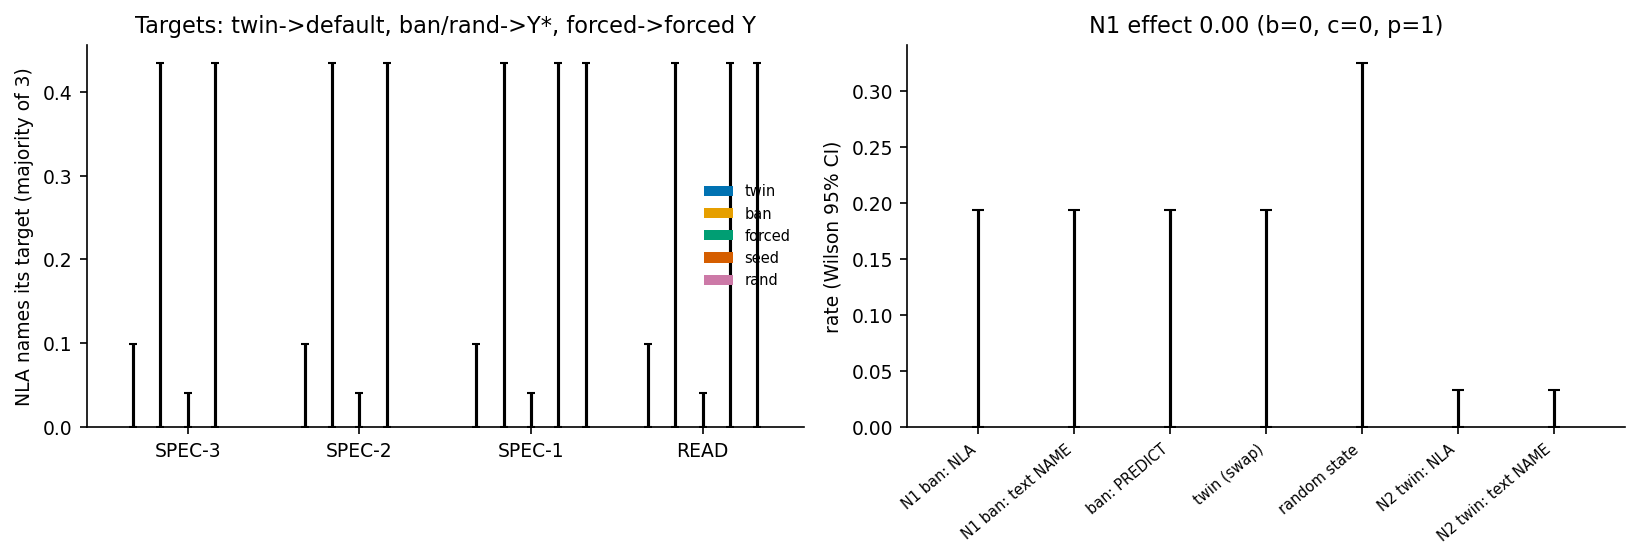

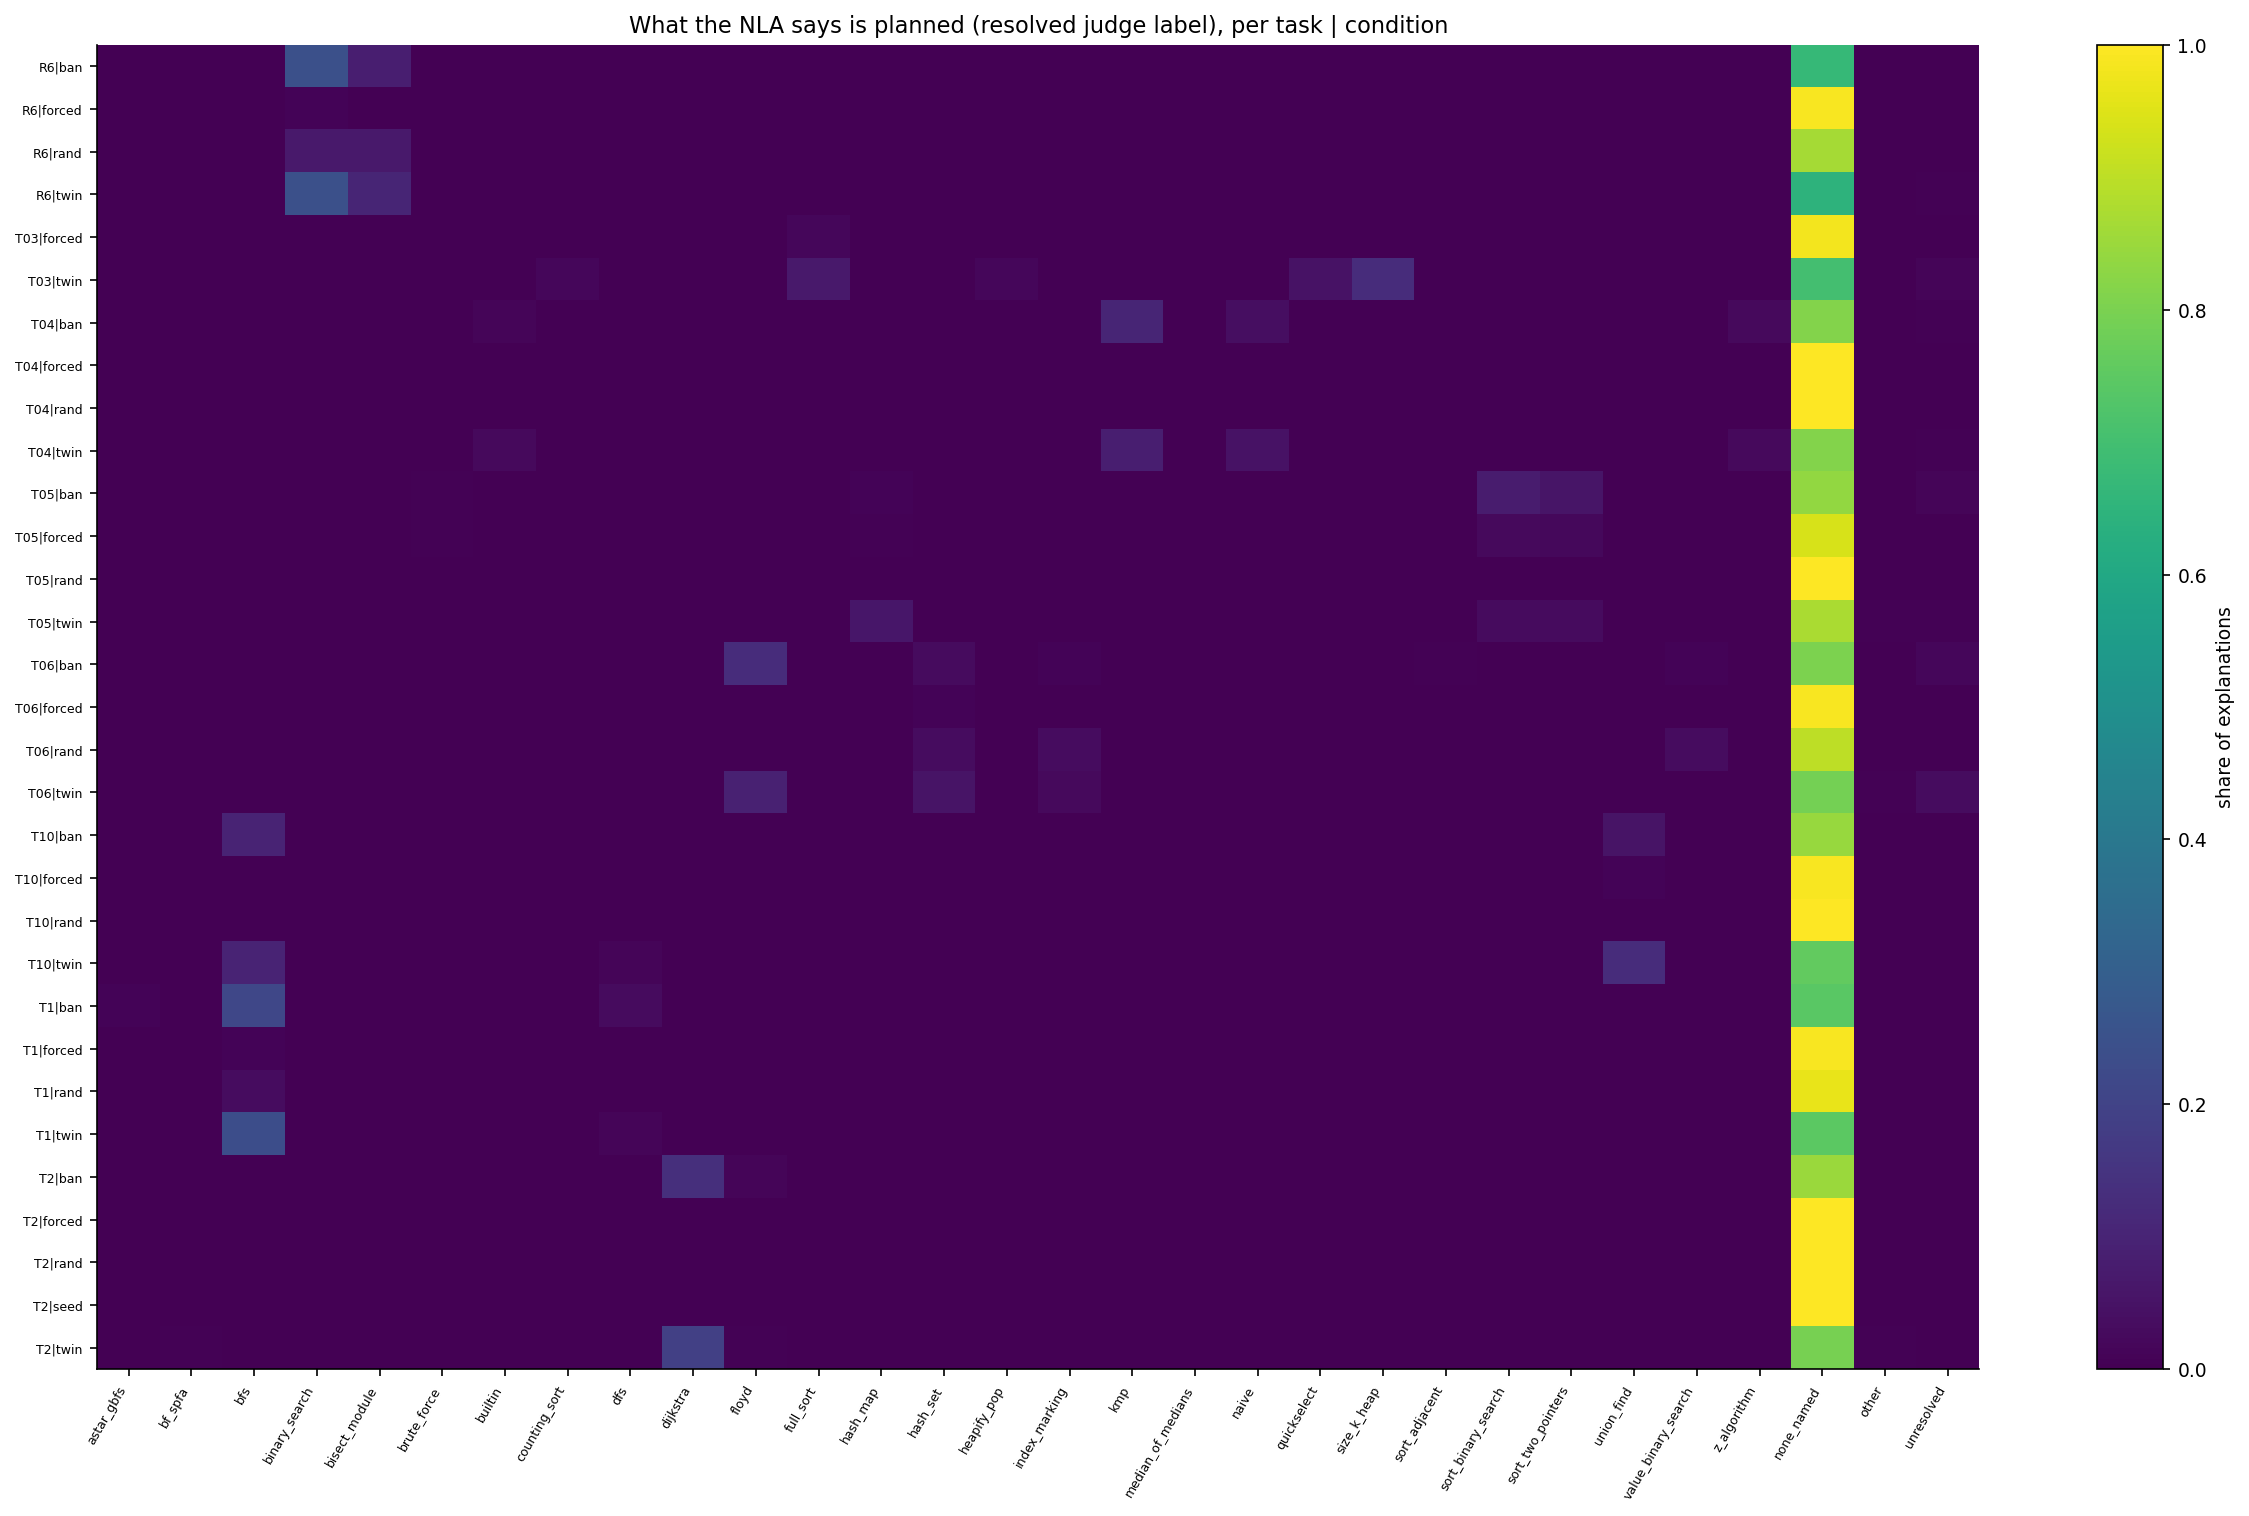

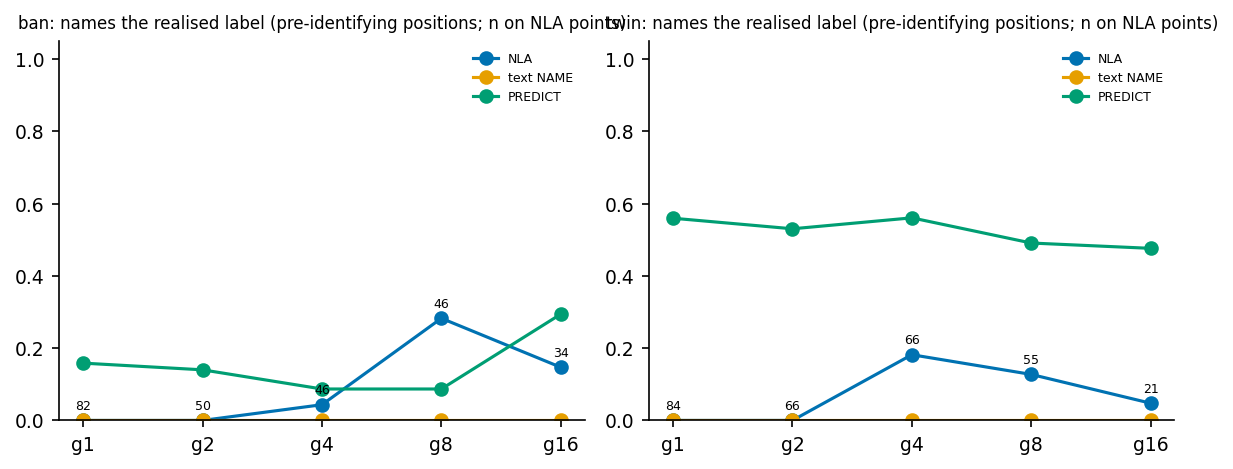

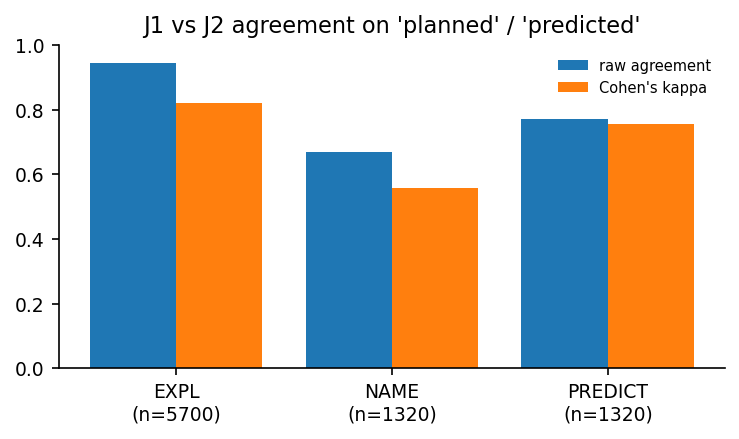

In [24]:
def f2_naming() -> None:
    r = READOUT   # original: read_json(RESULTS_DIR / "readout.json")
    tab = r["naming_table"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    conds = [c for c in ("twin", "ban", "forced", "seed", "rand") if c in tab]
    pos = ["SPEC-3", "SPEC-2", "SPEC-1", "READ"]
    w = 0.8 / max(1, len(conds))
    for i, c in enumerate(conds):
        xs, ys, lo, hi = [], [], [], []
        for j, p in enumerate(pos):
            if p in tab[c] and tab[c][p]["n"]:
                v = tab[c][p]
                xs.append(j + i * w)
                ys.append(v["rate"])
                lo.append(v["rate"] - v["wilson95"][0])
                hi.append(v["wilson95"][1] - v["rate"])
        ax[0].bar(xs, ys, width=w, yerr=[lo, hi], capsize=2, color=PAL[i], label=c)
    ax[0].set_xticks(np.arange(len(pos)) + 0.4 - w / 2, pos)
    ax[0].set_ylabel("NLA names its target (majority of 3)")
    ax[0].set_title("Targets: twin->default, ban/rand->Y*, forced->forced Y")
    ax[0].legend(fontsize=7, frameon=False)
    blocks = [("N1 ban: NLA", r["N1"]["x_rate"]), ("N1 ban: text NAME", r["N1"]["y_rate"]),
              ("ban: PREDICT", r["N1_predict"]["y_rate"]), ("twin (swap)", r["N1_swap"]["y_rate"]),
              ("random state", r["N1_rand"]["y_rate"]), ("N2 twin: NLA", r["N2_default"]["x_rate"]),
              ("N2 twin: text NAME", r["N2_default"]["y_rate"])]
    xs = np.arange(len(blocks))
    ys = [b["rate"] or 0 for _, b in blocks]
    err = [[(b["rate"] or 0) - (b["wilson95"][0] or 0) for _, b in blocks],
           [(b["wilson95"][1] or 0) - (b["rate"] or 0) for _, b in blocks]]
    ax[1].bar(xs, ys, yerr=err, capsize=3, color=[PAL[1], PAL[7], PAL[7], PAL[5], PAL[3], PAL[0], PAL[7]])
    ax[1].set_xticks(xs, [n for n, _ in blocks], rotation=40, ha="right", fontsize=7)
    ax[1].set_ylabel("rate (Wilson 95% CI)")
    ax[1].set_title(f"N1 effect {r['N1']['effect']:.2f} (b={r['N1']['b']}, c={r['N1']['c']}, p={r['N1']['p']:.3g})")
    save(fig, "F2_naming")


def f3_distribution() -> None:
    r = READOUT   # original: read_json(RESULTS_DIR / "readout.json")
    dist = r["planned_distribution"]
    keys = sorted(dist)
    labs = sorted({l for k in keys for l in dist[k]}, key=lambda s: (s in ("none_named", "other", "unresolved"), s))
    M = np.array([[dist[k].get(l, 0) / max(1, sum(dist[k].values())) for l in labs] for k in keys])
    fig, ax = plt.subplots(figsize=(max(6, 0.45 * len(labs) + 3), 0.28 * len(keys) + 1.5))
    im = ax.imshow(M, aspect="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set_yticks(range(len(keys)), keys, fontsize=6)
    ax.set_xticks(range(len(labs)), labs, rotation=60, ha="right", fontsize=6)
    fig.colorbar(im, ax=ax, label="share of explanations")
    ax.set_title("What the NLA says is planned (resolved judge label), per task | condition")
    save(fig, "F3_planned_distribution")


def f4_gen() -> None:
    r = READOUT   # original: read_json(RESULTS_DIR / "readout.json")
    cur = {c: v for c, v in r["N5_gen"]["curves_pre_identifying"].items()
           if any(v[f"g{g}"]["nla"]["n"] for g in (1, 2, 4, 8, 16))}  # forced: no pre-identifying position exists
    fig, axes = plt.subplots(1, max(1, len(cur)), figsize=(4 * max(1, len(cur)), 3.2), squeeze=False)
    for ax, (cond, c) in zip(axes[0], cur.items()):
        gs = [1, 2, 4, 8, 16]
        for i, (k, lab) in enumerate((("nla", "NLA"), ("text_name", "text NAME"), ("text_predict", "PREDICT"))):
            ys = [c[f"g{g}"][k]["rate"] if c[f"g{g}"][k]["n"] else np.nan for g in gs]
            ns = [c[f"g{g}"][k]["n"] for g in gs]
            ax.plot(gs, ys, marker="o", color=PAL[i], label=lab)
            for g, y, n in zip(gs, ys, ns):
                if n and k == "nla":
                    ax.text(g, (y if np.isfinite(y) else 0) + 0.03, str(n), fontsize=6, ha="center")
        ax.set_xscale("log", base=2)
        ax.set_xticks(gs, [f"g{g}" for g in gs])
        ax.set_ylim(0, 1.05)
        ax.set_title(f"{cond}: names the realised label (pre-identifying positions; n on NLA points)", fontsize=8)
        ax.legend(fontsize=6, frameon=False)
    save(fig, "F4_generated_curves")


def f7_judges() -> None:
    r = READOUT   # original: read_json(RESULTS_DIR / "readout.json")
    ag = r.get("judge_agreement", {})
    if not ag:
        return
    fig, ax = plt.subplots(figsize=(5, 3))
    modes = list(ag)
    ax.bar(np.arange(len(modes)) - 0.2, [ag[m]["raw_agreement"] for m in modes], width=0.4, label="raw agreement")
    ax.bar(np.arange(len(modes)) + 0.2, [ag[m]["kappa_J1_J2"] or 0 for m in modes], width=0.4, label="Cohen's kappa")
    ax.set_xticks(range(len(modes)), [f"{m}\n(n={ag[m]['n']})" for m in modes])
    ax.set_ylim(0, 1)
    ax.legend(fontsize=7, frameon=False)
    ax.set_title("J1 vs J2 agreement on 'planned' / 'predicted'")
    save(fig, "F7_judges")


f2_naming()
f3_distribution()
f4_gen()
f7_judges()

## Activation geometry in real layer-20 coordinates (`analysis/geometry.py`)

This step is exploratory: it was not pre-registered. It works in the actual 3,584-dimensional `hidden_states[21]`
space at READ, with no learned projection, and builds three objects per task:
- **Forced centroids.** For each catalogue algorithm *m*, the mean of the five "Implement *m*" paraphrase states.
- **Twin and ban centroids.** The means of the twin and ban states.
- **Ban displacement.** For each template, h_ban − h_twin. It is compared with each algorithm direction c_m − c_twin
  (cosine and projection). It is also compared with the *mode-specific contrast* c_m − mean_m c_m, which removes what
  all forced prompts share. This asks whether the ban pushes the state toward the banned algorithm's own region, or
  toward an alternative.

Classical MDS on the centroid distances gives the 2-D maps of F8. `analysis/geometry.py`'s `cmds` and `main` are
unchanged, except that `main` is renamed to `geometry_main` (so it does not shadow `method.py`'s `main`). The states and
labels come from the rebuilt tables, and the positions come from `GEOMETRY_POSITIONS`.

In [25]:
TEMPL = ("W1", "W2", "W3", "W4", "W5")


def cmds(D: np.ndarray, k: int = 2) -> np.ndarray:
    n = D.shape[0]
    J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    order = np.argsort(w)[::-1][:k]
    return V[:, order] * np.sqrt(np.clip(w[order], 0, None))


def geometry_main() -> dict[str, Any]:   # original: main()
    idx = IDX                               # original: jl(ROOT / "cache" / "states_index.jsonl")
    conv = LAYER_CONVENTION["chosen"]       # original: results/layer_convention.json -> "hs21"
    H = H21                                 # original: z["H21"] if conv == "hs21" else z["H20"] (cache/states_L20.npz)
    c1 = C1                                 # original: predictions/commit1_defaults.json
    labels = LABELS                         # original: jl(ROOT / "data" / "labels.jsonl")
    out: dict[str, Any] = {"convention": conv, "tasks": {}}
    for t in c1["tasks"]:
        D = c1["tasks"][t]["default"]
        T: dict[str, Any] = {"default": D}
        for pos in GEOMETRY_POSITIONS:      # original: ("READ", "SPEC-1")
            rows = [r for r in idx if r.get("task") == t and r["kind"] == "PREFILL" and r["position"] == pos]
            modes = sorted({r["mode"] for r in rows if r["condition"] == "forced"})
            cen = {m: H[[r["row"] for r in rows if r["condition"] == "forced" and r["mode"] == m]].mean(0) for m in modes}
            tw = {r["template"]: H[r["row"]] for r in rows if r["condition"] == "twin"}
            bn = {r["template"]: H[r["row"]] for r in rows if r["condition"] == "ban"}
            ctw = np.mean(list(tw.values()), 0)
            P: dict[str, Any] = {"dist_twin_to_forced": {m: float(np.linalg.norm(ctw - c)) for m, c in cen.items()},
                                 "norm_twin": float(np.linalg.norm(ctw))}
            if bn:
                align = {m: [] for m in modes}
                proj = {m: [] for m in modes}
                for w in TEMPL:
                    if w in bn and w in tw:
                        d = bn[w] - tw[w]
                        for m in modes:
                            u = cen[m] - tw[w]
                            align[m].append(float(d @ u / (np.linalg.norm(d) * np.linalg.norm(u) + 1e-12)))
                            proj[m].append(float(d @ u / (np.linalg.norm(u) + 1e-12)))
                P["ban_displacement_norm"] = float(np.mean([np.linalg.norm(bn[w] - tw[w]) for w in bn if w in tw]))
                P["ban_alignment_cos"] = {m: float(np.mean(v)) for m, v in align.items()}
                P["ban_projection"] = {m: float(np.mean(v)) for m, v in proj.items()}
                P["ban_aligned_mode"] = max(align, key=lambda m: np.mean(align[m]))
                # mode-specific contrast: remove the component shared by all forced prompts (c_m - mean of centroids)
                cbar = np.mean([cen[m] for m in modes], 0)
                contrast = {}
                for m in modes:
                    u = cen[m] - cbar
                    vals = [float((bn[w] - tw[w]) @ u / (np.linalg.norm(bn[w] - tw[w]) * np.linalg.norm(u) + 1e-12))
                            for w in TEMPL if w in bn and w in tw]
                    contrast[m] = float(np.mean(vals))
                P["ban_contrast_cos"] = contrast
                P["ban_contrast_mode"] = max(contrast, key=contrast.get)
                P["twin_contrast_cos"] = {m: float((ctw - cbar) @ (cen[m] - cbar) /
                                                   (np.linalg.norm(ctw - cbar) * np.linalg.norm(cen[m] - cbar) + 1e-12))
                                          for m in modes}
                cbn = np.mean(list(bn.values()), 0)
                P["dist_ban_to_forced"] = {m: float(np.linalg.norm(cbn - c)) for m, c in cen.items()}
            # MDS of centroids + twin + ban
            names = list(modes) + ["twin"] + (["ban"] if bn else [])
            X = np.stack([cen[m] for m in modes] + [ctw] + ([np.mean(list(bn.values()), 0)] if bn else []))
            Dm = np.linalg.norm(X[:, None] - X[None], axis=-1)
            Y = cmds(Dm)
            P["mds"] = {n: Y[i].tolist() for i, n in enumerate(names)}
            T[pos] = P
        tw_c = Counter(r["label"] for r in labels if r["task"] == t and r["arm"] == "TWIN" and r.get("passed"))
        bn_c = Counter(r["label"] for r in labels if r["task"] == t and r["arm"] == "BAN" and r.get("passed"))
        T["implemented_twin"] = dict(tw_c)
        T["implemented_ban"] = dict(bn_c)
        out["tasks"][t] = T
    return out   # original: (ROOT / "results" / "geometry.json").write_text(json.dumps(out, indent=1)); return out


GEO = geometry_main()
rows = []
for t, v in GEO["tasks"].items():
    R = v["READ"]
    rows.append({"task": t, "default": v["default"], "nearest forced centroid to twin": min(R["dist_twin_to_forced"], key=R["dist_twin_to_forced"].get),
                 "ban displacement ||.||": round(R["ban_displacement_norm"], 2) if "ban_displacement_norm" in R else None,
                 "ban contrast -> (recomputed)": R.get("ban_contrast_mode"),
                 "ban contrast -> (reported)": REPORTED["geometry"]["tasks"][t]["READ"].get("ban_contrast_mode"),
                 "contrast cos": round(max(R["ban_contrast_cos"].values()), 3) if "ban_contrast_cos" in R else None,
                 "implemented under ban": ", ".join(f"{k} {n}" for k, n in Counter(v["implemented_ban"]).most_common(3))})
pd.DataFrame(rows).set_index("task")

,default,nearest forced centroid to twin,ban displacement ||.||,ban contrast -> (recomputed),ban contrast -> (reported),contrast cos,implemented under ban
task,,,,,,,
T1,bfs,dijkstra,14.49,dfs,dfs,0.179,"bfs 4, dfs 3"
T2,dijkstra,dijkstra,13.71,bf_spfa,bf_spfa,0.127,"dijkstra 19, bf_spfa 9"
T03,None,full_sort,NaN,None,None,NaN,
T05,hash_map,sort_two_pointers,17.33,hash_map,hash_map,0.132,"brute_force 32, hash_map 14"
T06,hash_set,index_marking,18.60,hash_set,hash_set,0.260,"hash_set 23, floyd 7, value_binary_search 4"
T10,dfs,label_propagation,14.37,bfs,bfs,0.233,"dfs 43, bfs 3, union_find 2"
T04,naive,naive,14.96,z_algorithm,z_algorithm,0.227,"naive 47, kmp 1"
R6,binary_search,binary_search,16.12,binary_search,binary_search,0.147,"binary_search 41, bisect_module 1"


### F6 — READ states in the plane of the forced-prompt principal components

Each panel is one task. The READ states of the 5 × K forced prompts (K catalogue algorithms) are centred, and their
first two principal components define the plane, measured in residual-stream units.
- **Coloured dots:** forced states. **Stars:** their centroids. The legend gives each algorithm's forced adherence.
- **Black dots:** twin states. **Black crosses:** ban states. **Grey arrows** join the twin and ban states of the same
  template.
- **Red plus signs:** twin + ε states.
- **Purple arrows:** the NLA edit deltas ×1 (dotted), ×2 (dashed) and ×4 (solid). They exist on the four causal tasks
  T10, T05, T06 and T04.
- **Green arrow:** the forced-state difference-in-means push ×4.

The function is `src/figures.py`'s `f6_geometry`, unchanged except for its inputs. It reads the rebuilt index, the
decoded `H21`, `DELTAS` and the recomputed behaviour report.

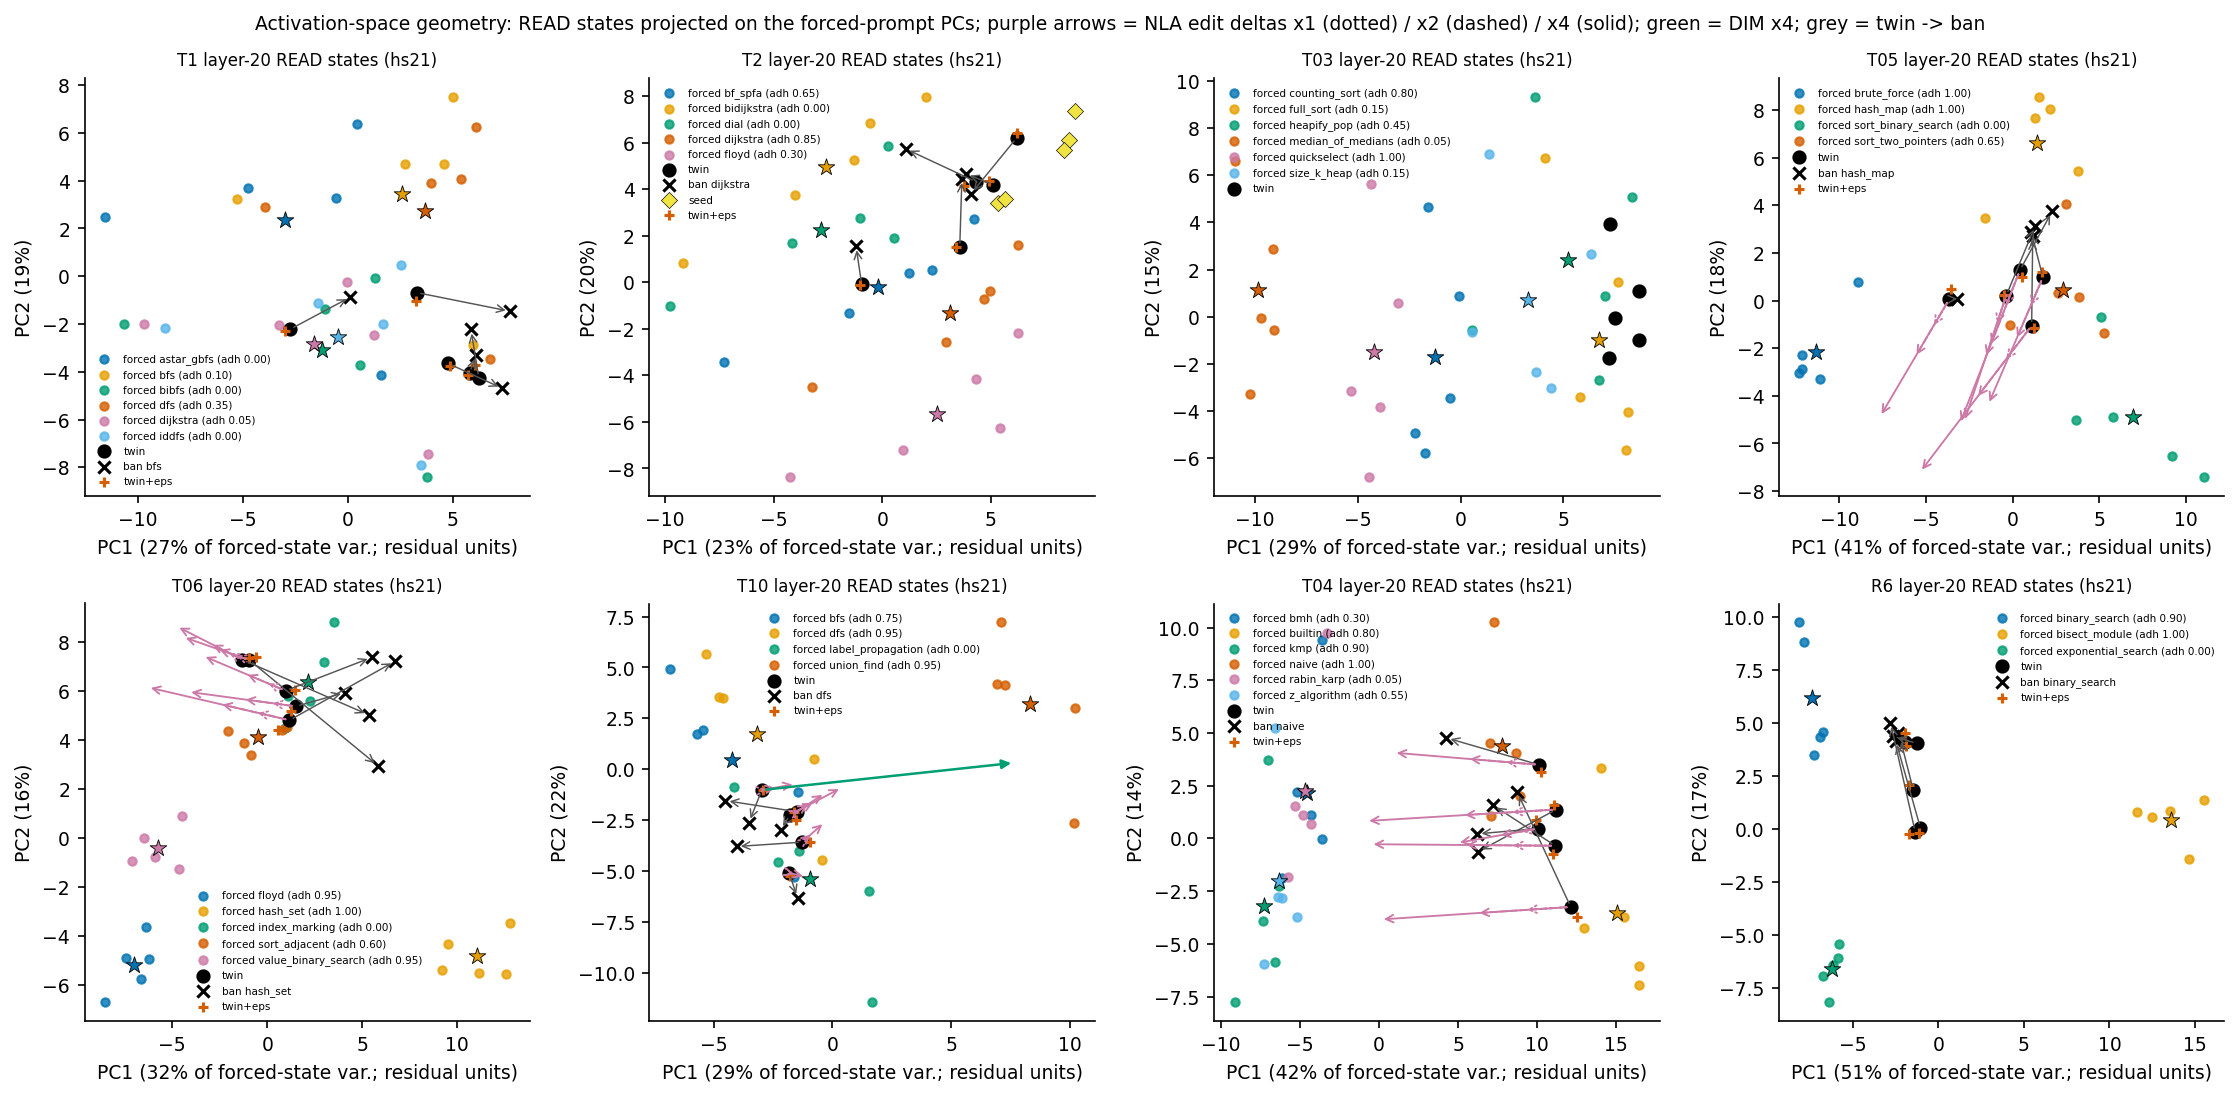

In [26]:
def f6_geometry() -> None:
    idx = IDX               # original: read_jsonl(CACHE_DIR / "states_index.jsonl")
    conv = LAYER_CONVENTION["chosen"]
    H = H21                 # original: z["H20"] if conv == "hs20" else z["H21"] (cache/states_L20.npz)
    c1 = C1                 # original: read_json(PRED_DIR / "commit1_defaults.json")
    beh = REP               # original: read_json(RESULTS_DIR / "behaviour.json")
    deltas = DELTAS         # original: {k.replace("__", "|"): v for k, v in np.load(CACHE_DIR / "deltas.npz").items()}
    fig, axes = plt.subplots(2, 4, figsize=(15, 7.4))
    for ax, t in zip(axes.flat, TASKS):
        rows = [r for r in idx if r.get("task") == t and r["kind"] == "PREFILL" and r["position"] == "READ"]
        forced = [r for r in rows if r["condition"] == "forced"]
        if len(forced) < 3:
            ax.set_visible(False)
            continue
        F = H[[r["row"] for r in forced]]
        mu = F.mean(0)
        U, S, Vt = np.linalg.svd(F - mu, full_matrices=False)
        pcs = Vt[:2]
        ve = (S[:2] ** 2) / (S ** 2).sum()
        proj = lambda X: (np.atleast_2d(X) - mu) @ pcs.T
        modes = sorted({r["mode"] for r in forced})
        for i, m in enumerate(modes):
            P = proj(H[[r["row"] for r in forced if r["mode"] == m]])
            adh = beh["tasks"][t]["forced"].get(m, {}).get("adherence")
            ax.scatter(P[:, 0], P[:, 1], s=16, color=PAL[i % len(PAL)], alpha=0.8,
                       label=f"forced {m} (adh {adh:.2f})" if adh is not None else f"forced {m}")
            ax.scatter(*P.mean(0), s=70, color=PAL[i % len(PAL)], marker="*", edgecolor="k", lw=0.4)
        tw = {r["template"]: r for r in rows if r["condition"] == "twin"}
        bn = {r["template"]: r for r in rows if r["condition"] == "ban"}
        Pt = proj(H[[tw[w]["row"] for w in TEMPLATE_IDS if w in tw]])
        ax.scatter(Pt[:, 0], Pt[:, 1], s=34, color="k", marker="o", label="twin")
        if bn:
            Pb = proj(H[[bn[w]["row"] for w in TEMPLATE_IDS if w in bn]])
            ax.scatter(Pb[:, 0], Pb[:, 1], s=34, color="k", marker="x", label=f"ban {c1['tasks'][t]['default']}")
            for a, b in zip(Pt, Pb):
                ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color="#555555", lw=0.7))
        sd = [r for r in rows if r["condition"] == "seed"]
        if sd:
            Ps = proj(H[[r["row"] for r in sd]])
            ax.scatter(Ps[:, 0], Ps[:, 1], s=30, color=PAL[6], marker="D", edgecolor="k", lw=0.3, label="seed")
        rd = [r for r in idx if r.get("task") == t and r["kind"] == "RAND" and r["position"] == "READ"]
        if rd:
            Pr = proj(H[[r["row"] for r in rd]])
            ax.scatter(Pr[:, 0], Pr[:, 1], s=22, color=PAL[3], marker="+", label="twin+eps")
        for j, w in enumerate(TEMPLATE_IDS):
            k = f"EDIT|{t}|TWIN|{w}|READ"
            if k in deltas and w in tw:
                h = H[tw[w]["row"]]
                for d, ls in ((1, ":"), (2, "--"), (4, "-")):
                    a, b = proj(h)[0], proj(h + d * deltas[k])[0]
                    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color=PAL[4], lw=0.9, ls=ls))
            kd = f"DIM|{t}|TWIN|{w}|READ"
            if kd in deltas and w in tw and j == 0:
                h = H[tw[w]["row"]]
                a, b = proj(h)[0], proj(h + 4 * deltas[kd])[0]
                ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", color=PAL[2], lw=1.2))
        ax.set_xlabel(f"PC1 ({ve[0] * 100:.0f}% of forced-state var.; residual units)")
        ax.set_ylabel(f"PC2 ({ve[1] * 100:.0f}%)")
        ax.set_title(f"{t} layer-20 READ states ({conv})", fontsize=8)
        ax.legend(fontsize=5, frameon=False, loc="best")
    fig.suptitle("Activation-space geometry: READ states projected on the forced-prompt PCs; purple arrows = NLA edit "
                 "deltas x1 (dotted) / x2 (dashed) / x4 (solid); green = DIM x4; grey = twin -> ban", fontsize=9)
    save(fig, "F6_geometry")


f6_geometry()

**Reading F6.** Every forced algorithm occupies its own region at READ. The twin and ban prompts sit apart from all of
them, because their prompt form differs ("Do not use …" against "Implement …").

The purple NLA edit arrows are short: about 0.04‖h‖ per dose unit, with ×4 drawn solid. In this two-dimensional
projection they head toward the forced-Y cluster most visibly on T05 (brute force) and T04 (KMP); the artifact's
README reads T06 and T10 the same way. Either way, patching these edits at the prefill positions changed nothing
behaviourally. That is the committed causal null.

### F8 — classical MDS of the forced-algorithm centroids

This is the centroid map from `analysis/geometry.py`, drawn with `src/figures.py`'s `f8_mds` (unchanged; it reads the
`GEO` dict computed above).
- **Marker area:** how many correct twin programs implement each algorithm.
- **Dashed ring:** the same count under the ban.
- **Arrow:** from the twin centroid to the ban centroid.

The ban often moves the state toward the banned default's *own* "Implement" direction: T05, T06 and R6. The ban
sentence names the default, and the state moves toward that name. The model then mostly writes the default anyway.

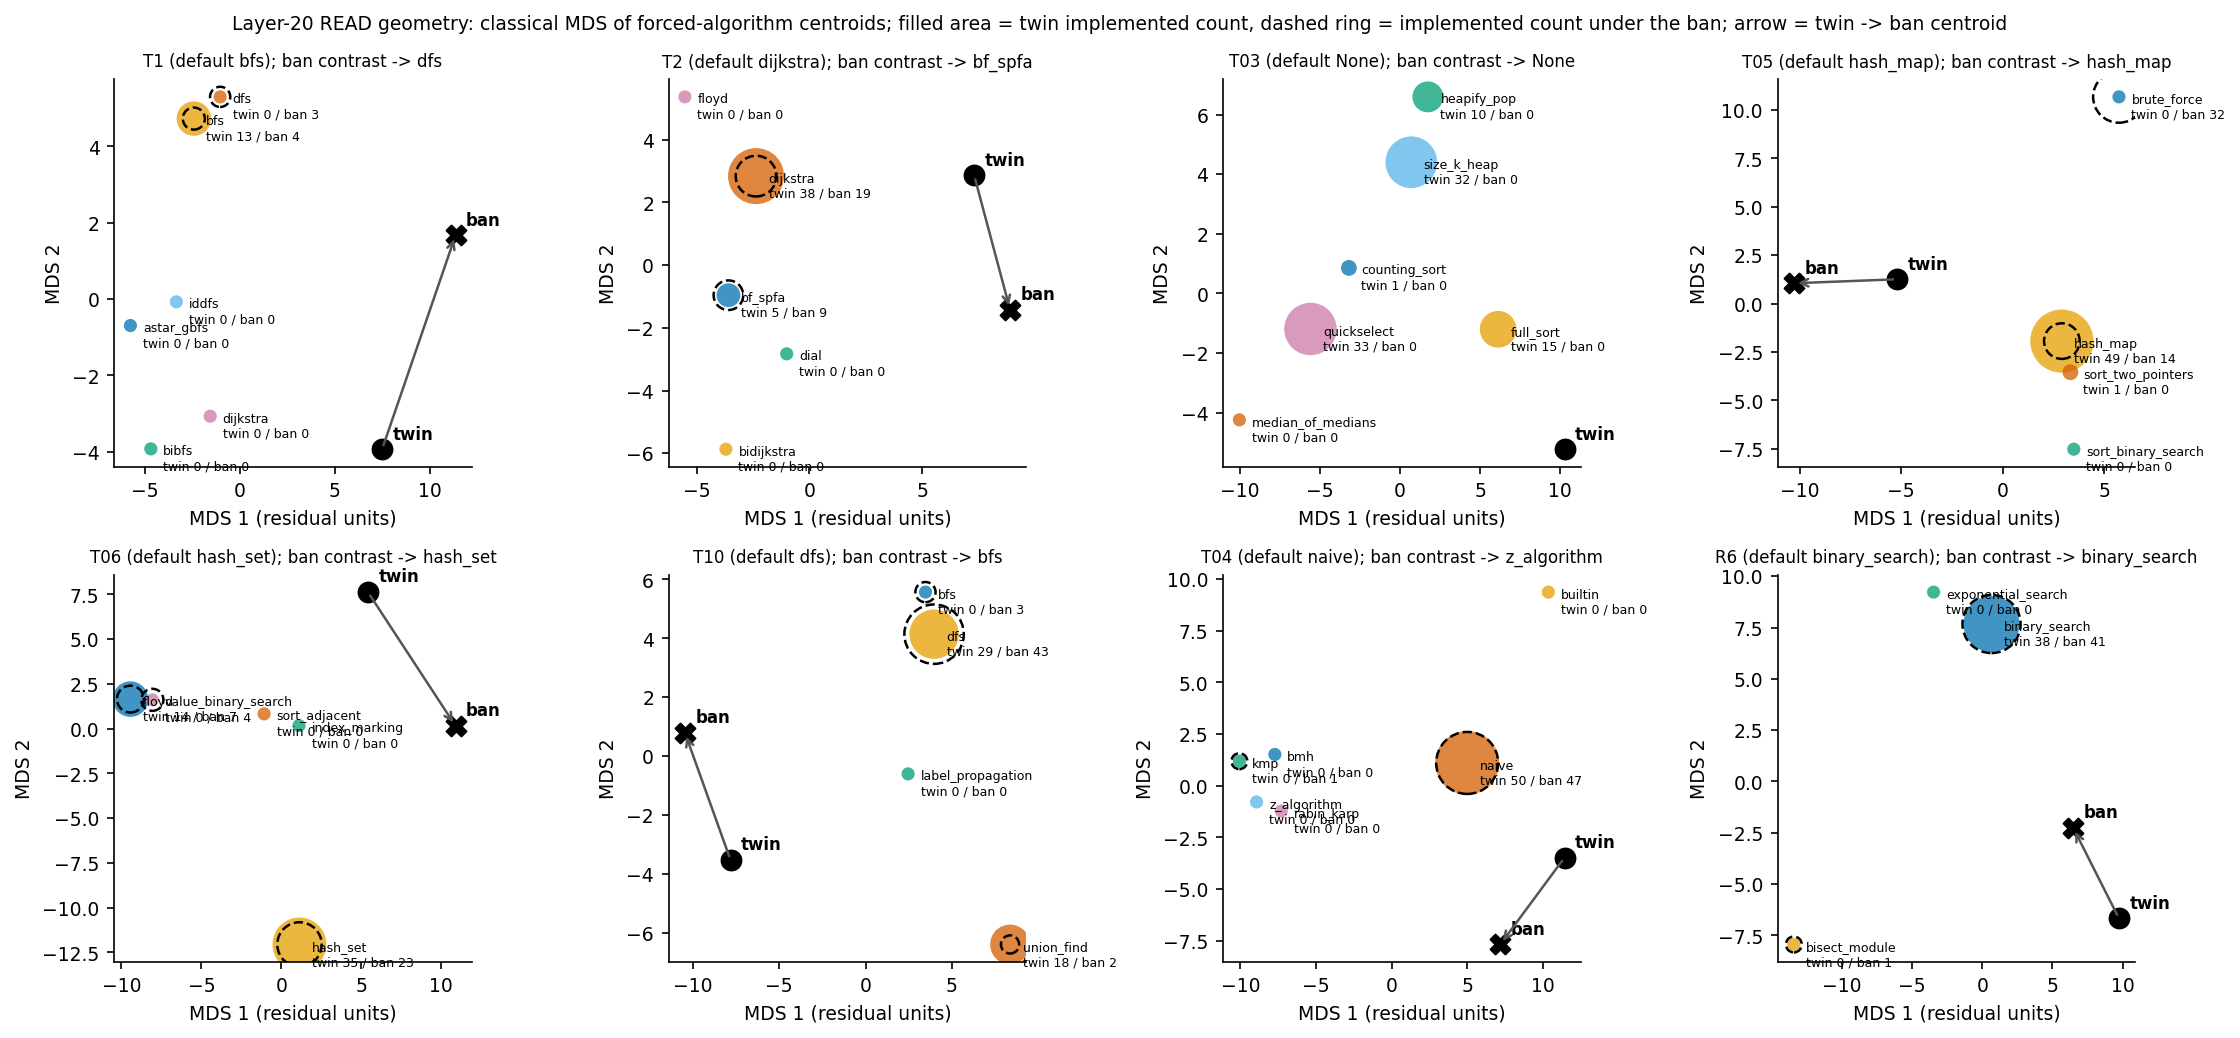

In [27]:
def f8_mds() -> None:
    """Classical MDS of the layer-20 READ centroids: forced 'Implement m' centroids (marker area = how many twin
    programs implemented m; outline = how many ban programs did), the twin and the ban centroids."""
    g = GEO   # original: read_json(RESULTS_DIR / "geometry.json")
    fig, axes = plt.subplots(2, 4, figsize=(15, 7))
    for ax, t in zip(axes.flat, TASKS):
        T = g["tasks"].get(t)
        if not T or "mds" not in T.get("READ", {}):
            ax.set_visible(False)
            continue
        M = T["READ"]["mds"]
        it, ib = T["implemented_twin"], T["implemented_ban"]
        for i, (n, (x, y)) in enumerate(M.items()):
            if n in ("twin", "ban"):
                ax.scatter(x, y, s=90, marker="o" if n == "twin" else "X", color="k", zorder=3)
                ax.annotate(n, (x, y), textcoords="offset points", xytext=(5, 5), fontsize=8, weight="bold")
                continue
            a = it.get(n, 0)
            b = ib.get(n, 0)
            ax.scatter(x, y, s=40 + 18 * a, color=PAL[i % len(PAL)], alpha=0.75, edgecolor="none")
            if b:
                ax.scatter(x, y, s=40 + 18 * b, facecolor="none", edgecolor="k", lw=1.2, ls="--")
            ax.annotate(f"{n}\ntwin {a} / ban {b}", (x, y), textcoords="offset points", xytext=(6, -10), fontsize=6)
        if "ban" in M and "twin" in M:
            ax.annotate("", xy=M["ban"], xytext=M["twin"], arrowprops=dict(arrowstyle="->", color="#555555", lw=1.2))
        ax.set_title(f"{t} (default {T['default']}); ban contrast -> {T['READ'].get('ban_contrast_mode')}", fontsize=8)
        ax.set_xlabel("MDS 1 (residual units)")
        ax.set_ylabel("MDS 2")
    fig.suptitle("Layer-20 READ geometry: classical MDS of forced-algorithm centroids; filled area = twin implemented "
                 "count, dashed ring = implemented count under the ban; arrow = twin -> ban centroid", fontsize=9)
    save(fig, "F8_mds_centroids")


f8_mds()

## The causal edit: building the edited explanations and the deltas (`src/nla_ar.py`)

The pre-registered causal arm is built from explanations of the *twin* states. On each causal task (T10 DFS →
union-find, T05 hash map → brute force, T06 hash set → Floyd, T04 naive → KMP), each twin state gets one of two edit
classes:
- **SUBSTITUTION.** Take the explanation that names the default D, choosing the one with the highest AR cosine among
  them, and replace every alias of D by Y's display name.
- **INSERTION.** If no explanation names D (the usual case), take the highest-cosine explanation and append "The
  response will implement D." against "… Y.".

The AR reconstructs both texts. The delta is (unit(r1) − unit(r0)) · ‖h‖, which is patched in at doses ×1/×2/×4. The
difference-in-means (DIM) control uses the forced-state direction unit(mean h_forced Y − mean h_forced D), scaled to the
edit's norm.

The cell below re-runs the text side unchanged (`alias_regex`, `case_like`, `substitute` and the selection rule) on
the twin READ states and compares the result with the committed edits (`results/edits.jsonl`, commit #3). It then
checks the vector side on the shipped deltas:
- ‖Δ_edit‖ / ‖h‖ against `deltas_meta`;
- the DIM direction recomputed from the forced READ states;
- the cosine between the edit and the DIM direction.

The AR itself and the unrelated-word control are not run, because they need the AR model and the Qwen tokenizer.

In [28]:
def alias_regex(aliases: list[str]) -> re.Pattern:
    parts = sorted({a.strip() for a in aliases if a.strip()}, key=len, reverse=True)
    pats = []
    for a in parts:
        p = re.escape(a)
        if re.match(r"\w", a[0]):
            p = r"(?<![\w-])" + p
        if re.match(r"\w", a[-1]):
            p = p + r"(?![\w])"
        pats.append(p)
    return re.compile("|".join(pats), re.I)


def case_like(src: str, repl: str) -> str:
    if src.isupper() and len(src) > 1:
        return repl.upper()
    if src[:1].isupper():
        return repl[:1].upper() + repl[1:]
    return repl


def substitute(text: str, rx: re.Pattern, repl: str) -> str:
    return rx.sub(lambda m: case_like(m.group(0), repl), text)


unit = lambda v: v / max(float(np.linalg.norm(v)), 1e-12)
row = IDX_BY_ID
ecos = COS
by_state: dict[str, list[dict[str, Any]]] = {}
for e in EXPL:
    by_state.setdefault(e["state_id"], []).append(e)
for v in by_state.values():
    v.sort(key=lambda e: e["idx"])
committed = {(r["state_id"], r["edit_class"] == "REVERSE"): r for r in META["edits_read"]}
dmeta = {m["key"]: m for m in META["deltas_meta_read"]}
lex = C2["lexicon"]
edit_rows = []
# --- nla_ar.stage_production(), edits block, READ position only (the AR calls and the unrelated edit left out) ---
for ct in C2["causal_plan"]:
    t, D, Y = ct["task"], ct["default"], ct["Y"]
    cat = {c["mode"]: c for c in CATALOGUE[t]}   # original: PR.catalogue(t)
    rxD = alias_regex(lex[t][D])
    dispD, dispY = cat[D]["display_name"], cat[Y]["display_name"]
    for w in TEMPLATE_IDS:
        for pos in ("READ",):   # original: ("SPEC-3", "SPEC-2", "SPEC-1", "READ"); the demo ships READ
            sid = f"{t}|twin|-|{w}|{pos}"
            es = by_state.get(sid, [])
            assert len(es) >= 2, f"{sid}: fewer than 2 explanations"
            named = [e for e in es if rxD.search(e["text"])]
            if named:
                e0 = max(named, key=lambda e: ecos[e["expl_id"]])
                cls = "SUBSTITUTION"
                t0 = e0["text"]
                t1 = substitute(t0, rxD, dispY)
                e0b = next((e for e in es if e["idx"] > e0["idx"]), None) or next(e for e in es if e is not e0)
                t0b = e0b["text"]
            else:
                e0 = max(es, key=lambda e: ecos[e["expl_id"]])
                cls = "INSERTION"
                t0 = e0["text"] + f" The response will implement {dispD}."
                t1 = e0["text"] + f" The response will implement {dispY}."
                e0b = next((e for e in es if e["idx"] > e0["idx"]), None) or next(e for e in es if e is not e0)
                t0b = e0b["text"] + f" The response will implement {dispD}."
            ref = committed[(sid, False)]
            # --- vector side, on the shipped READ vectors and deltas ---
            key = f"{t}|TWIN|{w}|{pos}"
            h = H21[row[sid]["row"]]
            hn = float(np.linalg.norm(h))
            d_edit = DELTAS[f"EDIT|{key}"]
            en = float(np.linalg.norm(d_edit))
            rec = {"task": t, "template": w, "class": cls, "e0": e0["expl_id"].split("|")[-1],
                   "texts == commit #3": (cls, e0["expl_id"], t0, t1, e0b["expl_id"], t0b) ==
                                         (ref["edit_class"], ref["e0_id"], ref["e0"], ref["e1"], ref["e0b_id"], ref["e0b"]),
                   "||d_edit||/||h||": round(en / hn, 5), "reported ratio": round(dmeta[key]["ratio_edit"], 5),
                   "sqrt(2(1-cos r1,r0))": round(dmeta[key]["check_ratio"], 5)}
            if f"DIM|{key}" in DELTAS:
                fY = [H21[row[f"{t}|forced|{Y}|{ww}|{pos}"]["row"]] for ww in TEMPLATE_IDS]
                fD = [H21[row[f"{t}|forced|{D}|{ww}|{pos}"]["row"]] for ww in TEMPLATE_IDS]
                dim = unit(np.mean(fY, 0) - np.mean(fD, 0)) * en       # = deltas[f"DIM|{key}"] in nla_ar.py
                rec["cos(DIM recomputed, shipped)"] = round(float(unit(dim) @ unit(DELTAS[f"DIM|{key}"])), 6)
                rec["cos(edit, DIM)"] = round(float(unit(d_edit) @ unit(DELTAS[f"DIM|{key}"])), 4)
                rec["reported cos(edit, DIM)"] = round(dmeta[key]["cos_edit_dim"], 4)
            edit_rows.append(rec)
    # reverse edits on ban states that name Y*
    rxY = alias_regex(lex[t][Y])
    for w in TEMPLATE_IDS:
        for pos in ("READ",):
            sid = f"{t}|ban|{D}|{w}|{pos}"
            if sid not in by_state:
                continue
            named = [e for e in by_state[sid] if e.get("text") and rxY.search(e["text"])]
            if named:
                e0 = max(named, key=lambda e: ecos[e["expl_id"]])
                ref = committed.get((sid, True), {})
                edit_rows.append({"task": t, "template": w, "class": "REVERSE", "e0": e0["expl_id"].split("|")[-1],
                                  "texts == commit #3": (e0["expl_id"], substitute(e0["text"], rxY, dispD)) ==
                                                        (ref.get("e0_id"), ref.get("e1"))})
# ---
N_EDITS_MATCH = sum(r["texts == commit #3"] for r in edit_rows)
N_EDITS_COMMITTED = len(META["edits_read"])
print(f"edited explanation texts rebuilt: {N_EDITS_MATCH}/{len(edit_rows)} identical to commit #3 "
      f"({N_EDITS_COMMITTED} committed READ edits)")
ex_edit = committed[("T06|twin|-|W1|READ", False)]
print("\nT06 W1 (", ex_edit["edit_class"], ") ... e0 ends:", repr(ex_edit["e0"][-110:]))
print("                       ... e1 ends:", repr(ex_edit["e1"][-110:]))
print("unrelated-word control eU (committed; needs the tokenizer):", ex_edit.get("unrelated_word"))
pd.DataFrame(edit_rows).set_index(["task", "template"])

edited explanation texts rebuilt: 21/21 identical to commit #3 (21 committed READ edits)

T06 W1 ( INSERTION ) ... e0 ends: 's a solution:" to show the actual implementation logic. The response will implement a hash set of seen values.'
                       ... e1 ends: ' is a solution:" to show the actual implementation logic. The response will implement Floyd\'s cycle detection.'
unrelated-word control eU (committed; needs the tokenizer): ['pattern', 'man']


class      e0  texts == commit #3  ||d_edit||/||h||  \
task template                                                               
T10  W1           INSERTION  hs21#5                True           0.02653   
     W2           INSERTION  hs21#3                True           0.02601   
     W3           INSERTION  hs21#2                True           0.02756   
     W4           INSERTION  hs21#6                True           0.02754   
     W5           INSERTION  hs21#3                True           0.02168   
T05  W1           INSERTION  hs21#5                True           0.04475   
     W2           INSERTION  hs21#5                True           0.05251   
     W3           INSERTION  hs21#5                True           0.04935   
     W4           INSERTION  hs21#4                True           0.03809   
     W5           INSERTION  hs21#1                True           0.03949   
     W4             REVERSE  hs21#2                True               NaN   
T06  W1           INSERTION  hs21#2                True           0.04749   
     W2           INSERTION  hs21#5                True           0.03228   
     W3           INSERTION  hs21#1                True           0.03004   
     W4           INSERTION  hs21#1                True           0.03397   
     W5           INSERTION  hs21#2                True           0.04237   
T04  W1           INSERTION  hs21#2                True           0.06641   
     W2        SUBSTITUTION  hs21#1                True           0.03493   
     W3           INSERTION  hs21#6                True           0.05805   
     W4           INSERTION  hs21#3                True           0.06028   
     W5           INSERTION  hs21#6                True           0.05320   

               reported ratio  sqrt(2(1-cos r1,r0))  \
task template                                         
T10  W1               0.02653               0.02653   
     W2               0.02601               0.02601   
     W3               0.02756               0.02756   
     W4               0.02754               0.02754   
     W5               0.02168               0.02168   
T05  W1               0.04475               0.04475   
     W2               0.05251               0.05251   
     W3               0.04935               0.04935   
     W4               0.03809               0.03809   
     W5               0.03949               0.03949   
     W4                   NaN                   NaN   
T06  W1               0.04749               0.04749   
     W2               0.03228               0.03227   
     W3               0.03004               0.03004   
     W4               0.03397               0.03398   
     W5               0.04237               0.04237   
T04  W1               0.06641               0.06641   
     W2               0.03493               0.03493   
     W3               0.05805               0.05805   
     W4               0.06028               0.06028   
     W5               0.05320               0.05320   

               cos(DIM recomputed, shipped)  cos(edit, DIM)  \
task template                                                 
T10  W1                                 1.0          0.1763   
     W2                                 NaN             NaN   
     W3                                 NaN             NaN   
     W4                                 NaN             NaN   
     W5                                 NaN             NaN   
T05  W1                                 1.0          0.2892   
     W2                                 NaN             NaN   
     W3                                 NaN             NaN   
     W4                                 NaN             NaN   
     W5                                 NaN             NaN   
     W4                                 NaN             NaN   
T06  W1                                 1.0          0.3696   
     W2                                 NaN             NaN   
     W3                                

The verbal edit hardly moves the reconstruction. Appending "…Y" instead of "…D" leaves the AR output at a cosine of
about 0.999, so ‖Δ_edit‖ is about 0.04‖h‖, which equals √(2(1 − cos)) exactly (the artifact's unit test U8). The edit
direction is nearly orthogonal to the forced-state difference in means.

## Independent re-derivation (`audit/rederive.py`)

The audit recomputes the headline tests with the Python standard library only. It uses no numpy or scipy and does not
import `analysis/`: it has its own exact binomial test and its own vote and label lookups. The tests are N1, N2, N8b,
N3, N6, the gate FVE from the cosines, and a placebo. In the placebo, the twin naming labels are shuffled against the
NLA labels within each task. It must not produce an effect where there was none.

The script is unchanged except for its inputs, which are the rebuilt tables. Its causal block needs the causal-arm
labels (`data/labels_causal.jsonl`), which are not in the demo data, so that block is skipped through the script's own
`if c3p.exists() and lab:` guard.

In [29]:
def rederive_main() -> dict[str, Any]:   # original: main() of audit/rederive.py
    POS4 = ("SPEC-3", "SPEC-2", "SPEC-1", "READ")
    W4 = ("W1", "W2", "W3", "W5")

    def binom_two_sided(b, n):
        if n == 0:
            return 1.0
        pmf = [math.comb(n, k) * 0.5 ** n for k in range(n + 1)]
        obs = pmf[b]
        return min(1.0, sum(p for p in pmf if p <= obs * (1 + 1e-7)))

    def mcnemar(xs, ys):
        b = sum(1 for x, y in zip(xs, ys) if x == 1 and y == 0)
        c = sum(1 for x, y in zip(xs, ys) if x == 0 and y == 1)
        n = len(xs)
        eff = (sum(xs) - sum(ys)) / n if n else None
        return {"n": n, "b": b, "c": c, "p": binom_two_sided(b, b + c), "effect": eff}

    c2 = C2                     # original: predictions/commit2_readout.json
    tasks = c2["tasks"]
    jud = JUD                   # original: jl("data/judgements.jsonl")
    expl = defaultdict(list)
    text = {}
    for r in jud:
        if r["mode"] == "EXPL":
            expl[r["state_id"]].append(r)
        else:
            text[(r["mode"], r["text_id"])] = r["resolved"]

    def x(sid, tgt):
        rs = sorted(expl.get(sid, []), key=lambda r: int(r["expl_id"].split("#")[-1]))[:3]
        if not rs:
            return None
        h = sum(1 for r in rs if r["resolved"] == tgt)
        return 1 if (h >= 2 if len(rs) >= 2 else h >= 1) else 0

    def y(tid, tgt, mode="NAME"):
        v = text.get((mode, tid))
        return None if v is None else int(v == tgt)

    out = {}
    # N1
    xs, ys = [], []
    for t, v in tasks.items():
        if not v.get("eligible"):
            continue
        for w in W4:
            for p in POS4:
                a, b = x(f"{t}|ban|{v['default']}|{w}|{p}", v["Ystar"]), y(f"{t}|ban|{v['default']}|{w}|PREFILL", v["Ystar"])
                if a is not None and b is not None:
                    xs.append(a)
                    ys.append(b)
    out["N1"] = mcnemar(xs, ys)
    # N2
    xs, ys, pairs = [], [], []
    for t, v in tasks.items():
        if not v.get("default") or not v.get("regate_pass", True):
            continue
        for w in W4:
            for p in POS4:
                a, b = x(f"{t}|twin|-|{w}|{p}", v["default"]), y(f"{t}|twin|-|{w}|PREFILL", v["default"])
                if a is not None and b is not None:
                    xs.append(a)
                    ys.append(b)
                    pairs.append((t, w, p))
    out["N2"] = mcnemar(xs, ys)
    # N8b
    xs, ys = [], []
    for t, v in tasks.items():
        if v.get("default") and not v.get("Ystar") and v.get("regate_pass", True):
            for w in W4:
                for p in POS4:
                    a = x(f"{t}|ban|{v['default']}|{w}|{p}", v["default"])
                    b = y(f"{t}|ban|{v['default']}|{w}|PREFILL", v["default"], "PREDICT")
                    if a is not None and b is not None:
                        xs.append(a)
                        ys.append(b)
    out["N8b_vs_predict"] = mcnemar(xs, ys)
    # N3
    n3 = {}
    for t, v in tasks.items():
        if not v.get("regate_pass", True):
            continue
        vals = [x(f"{t}|forced|{m}|{w}|{p}", m) for m in v.get("forced_readout_modes", []) for w in
                ("W1", "W2", "W3", "W4", "W5") for p in POS4]
        vals = [a for a in vals if a is not None]
        if vals:
            n3[t] = sum(vals) / len(vals)
    out["N3"] = n3
    # placebo: shuffle twin/default naming against the ban text within a task (N2 x vs a permuted y)
    rng = random.Random(11)
    by_task = defaultdict(list)
    for (t, w, p), a, b in zip(pairs, xs[:len(pairs)], ys[:len(pairs)]):
        by_task[t].append((a, b))
    # N6: per-sample accuracy at generated tokens in MIXED conditions, pre-identifying positions, NLA vs PREDICT
    idx_all = {r["state_id"]: r for r in IDX}                 # original: jl("cache/states_index.jsonl")
    labels = {r["sample_id"]: r for r in LABELS}              # original: jl("data/labels.jsonl")
    named_excl = {"none_named", "other", "unresolved", None}
    units = []
    for sid, r in idx_all.items():
        if r["kind"] != "GEN" or not tasks.get(r["task"], {}).get("regate_pass", True):
            continue
        lab = labels.get(r["sample_id"])
        if lab is None:
            continue
        tid = f"{r['task']}|{r['condition']}|{r.get('mode') or '-'}|{r['template']}|{r['position']}|{r['slot']}"
        units.append({"sample": r["sample_id"], "g": int(r["position"][1:]), "mixed": bool(r.get("mixed")),
                      "x": x(sid, lab["label"]), "y": y(tid, lab["label"], "PREDICT"),
                      "name": text.get(("NAME", tid))})
    first = {}
    for u in sorted(units, key=lambda u: u["g"]):
        if u["name"] not in named_excl and u["sample"] not in first:
            first[u["sample"]] = u["g"]
    sel = [u for u in units if u["mixed"] and u["g"] < first.get(u["sample"], 10 ** 6)
           and u["x"] is not None and u["y"] is not None]
    out["N6"] = mcnemar([u["x"] for u in sel], [u["y"] for u in sel])
    # gate FVE from cosines
    gate = REPORTED["gate"]                                   # original: results/gate.json
    cos = COS                                                 # original: results/explanation_cosines.json
    idx = {r["state_id"]: r for r in IDX}
    ro = [k for k in cos if k.split("|")[-1].split("#")[0] == gate["convention"] and "#" in k
          and int(k.split("#")[-1]) <= 3 and idx.get(k.rsplit("|", 1)[0], {}).get("kind") in ("PREFILL", "GEN")]
    mse = [2 * (1 - cos[k]) for k in ro]
    den = gate["reference"]["denominator_ref"]
    out["gate_fve_ref_all"] = {"rederived": 1 - (sum(mse) / len(mse)) / den if mse else None,
                               "reported": gate["classes"]["ALL"]["fve_ref"], "n": len(mse)}
    # causal
    lab = []                    # original: jl("data/labels_causal.jsonl") -- the causal-arm labels are not shipped
    beh = LABELS
    c3p = ROOT / "predictions" / "commit3_causal.json"
    caus = {}
    if c3p.exists() and lab:
        c3 = json.loads(c3p.read_text())
        for ct in c3["causal_plan"]:
            t, Y = ct["task"], ct["Y"]
            cells = defaultdict(dict)
            for r in lab:
                if r["task"] == t:
                    cells[r["cell"]][(r["template"], int(r["slot"]))] = int(bool(r.get("passed")) and r["label"] == Y)
            c0 = {(r["template"], int(r["slot"])): int(bool(r.get("passed")) and r["label"] == Y)
                  for r in beh if r["task"] == t and r["arm"] == "TWIN" and int(r["slot"]) < 6}
            res = {}
            for d in ("x1", "x2", "x4"):
                E, R = cells.get(f"PRE_EDIT_{d}"), cells.get(f"PRE_RT_{d}")
                if E and R:
                    k = sorted(set(E) & set(R))
                    res[d] = mcnemar([E[i] for i in k], [R[i] for i in k])
                RA = cells.get(f"PRE_RAND_{d}")
                if RA:
                    k = sorted(set(RA) & set(c0))
                    res[f"placebo_RAND_vs_C0_{d}"] = mcnemar([RA[i] for i in k], [c0[i] for i in k])
            caus[t] = res
    out["causal"] = caus
    # N1/N2 placebo: within-task shuffle of the NLA labels across (template, position) units against the text
    plac = []
    for t, lst in by_task.items():
        a_ = [a for a, _ in lst]
        b_ = [b for _, b in lst]
        rng.shuffle(b_)
        plac += list(zip(a_, b_))
    out["placebo_N2_shuffled_text"] = mcnemar([a for a, _ in plac], [b for _, b in plac]) if plac else None
    return out   # original: (ROOT / "results" / "rederive.json").write_text(json.dumps(out, indent=1))


RD = rederive_main()
print(json.dumps({k: (v if not isinstance(v, dict) or len(str(v)) < 300 else "...") for k, v in RD.items()})[:1500])

{"N1": {"n": 16, "b": 0, "c": 0, "p": 1.0, "effect": 0.0}, "N2": {"n": 112, "b": 0, "c": 0, "p": 1.0, "effect": 0.0}, "N8b_vs_predict": {"n": 96, "b": 0, "c": 0, "p": 1.0, "effect": 0.0}, "N3": {"T1": 0.0, "T2": 0.0, "T05": 0.0, "T06": 0.0, "T10": 0.0, "T04": 0.0, "R6": 0.0}, "N6": {"n": 364, "b": 20, "c": 88, "p": 2.3222098297326024e-11, "effect": -0.18681318681318682}, "gate_fve_ref_all": {"rederived": 0.5118216841757339, "reported": 0.5118216276168823, "n": 5490}, "causal": {}, "placebo_N2_shuffled_text": {"n": 96, "b": 0, "c": 0, "p": 1.0, "effect": 0.0}}


### Headline audit (`audit/rederive_headlines.py`)

This second auditor re-derives the README headlines that `rederive.py` does not cover, again through its own code.
- **Behaviour.** The defaults, the 15 union-find → DFS flips on T10, and W4's 70/70.
- **Mention rate.** How often prefill explanations mention the algorithm named in the prompt.
- **N6 with a placebo.** The arms are swapped at random inside each pair, using `N_PLACEBO_SWAPS` permutations
  (originally 2,000). A real effect must disappear under the swap, so the share of placebo permutations reaching
  p < 0.05 should be near 0.

The script runs at the top level in the artifact. Here it is wrapped in a function so that its helper names (`paired`,
`rows`) do not shadow the readout helpers above. Its gate, exploratory-causal and local-control blocks are left out,
because they need the AR vectors and the exploratory datasets.

In [30]:
def rederive_headlines_main() -> dict[str, Any]:
    def p_two_sided(b, n):
        if n == 0:
            return 1.0
        tail = sum(math.comb(n, k) for k in range(0, min(b, n - b) + 1)) / 2 ** n
        return min(1.0, 2 * tail)

    def paired(a, b):
        """a, b: dict slot -> 0/1 outcome. Returns discordant counts and exact two-sided p."""
        ks = sorted(set(a) & set(b))
        bb = sum(1 for k in ks if a[k] == 1 and b[k] == 0)
        cc = sum(1 for k in ks if a[k] == 0 and b[k] == 1)
        return {"n": len(ks), "b": bb, "c": cc, "p": p_two_sided(bb, bb + cc)}

    def swap_placebo(a, b, n_perm=N_PLACEBO_SWAPS, seed=3):   # original default: n_perm=2000
        """Randomly exchange the two arms inside each pair; share of permutations reaching p < 0.05 (should be ~<= 0.05)."""
        rng = random.Random(seed)
        ks = sorted(set(a) & set(b))
        hits = 0
        for _ in range(n_perm):
            x, y = {}, {}
            for k in ks:
                if rng.random() < 0.5:
                    x[k], y[k] = b[k], a[k]
                else:
                    x[k], y[k] = a[k], b[k]
            hits += paired(x, y)["p"] < 0.05
        return hits / n_perm

    out = {}
    lab = LABELS   # original: rows("data/labels.jsonl")
    # ---------------------------------------------------------------- behaviour
    twin = [r for r in lab if r["arm"] == "TWIN" and int(r["slot"]) < 10]
    ban = [r for r in lab if r["arm"] == "BAN"]
    beh = {}
    for t in sorted({r["task"] for r in twin}):
        tc = Counter(r["label"] for r in twin if r["task"] == t and r["passed"])
        bc = Counter(r["label"] for r in ban if r["task"] == t and r["passed"])
        top = tc.most_common(1)[0]
        beh[t] = {"twin_correct": dict(tc), "default_share": round(top[1] / sum(tc.values()), 3), "ban_correct": dict(bc)}
    out["behaviour"] = beh
    tmap = {(r["task"], r["template"], int(r["slot"])): r["label"] for r in twin}
    flips = Counter((r["task"], tmap.get((r["task"], r["template"], int(r["slot"]))), r["label"]) for r in ban)
    out["T10_union_find_to_dfs_flips"] = flips[("T10", "union_find", "dfs")]
    w4 = [r for r in ban if r["template"] == "W4"]
    defaults = C1["tasks"]   # original: json.loads((ROOT / "predictions" / "commit1_defaults.json").read_text())["tasks"]
    out["W4_attempts_default"] = f"{sum(r['label'] == defaults[r['task']]['default'] for r in w4)}/{len(w4)}"
    # (instrument-gate block left out: it needs cache/recon.npz, the AR vectors, and the reference-set states)
    # ---------------------------------------------------------------- readout: prefill mention rate, N6 placebo
    jud = JUD                                        # original: rows("data/judgements.jsonl")
    sidx = {r["state_id"]: r for r in IDX}           # original: rows("cache/states_index.jsonl")
    c2 = C2["tasks"]
    men = defaultdict(lambda: [0, 0])
    for j in jud:
        if j["mode"] != "EXPL":
            continue
        r = sidx[j["state_id"]]
        if r["kind"] != "PREFILL" or r["condition"] not in ("forced", "ban"):
            continue
        tgt = r.get("mode")
        men[r["condition"]][0] += tgt in (j.get("mentioned_any") or [])
        men[r["condition"]][1] += 1
    out["prefill_mentions_named_algorithm"] = {k: f"{v[0]}/{v[1]}" for k, v in men.items()}
    expl = defaultdict(list)
    text = {}
    for j in jud:
        if j["mode"] == "EXPL":
            expl[j["state_id"]].append(j)
        else:
            text[(j["mode"], j["text_id"])] = j["resolved"]
    labmap = {r["sample_id"]: r for r in lab}
    units = []
    for sid, r in sidx.items():
        if r["kind"] != "GEN" or not r.get("mixed") or not c2.get(r["task"], {}).get("regate_pass", True):
            continue
        L = labmap.get(r["sample_id"])
        if L is None:
            continue
        tid = f"{r['task']}|{r['condition']}|{r.get('mode') or '-'}|{r['template']}|{r['position']}|{r['slot']}"
        es = sorted(expl.get(sid, []), key=lambda e: int(e["expl_id"].split("#")[-1]))[:3]
        if not es or text.get(("PREDICT", tid)) is None:
            continue
        units.append({"key": sid, "sample": r["sample_id"], "g": int(r["position"][1:]),
                      "x": int(sum(e["resolved"] == L["label"] for e in es) >= 2),
                      "y": int(text[("PREDICT", tid)] == L["label"]), "name": text.get(("NAME", tid))})
    first = {}
    for u in sorted(units, key=lambda u: u["g"]):
        if u["name"] not in (None, "none_named", "other", "unresolved") and u["sample"] not in first:
            first[u["sample"]] = u["g"]
    sel = [u for u in units if u["g"] < first.get(u["sample"], 99)]
    A = {u["key"]: u["x"] for u in sel}
    B = {u["key"]: u["y"] for u in sel}
    out["N6"] = paired(A, B) | {"nla_acc": round(sum(A.values()) / len(A), 3), "predict_acc": round(sum(B.values()) / len(B), 3),
                                "placebo_swap_share_p_lt_05": swap_placebo(A, B)}
    # (exploratory-causal and local-control blocks left out: data/labels_causal_extra*.jsonl and
    #  data/local_judgements.jsonl are not in the demo data; their reported values are shown at the end)
    return out


RH = rederive_headlines_main()
print("T10 union-find -> DFS flips:", RH["T10_union_find_to_dfs_flips"], "| W4 attempts using the default:",
      RH["W4_attempts_default"])
print("prefill explanations mentioning the prompt's own algorithm:", RH["prefill_mentions_named_algorithm"])
print("N6:", RH["N6"])

T10 union-find -> DFS flips: 15 | W4 attempts using the default: 70/70
prefill explanations mentioning the prompt's own algorithm: {'ban': '3/420', 'forced': '8/1080'}
N6: {'n': 364, 'b': 20, 'c': 88, 'p': 2.3222098297326024e-11, 'nla_acc': 0.066, 'predict_acc': 0.253, 'placebo_swap_share_p_lt_05': 0.049}


## Results: recomputed versus reported

The table below sets every deterministic headline recomputed in this notebook beside the value in the artifact's
result files (`metadata.reported` and the commits). These are counts, rates, exact McNemar statistics, FVE values,
geometry modes and edit texts. None of them depends on the resampling settings in the configuration cell, so every
row should match for any setting. The resampled quantities are added as a `resampling` section only when the
configuration equals the artifact's (2000 / 10000 / 1000 / 2000, the default). They then reproduce too, because every
resampler uses the artifact's fixed seeds: bootstrap intervals, Hill-1 diversities, the permutation p and the placebo
share.

In [31]:
CHECKS: list[dict[str, Any]] = []


def chk(section: str, name: str, mine: Any, ref: Any, tol: float = 1e-6) -> None:
    if isinstance(mine, (int, float)) and isinstance(ref, (int, float)) and not isinstance(mine, bool):
        ok = abs(float(mine) - float(ref)) <= tol
    else:
        ok = mine == ref
    CHECKS.append({"section": section, "quantity": name, "recomputed": mine, "reported": ref, "match": ok})


RB, RR, RGEO = REPORTED["behaviour"]["tasks"], REPORTED["readout"], REPORTED["geometry"]["tasks"]
for t in TASKS:
    chk("behaviour", f"{t} default (commit #1)", DEF1["tasks"][t]["default"], C1["tasks"][t]["default"])
    chk("behaviour", f"{t} modal share of correct twin programs", DEF1["tasks"][t]["modal_share"], C1["tasks"][t]["modal_share"])
    chk("behaviour", f"{t} twin correct labels", REP["tasks"][t]["twin"]["correct"], RB[t]["twin"]["correct"])
    if RB[t].get("ban"):
        chk("behaviour", f"{t} ban correct labels", REP["tasks"][t]["ban"]["correct"], RB[t]["ban"]["correct"])
        chk("behaviour", f"{t} substitute Y*", REP["tasks"][t]["Ystar"], RB[t]["Ystar"])
        chk("behaviour", f"{t} paired twin->ban flips", [list(x) for x in REP["tasks"][t]["paired_flip"]],
            [list(x) for x in RB[t]["paired_flip"]])
for ct in C2["causal_plan"]:
    t, Y = ct["task"], ct["Y"]
    chk("behaviour", f"{t} forced adherence of the causal Y ({Y})", REP["tasks"][t]["forced"][Y]["adherence"],
        RB[t]["forced"][Y]["adherence"])
chk("behaviour", "T10 union-find -> DFS flips (paired slots)", RH["T10_union_find_to_dfs_flips"],
    REPORTED["rederive_headlines"]["T10_union_find_to_dfs_flips"])
chk("behaviour", "W4 ban attempts using the default", RH["W4_attempts_default"], REPORTED["rederive_headlines"]["W4_attempts_default"])
chk("judges", "resolved labels re-derived from J1/J2/J3", f"{N_RESOLVED_MATCH}/{len(JUD)}", f"{len(JUD)}/{len(JUD)}")
for mode in ("EXPL", "NAME", "PREDICT"):
    chk("judges", f"{mode} J1-J2 kappa", READOUT["judge_agreement"][mode]["kappa_J1_J2"], RR["judge_agreement"][mode]["kappa_J1_J2"])
for c in GATE["classes"]:
    chk("gate", f"FVE_ref {c}", GATE["classes"][c]["fve_ref"], REPORTED["gate"]["classes"][c]["fve_ref"], tol=1e-5)
chk("gate", "verdict", GATE["verdict"], REPORTED["gate"]["verdict"])
for k, rk in (("N1", "N1"), ("N1_swap", "N1_swap"), ("N1_rand", "N1_rand"), ("N1_predict", "N1_predict"),
              ("N2_default", "N2_default"), ("N6_per_sample", "N6_per_sample"),
              ("N8b_banfail_default_vs_predict", "N8b_banfail_default_vs_predict"),
              ("N8b_banfail_default_vs_name", "N8b_banfail_default_vs_name")):
    chk("readout", f"{k} n / b / c", [READOUT[k]["n"], READOUT[k]["b"], READOUT[k]["c"]], [RR[rk]["n"], RR[rk]["b"], RR[rk]["c"]])
    chk("readout", f"{k} p (exact McNemar)", READOUT[k]["p"], RR[rk]["p"], tol=1e-12)
    chk("readout", f"{k} NLA rate vs comparator rate", [READOUT[k]["x_rate"]["rate"], READOUT[k]["y_rate"]["rate"]],
        [RR[rk]["x_rate"]["rate"], RR[rk]["y_rate"]["rate"]])
chk("readout", "N1 pass (pre-registered rule)", READOUT["N1"]["pass"], RR["N1"]["pass"])
chk("readout", "N2 pass (pre-registered rule)", READOUT["N2_default"]["pass"], RR["N2_default"]["pass"])
for t, v in READOUT["N3_forced"]["tasks"].items():
    chk("readout", f"N3 {t}: NLA / text-only naming rate", [v["nla"]["rate"], v["text_only"]["rate"]],
        [RR["N3_forced"]["tasks"][t]["nla"]["rate"], RR["N3_forced"]["tasks"][t]["text_only"]["rate"]])
chk("readout", "N3 tasks passing (>= 0.7)", READOUT["N3_forced"]["n_tasks_pass"], RR["N3_forced"]["n_tasks_pass"])
chk("readout", "N4 NLA planned majority on the seed states", READOUT["N4_seed"]["nla_planned_majority"], RR["N4_seed"]["nla_planned_majority"])
chk("readout", "N5 share of pre-identifying units", READOUT["N5_gen"]["share_pre_identifying"], RR["N5_gen"]["share_pre_identifying"])
for cond, g in (("ban", "g8"), ("twin", "g4")):
    chk("readout", f"N5 NLA rate, {cond} {g}", READOUT["N5_gen"]["curves_pre_identifying"][cond][g]["nla"]["rate"],
        RR["N5_gen"]["curves_pre_identifying"][cond][g]["nla"]["rate"])
chk("readout", "N6 samples behind the units", READOUT["N6_per_sample"]["n_samples"], RR["N6_per_sample"]["n_samples"])
for k, v in READOUT["holm_secondary"].items():
    chk("readout", f"Holm-adjusted p, {k}", v, RR["holm_secondary"][k], tol=1e-12)
for c, tab in READOUT["naming_table"].items():
    for p_, v in tab.items():
        chk("readout", f"naming rate {c} {p_}", v["rate"], RR["naming_table"][c][p_]["rate"])
chk("readout", "planned distribution (all task | condition cells)", READOUT["planned_distribution"], RR["planned_distribution"])
for t, v in GEO["tasks"].items():
    R, Rr = v["READ"], RGEO[t]["READ"]
    chk("geometry", f"{t} nearest forced centroid to the twin centroid", min(R["dist_twin_to_forced"], key=R["dist_twin_to_forced"].get),
        min(Rr["dist_twin_to_forced"], key=Rr["dist_twin_to_forced"].get))
    chk("geometry", f"{t} max twin-to-forced distance", max(R["dist_twin_to_forced"].values()), max(Rr["dist_twin_to_forced"].values()), tol=1e-3)
    if "ban_contrast_mode" in Rr:
        chk("geometry", f"{t} ban contrast mode", R["ban_contrast_mode"], Rr["ban_contrast_mode"])
        chk("geometry", f"{t} ban aligned mode", R["ban_aligned_mode"], Rr["ban_aligned_mode"])
        chk("geometry", f"{t} max ban contrast cos", max(R["ban_contrast_cos"].values()), max(Rr["ban_contrast_cos"].values()), tol=1e-4)
    chk("geometry", f"{t} implemented counts (twin, ban)", [v["implemented_twin"], v["implemented_ban"]],
        [RGEO[t]["implemented_twin"], RGEO[t]["implemented_ban"]])
chk("causal edit", "edited explanation texts identical to commit #3", f"{N_EDITS_MATCH}/{len(edit_rows)}", f"{N_EDITS_COMMITTED}/{N_EDITS_COMMITTED}")
chk("causal edit", "max |  ||d_edit||/||h|| - reported ratio |",
    max(abs(r["||d_edit||/||h||"] - r["reported ratio"]) for r in edit_rows if "reported ratio" in r), 0.0, tol=1e-4)
chk("causal edit", "min cos(DIM recomputed, shipped)",
    min(r["cos(DIM recomputed, shipped)"] for r in edit_rows if "cos(DIM recomputed, shipped)" in r), 1.0, tol=1e-4)
for k, rk in (("N1", "N1"), ("N2", "N2"), ("N8b_vs_predict", "N8b_vs_predict"), ("N6", "N6")):
    chk("audit", f"rederive.py {k} n / b / c", [RD[k]["n"], RD[k]["b"], RD[k]["c"]],
        [REPORTED["rederive"][rk]["n"], REPORTED["rederive"][rk]["b"], REPORTED["rederive"][rk]["c"]])
chk("audit", "rederive.py N6 equals readout.py N6 (b, c)", [RD["N6"]["b"], RD["N6"]["c"]], [READOUT["N6_per_sample"]["b"], READOUT["N6_per_sample"]["c"]])
chk("audit", "rederive.py N3 per task", RD["N3"], REPORTED["rederive"]["N3"])
chk("audit", "rederive.py gate FVE_ref (all task states)", RD["gate_fve_ref_all"]["rederived"], REPORTED["rederive"]["gate_fve_ref_all"]["rederived"], tol=1e-9)
chk("audit", "rederive.py placebo N2 (shuffled text) b / c", [RD["placebo_N2_shuffled_text"]["b"], RD["placebo_N2_shuffled_text"]["c"]],
    [REPORTED["rederive"]["placebo_N2_shuffled_text"]["b"], REPORTED["rederive"]["placebo_N2_shuffled_text"]["c"]])
chk("audit", "headline audit: prefill mentions of the named algorithm", RH["prefill_mentions_named_algorithm"],
    REPORTED["rederive_headlines"]["prefill_mentions_named_algorithm"])
chk("audit", "headline audit: N6 b / c", [RH["N6"]["b"], RH["N6"]["c"]], [REPORTED["rederive_headlines"]["N6"]["b"], REPORTED["rederive_headlines"]["N6"]["c"]])

# the resampled quantities are reproducible as well, but only at the artifact's own settings (same seeds, same counts)
ORIGINAL_SETTINGS = (N_BOOT, N_PERM_SWAP, N_HILL_DRAWS, N_PLACEBO_SWAPS) == (2000, 10000, 1000, 2000)
if ORIGINAL_SETTINGS:
    for k in ("N2_default", "N6_per_sample", "N8b_banfail_default_vs_predict"):
        for i, side in enumerate(("lower", "upper")):
            chk("resampling", f"{k} task-cluster bootstrap 95% CI, {side}", READOUT[k]["cluster_bootstrap"]["ci95"][i],
                RR[k]["cluster_bootstrap"]["ci95"][i], tol=1e-9)
    chk("resampling", "N1-swap sign-flip permutation p", READOUT["N1_swap"]["permutation_p"], RR["N1_swap"]["permutation_p"], tol=1e-12)
    for t in TASKS:
        chk("resampling", f"{t} twin correct-only Hill-1 (depth 25)", REP["tasks"][t]["twin"]["hill1_d25"], RB[t]["twin"]["hill1_d25"], tol=1e-9)
    chk("resampling", "N6 placebo: share of arm-swap permutations with p < 0.05", RH["N6"]["placebo_swap_share_p_lt_05"],
        REPORTED["rederive_headlines"]["N6"]["placebo_swap_share_p_lt_05"], tol=1e-12)

CMP = pd.DataFrame(CHECKS)
print(f"{int(CMP['match'].sum())}/{len(CMP)} recomputed quantities match the artifact's reported values"
      + ("" if ORIGINAL_SETTINGS else " (resampled quantities skipped: the configuration differs from the artifact's)"))
print(CMP.groupby("section", sort=False)["match"].agg(["sum", "count"]).rename(columns={"sum": "match", "count": "checked"}).T.to_string())
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_rows", 300)
CMP.assign(recomputed=CMP["recomputed"].map(lambda v: str(v)[:70]), reported=CMP["reported"].map(lambda v: str(v)[:70]))

203/203 recomputed quantities match the artifact's reported values
section  behaviour  judges  gate  readout  geometry  causal edit  audit  resampling
match           51       4     9       65        45            3     10          16
checked         51       4     9       65        45            3     10          16


,section,quantity,recomputed,reported,match
0,behaviour,T1 default (commit #1),bfs,bfs,True
1,behaviour,T1 modal share of correct twin programs,1.0,1.0,True
2,behaviour,T1 twin correct labels,{'bfs': 13},{'bfs': 13},True
3,behaviour,T1 ban correct labels,"{'bfs': 4, 'dfs': 3}","{'bfs': 4, 'dfs': 3}",True
4,behaviour,T1 substitute Y*,None,None,True
5,behaviour,T1 paired twin->ban flips,"[['bfs->bfs', 34], ['bfs->dfs', 15], ['bfs->other', 1]]","[['bfs->bfs', 34], ['bfs->dfs', 15], ['bfs->other', 1]]",True
6,behaviour,T2 default (commit #1),dijkstra,dijkstra,True
7,behaviour,T2 modal share of correct twin programs,0.8837209302325582,0.8837209302325582,True
8,behaviour,T2 twin correct labels,"{'dijkstra': 38, 'bf_spfa': 5}","{'dijkstra': 38, 'bf_spfa': 5}",True
9,behaviour,T2 ban correct labels,"{'dijkstra': 19, 'bf_spfa': 9}","{'dijkstra': 19, 'bf_spfa': 9}",True


### The readout at a glance

For every pre-registered readout test, the bars below compare how often each reader names the right algorithm:
- **NLA:** the explanations of the hidden state;
- **text-only NAME reader:** the same judges, reading only the visible text;
- **PREDICT outside reader:** the same judges, forecasting from the visible text.

At the end-of-prompt positions (N1, N2, N3, N8b) the NLA scores 0 everywhere, even on the forced "Implement Y" prompts,
where the visible text scores 1.0. At generated tokens (N6) it names the realised algorithm in a few cases, but the
outside reader does better on the same units.

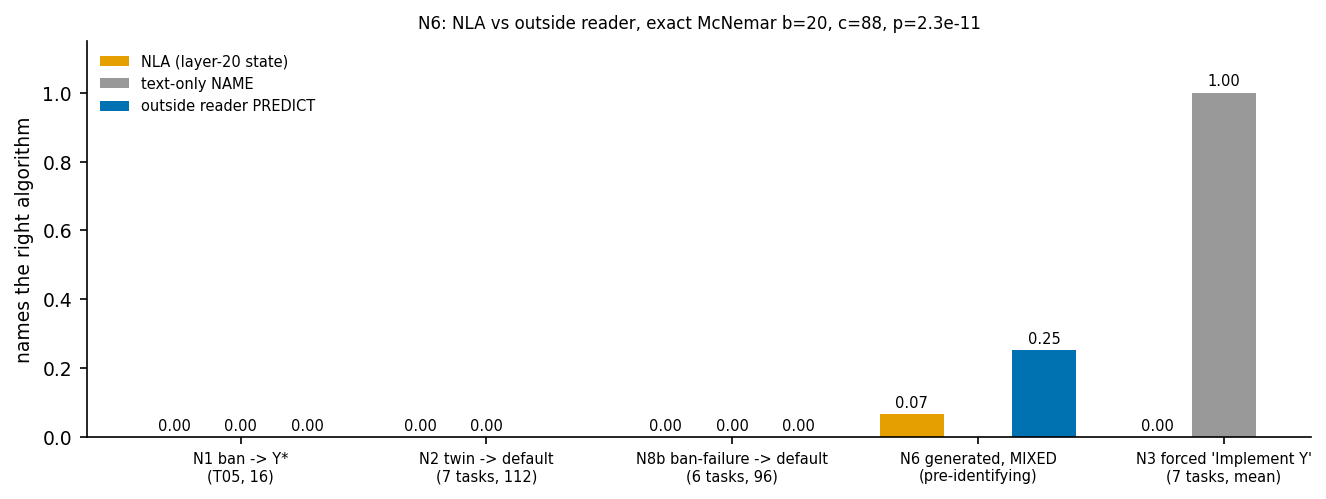

In [32]:
blocks = [("N1 ban -> Y*\n(T05, 16)", READOUT["N1"], READOUT["N1"]["y_rate"]["rate"], READOUT["N1_predict"]["y_rate"]["rate"]),
          ("N2 twin -> default\n(7 tasks, 112)", READOUT["N2_default"], READOUT["N2_default"]["y_rate"]["rate"], None),
          ("N8b ban-failure -> default\n(6 tasks, 96)", READOUT["N8b_banfail_default_vs_predict"],
           READOUT["N8b_banfail_default_vs_name"]["y_rate"]["rate"], READOUT["N8b_banfail_default_vs_predict"]["y_rate"]["rate"]),
          ("N6 generated, MIXED\n(pre-identifying)", READOUT["N6_per_sample"], None, READOUT["N6_per_sample"]["y_rate"]["rate"])]
n3_nla = np.mean([v["nla"]["rate"] for v in READOUT["N3_forced"]["tasks"].values()])
n3_txt = np.mean([v["text_only"]["rate"] for v in READOUT["N3_forced"]["tasks"].values()])
fig, ax = plt.subplots(figsize=(9, 3.4))
xs = np.arange(len(blocks) + 1)
nla = [b[1]["x_rate"]["rate"] for b in blocks] + [n3_nla]
name = [b[2] for b in blocks] + [n3_txt]
pred = [b[3] for b in blocks] + [None]
for off, vals, col, lab in ((-0.27, nla, PAL[1], "NLA (layer-20 state)"), (0.0, name, PAL[7], "text-only NAME"),
                            (0.27, pred, PAL[0], "outside reader PREDICT")):
    ax.bar([x + off for x, v in zip(xs, vals) if v is not None], [v for v in vals if v is not None], width=0.26,
           color=col, label=lab)
    for x, v in zip(xs, vals):
        if v is not None:
            ax.text(x + off, v + 0.02, f"{v:.2f}", ha="center", fontsize=7)
ax.set_xticks(xs, [b[0] for b in blocks] + ["N3 forced 'Implement Y'\n(7 tasks, mean)"], fontsize=7)
ax.set_ylim(0, 1.15)
ax.set_ylabel("names the right algorithm")
ax.set_title(f"N6: NLA vs outside reader, exact McNemar b={READOUT['N6_per_sample']['b']}, "
             f"c={READOUT['N6_per_sample']['c']}, p={READOUT['N6_per_sample']['p']:.1e}", fontsize=8)
ax.legend(fontsize=7, frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

### What this notebook does not recompute: the causal arm and the exploratory controls

The causal programs were generated on the GPU and are not in the demo data: `nla_causal` and
`nla_causal_exploratory` are separate datasets of the artifact. Their results are shown below **as reported** in
`results/causal.json` and `results/causal_exploratory_followup.json`, drawn with the artifact's own `f5_causal` and
`f9_gen_dose` (inputs swapped to the reported dicts). The exploratory *local control* is reported too: it reads the
state *at* the algorithm-name token.

- **Pre-registered (F5).** The edit at the four prefill positions, ×1/×2/×4 over N = 30 CRN pairs, fails on all four
  tasks. Nothing rises above C0, the unedited twin.
- **Exploratory (F9).** The edit is added at READ and at generated tokens 1–64, at larger doses. On T06 it moves the
  choice to Floyd: 0.76 against 0.28 for C0 at ×8 (25:1 over 50 pairs). This replicates on fresh slots and beats the
  matched random, unrelated-word and round-trip controls. On T05, brute force rises at ×8–×16. Prompting stays the
  ceiling: "Implement Y" gives 0.90–1.00.

pre-registered causal arm (reported): 0 of 4 tasks pass; rule: PASS(task) iff for some dose EDIT-RT >= 0.20, Holm(3) p < 0.05, and EDIT - max(UNREL, RAND) >= 0.10; claim iff >= 2 tasks


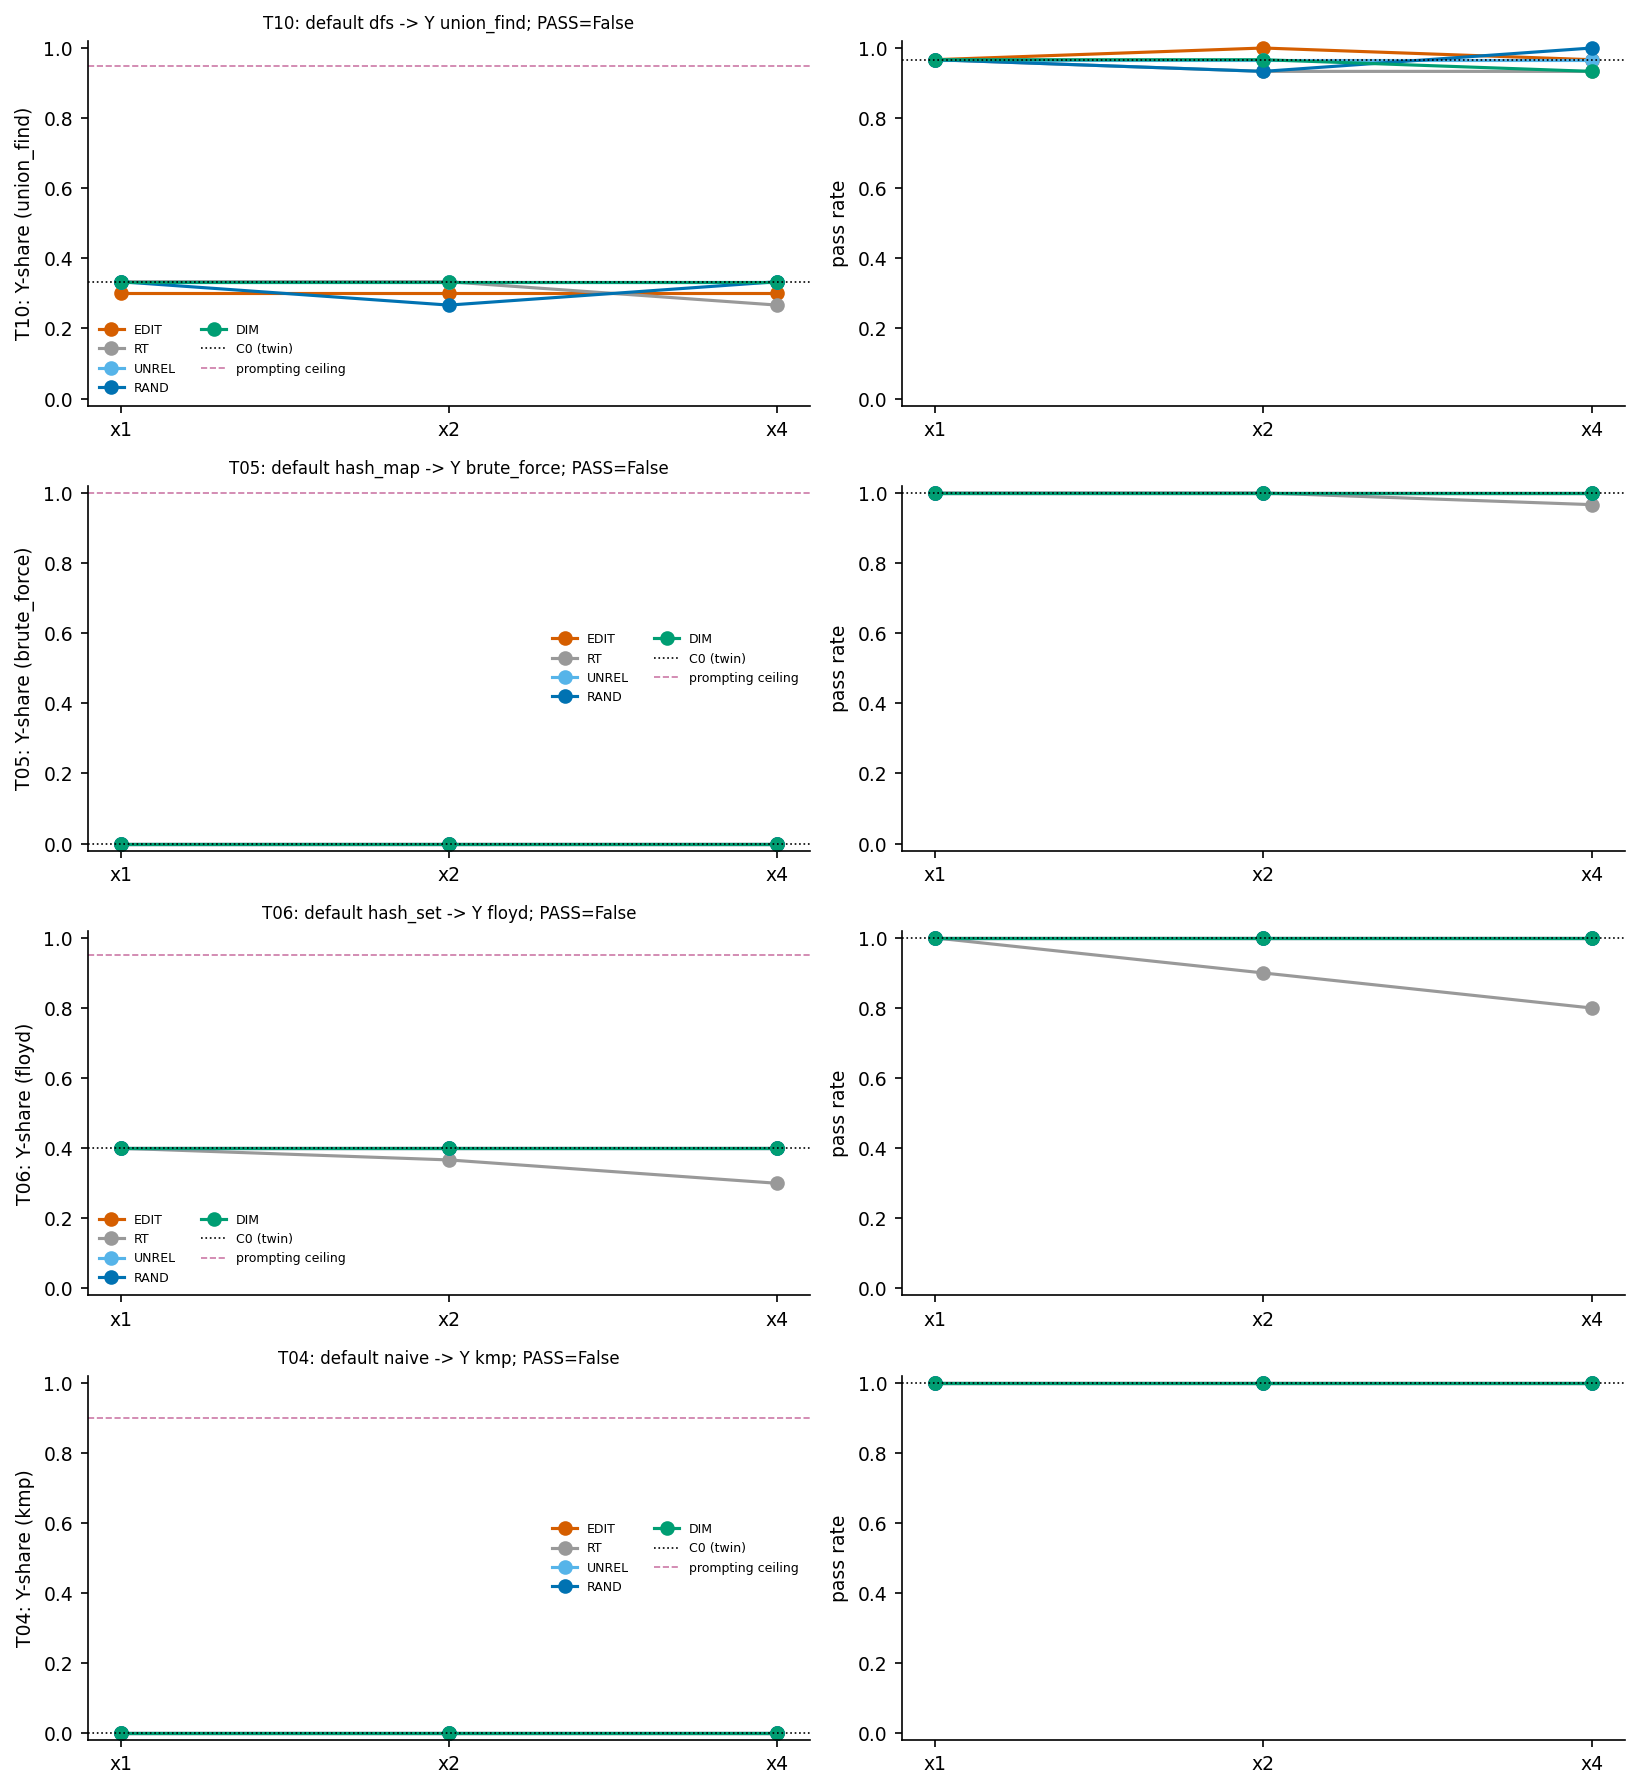

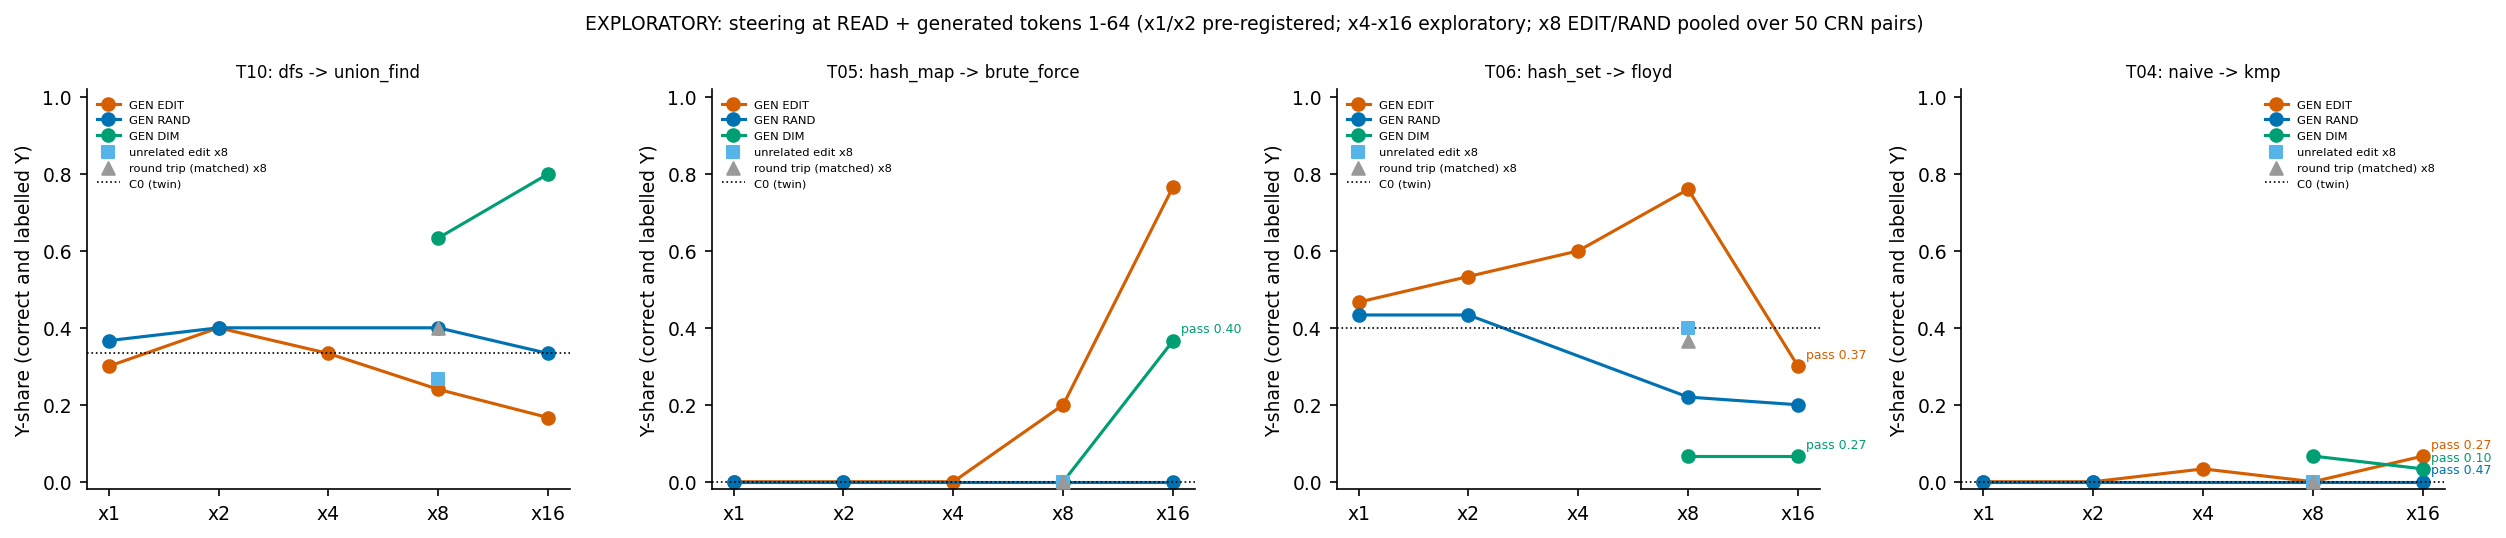

EXPLORATORY local control (reported): read AT the algorithm-name token (NAME) or at that sentence's end (SENT)


,n_states,planned_majority,mentioned_majority
forced|NAME,75.0,0.480,0.800
forced|SENT,75.0,0.107,0.267
ban|NAME,35.0,0.057,0.886
ban|SENT,35.0,0.000,0.057


In [33]:
def f5_causal() -> None:
    c = REPORTED["causal"]   # original: p = RESULTS_DIR / "causal.json"; if not p.exists(): return; c = read_json(p)
    tasks = list(c["tasks"])
    if not tasks:
        return
    fig, axes = plt.subplots(len(tasks), 2, figsize=(11, 3 * len(tasks)), squeeze=False)
    for i, t in enumerate(tasks):
        T = c["tasks"][t]
        for kind, col in (("EDIT", PAL[3]), ("RT", PAL[7]), ("UNREL", PAL[5]), ("RAND", PAL[0]), ("DIM", PAL[2])):
            xs, ys, ps = [], [], []
            for d in (1, 2, 4):
                cell = T["cells"].get(f"PRE_{kind}_x{d}")
                if cell:
                    xs.append(d)
                    ys.append(cell["Y_share"]["rate"])
                    ps.append(cell["pass_rate"]["rate"])
            if xs:
                axes[i][0].plot(xs, ys, marker="o", color=col, label=kind)
                axes[i][1].plot(xs, ps, marker="o", color=col, label=kind)
        y0 = T["C0"]["Y_share"]["rate"]
        axes[i][0].axhline(y0, color="k", ls=":", lw=0.8, label="C0 (twin)")
        axes[i][1].axhline(T["C0"]["pass_rate"]["rate"], color="k", ls=":", lw=0.8)
        ceil = T.get("prompting_ceiling_forced_adherence")
        if ceil is not None:
            axes[i][0].axhline(ceil, color=PAL[4], ls="--", lw=0.8, label="prompting ceiling")
        for ax in axes[i]:
            ax.set_xscale("log", base=2)
            ax.set_xticks([1, 2, 4], ["x1", "x2", "x4"])
            ax.set_ylim(-0.02, 1.02)
        axes[i][0].set_ylabel(f"{t}: Y-share ({T['Y']})")
        axes[i][1].set_ylabel("pass rate")
        axes[i][0].legend(fontsize=6, frameon=False, ncol=2)
        axes[i][0].set_title(f"{t}: default {T['default']} -> Y {T['Y']}; PASS={T['pass']}", fontsize=8)
    save(fig, "F5_causal_dose_response")


def f9_gen_dose() -> None:
    """EXPLORATORY: Y-share vs dose at the generated-token site (READ + generated positions 1-64), CRN slots 0-5
    (x8 pooled with the replication on slots 6-9 where available)."""
    c = REPORTED["causal"]                          # original: read_json(RESULTS_DIR / "causal.json")
    f = REPORTED["causal_exploratory_followup"]     # original: read_json(RESULTS_DIR / "causal_exploratory_followup.json")
    tasks = list(f["tasks"])
    fig, axes = plt.subplots(1, len(tasks), figsize=(4.2 * len(tasks), 3.6), squeeze=False)
    for ax, t in zip(axes[0], tasks):
        F = f["tasks"][t]["cells"]
        C = c["tasks"][t]["cells"]
        def ys(kind):
            xs, vals, pr = [], [], []
            for d in (1, 2, 4, 8, 16):
                cell = None
                if d in (1, 2) and f"GEN_{kind}_x{d}" in C:
                    v = C[f"GEN_{kind}_x{d}"]
                    cell = (v["Y_share"]["rate"], v["pass_rate"]["rate"])
                for nm in (f"EXP2_GEN_{kind}_x{d}", f"EXP_GEN_{kind}_x{d}"):
                    if cell is None and nm in F:
                        cell = (F[nm]["Y_share"], F[nm]["pass_rate"])
                if d == 8 and kind in ("EDIT", "RAND") and f"pooled_GEN_{kind}_x8_vs_C0" in f["tasks"][t]:
                    cell = (f["tasks"][t][f"pooled_GEN_{kind}_x8_vs_C0"]["Y_share"], cell[1] if cell else None)
                if cell is not None:
                    xs.append(d); vals.append(cell[0]); pr.append(cell[1])
            return xs, vals, pr
        for kind, col in (("EDIT", PAL[3]), ("RAND", PAL[0]), ("DIM", PAL[2])):
            xs, vals, pr = ys(kind)
            if xs:
                ax.plot(xs, vals, marker="o", color=col, label=f"GEN {kind}")
                for x_, y_, p_ in zip(xs, vals, pr):
                    if p_ is not None and p_ < 0.8:
                        ax.annotate(f"pass {p_:.2f}", (x_, y_), textcoords="offset points", xytext=(4, 4), fontsize=6, color=col)
        for nm, mk, lab in (("EXP2_GEN_UNREL_x8", "s", "unrelated edit x8"), ("EXP2_GEN_RTM_x8", "^", "round trip (matched) x8")):
            if nm in F:
                ax.scatter([8], [F[nm]["Y_share"]], marker=mk, color=PAL[5] if mk == "s" else PAL[7], zorder=3, label=lab)
        ax.axhline(c["tasks"][t]["C0"]["Y_share"]["rate"], color="k", ls=":", lw=0.8, label="C0 (twin)")
        ax.set_xscale("log", base=2)
        ax.set_xticks([1, 2, 4, 8, 16], ["x1", "x2", "x4", "x8", "x16"])
        ax.set_ylim(-0.02, 1.02)
        ax.set_title(f"{t}: {c['tasks'][t]['default']} -> {c['tasks'][t]['Y']}", fontsize=8)
        ax.set_ylabel("Y-share (correct and labelled Y)")
        ax.legend(fontsize=5.5, frameon=False)
    fig.suptitle("EXPLORATORY: steering at READ + generated tokens 1-64 (x1/x2 pre-registered; x4-x16 exploratory; "
                 "x8 EDIT/RAND pooled over 50 CRN pairs)", fontsize=9)
    save(fig, "F9_gen_site_dose_exploratory")


rc = REPORTED["causal"]
print(f"pre-registered causal arm (reported): {rc['n_tasks_pass']} of {len(rc['tasks'])} tasks pass; rule: {rc['rule']}")
f5_causal()
f9_gen_dose()
lc = META["reported_local_control"]
print("EXPLORATORY local control (reported): read AT the algorithm-name token (NAME) or at that sentence's end (SENT)")
pd.DataFrame({k: {kk: round(v[kk], 3) for kk in ("n_states", "planned_majority", "mentioned_majority")}
              for k, v in lc["aggregates"].items()}).T

## Takeaways

- **Behaviour.** Qwen2.5-7B mostly ignores "do not use X". Only T05 yields a substitute (brute force, 32/46). On T10
  the ban *raises* the banned DFS, and "X is not allowed here" (W4) fails 70/70. A ban names the default, and in
  activation space the ban state often moves *toward* the banned algorithm's own "Implement" direction (F8: T05, T06,
  R6). It does not move to the edge of that algorithm's region.
- **The instrument works, but only partly on code.** The pipeline reproduces the checkpoint on its own kind of text.
  On the task states FVE_ref is 0.51 (PARTIAL), because code is out of distribution for this NLA.
- **No verbalised plan before the code.** Every pre-registered prefill readout is exactly 0: N1 0/16, N2 0/112, N8b
  0/96. N3 also fails: the forced "Implement Y" states never call Y planned, while the visible text gets 1.0. The
  explanations describe the format line instead.
- **Generated tokens.** Once code starts, the NLA sometimes names the realised algorithm before the text does (up to
  0.28). The outside reader still beats it per sample: 0.25 against 0.07 (McNemar 20:88, p ≈ 2e-11).
- **Steering.** The pre-registered prefill edit fails on all four tasks. The exploratory generated-token edit works on
  T06 and T05 at large doses, against matched controls, but stays below simple prompting ("Implement Y": 0.90–1.00).
  No push or prompt produced a genuinely novel algorithm.
- **Caveats.** One model, one layer and one AV checkpoint; code is out of distribution for the NLA; the steering
  results are exploratory.

**Settings and a full re-run.** The configuration cell already holds the artifact's own resampling settings
(`N_BOOT = 2000`, `N_PERM_SWAP = 10000`, `N_HILL_DRAWS = 1000`, `N_PLACEBO_SWAPS = 2000`). A full re-run of the GPU
and API stages needs four things:
- the artifact repository;
- one GPU with at least 22 GB;
- the three checkpoints at the pinned revisions;
- an OpenRouter key.

Then run `python method.py` as described in the artifact's `reproducibility.md`: about 2 GPU-hours and USD 2 of
judge calls.